#  Klasifikasi dan Regresi Lokalisasi Indoor Berbasis RSSI Wi-Fi

Tim R&D PT. Sinyal Nusantara sedang mengembangkan layanan navigasi di dalam gedung untuk sebuah kampus besar. GPS tidak andal di dalam ruangan, sehingga posisi pengguna harus diperkirakan dari kekuatan sinyal (RSSI) access point Wi-Fi yang tertangkap ponsel.
Ibu Laras, manajer produk, ingin tahu apakah sidik jari (fingerprint) RSSI cukup untuk menebak gedung dan lantai pengguna, sekaligus memperkirakan koordinatnya dengan galat sekecil mungkin.

## PROSES 1 — EDA DAN DATA PREPROCESSING

### 1. Import Library

Mengimpor library untuk manipulasi data, visualisasi, statistik, dan preprocessing.

In [1]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


### 2. Load dataset
Tujuan: Membaca dataset training dan validation yang sudah disediakan.

In [2]:
train_path = "data/trainingData.csv"
validation_path = "data/validationData.csv"

df_train = pd.read_csv(train_path)
df_validation = pd.read_csv(validation_path)

print("Training Dataset:", df_train.shape)
print("Validation Dataset:", df_validation.shape)

df_train.head()


Training Dataset: (19937, 529)
Validation Dataset: (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


### 3. Identifikasi kolom
Tujuan: Memisahkan fitur RSSI, target, dan metadata.

Disini tidak boleh menggunakan USERID, PHONEID, dan TIMESTAMP sebagai fitur prediksi posisi karena dapat menyebabkan model mempelajari identitas perangkat atau pola waktu, bukan fingerprint Wi-Fi.

Catatan: SPACEID dan RELATIVEPOSITION juga tidak kita gunakan sebagai fitur prediksi utama. Keduanya berpotensi memberikan informasi lokasi secara langsung.

In [3]:
# Fitur RSSI
rssi_features = [
    col for col in df_train.columns
    if col.startswith("WAP")
]

# Target klasifikasi
classification_targets = [
    "BUILDINGID",
    "FLOOR"
]

# Target regresi
regression_targets = [
    "LONGITUDE",
    "LATITUDE"
]

# Metadata
metadata_features = [
    "SPACEID",
    "RELATIVEPOSITION",
    "USERID",
    "PHONEID",
    "TIMESTAMP"
]

print("Jumlah fitur RSSI:", len(rssi_features))
print("Target klasifikasi:", classification_targets)
print("Target regresi:", regression_targets)
print("Metadata:", metadata_features)

assert len(rssi_features) == 520

Jumlah fitur RSSI: 520
Target klasifikasi: ['BUILDINGID', 'FLOOR']
Target regresi: ['LONGITUDE', 'LATITUDE']
Metadata: ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


### 4. Pemeriksaan struktur dataset
Tujuan: Memastikan kedua dataset memiliki struktur kolom yang konsisten dan memahami tipe datanya.

Interpretasi:
- Pastikan semua fitur RSSI memiliki tipe numerik.
- Pastikan target tersedia di kedua dataset.
- Pastikan tidak terdapat perbedaan nama kolom.
- Jika terdapat tipe data tidak sesuai, lakukan konversi sebelum preprocessing.

In [4]:
# Pemeriksaan Struktur Training Dataset

print("=== TRAINING DATA ===")
df_train.info()

print("\n=== TIPE DATA ===")
display(df_train.dtypes.value_counts())

print("\n=== JUMLAH KOLOM ===")
print("Total kolom:", len(df_train.columns))

print("\n=== FITUR RSSI ===")
print("Jumlah fitur RSSI:", len(rssi_features))

print("\n=== TARGET ===")

target_columns = (
    classification_targets + regression_targets
)

display(df_train[target_columns].dtypes)

print("\n=== MISSING TARGET ===")
display(df_train[target_columns].isnull().sum())

=== TRAINING DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 19937 entries, 0 to 19936
Columns: 529 entries, WAP001 to TIMESTAMP
dtypes: float64(2), int64(527)
memory usage: 80.5 MB

=== TIPE DATA ===


int64      527
float64      2
Name: count, dtype: int64


=== JUMLAH KOLOM ===
Total kolom: 529

=== FITUR RSSI ===
Jumlah fitur RSSI: 520

=== TARGET ===


BUILDINGID      int64
FLOOR           int64
LONGITUDE     float64
LATITUDE      float64
dtype: object


=== MISSING TARGET ===


BUILDINGID    0
FLOOR         0
LONGITUDE     0
LATITUDE      0
dtype: int64

### 5. Pemeriksaan duplikasi
Tujuan: Mengidentifikasi baris yang memiliki seluruh nilai sama.

In [5]:
# Pemeriksaan Duplikasi Training

duplicate_train = df_train.duplicated().sum()

duplicate_percentage = (
    duplicate_train / len(df_train) * 100
)

print("Jumlah duplikasi:", duplicate_train)

print(
    "Persentase duplikasi:",
    round(duplicate_percentage, 2),
    "%"
)

Jumlah duplikasi: 637
Persentase duplikasi: 3.2 %


### 6. Missing value aktual
Tujuan: Memeriksa apakah terdapat nilai kosong dalam format NaN.

In [6]:
# Missing Value Analysis

missing_train = df_train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_train,
    "Missing Percentage": (
        missing_train / len(df_train) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

print(
    "Total missing value:",
    missing_train.sum()
)

display(missing_summary)

Total missing value: 0


,Missing Count,Missing Percentage


### 7. Analisis nilai RSSI +100
Tujuan: Mengukur jumlah dan persentase WAP yang tidak terdeteksi.

In [7]:
rssi_train = df_train[rssi_features]

sentinel_count = (rssi_train == 100).sum()
sentinel_percentage = (rssi_train == 100).mean() * 100

sentinel_summary = pd.DataFrame({
    "WAP": rssi_features,
    "Sentinel Count": sentinel_count.values,
    "Sentinel Percentage": sentinel_percentage.values
})

sentinel_summary = sentinel_summary.sort_values(
    by="Sentinel Percentage",
    ascending=False
)

display(sentinel_summary.head(15))

print(
    "Rata-rata persentase sentinel:",
    round(sentinel_percentage.mean(), 2),
    "%"
)

,WAP,Sentinel Count,Sentinel Percentage
519,WAP520,19937,100.0
496,WAP497,19937,100.0
490,WAP491,19937,100.0
486,WAP487,19937,100.0
487,WAP488,19937,100.0
484,WAP485,19937,100.0
481,WAP482,19937,100.0
246,WAP247,19937,100.0
450,WAP451,19937,100.0
457,WAP458,19937,100.0


Rata-rata persentase sentinel: 96.54 %


### 8. Visualisasi Missing RSSI

Visualisasi ini membantu mengetahui apakah sebagian besar access point memiliki tingkat deteksi yang sangat rendah.
informasi ini digunakan untuk menentukan strategi seleksi fitur.

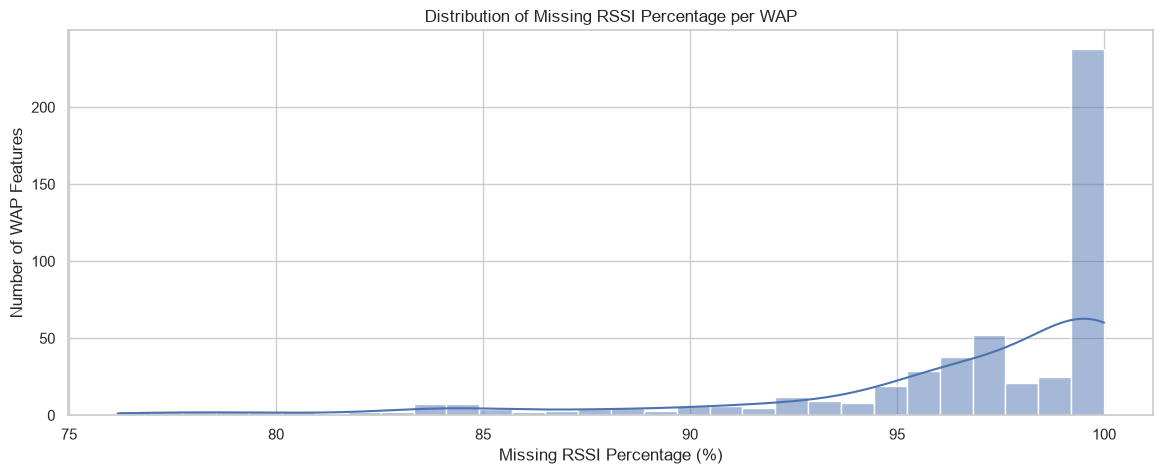

In [8]:
plt.figure(figsize=(14, 5))

sns.histplot(
    sentinel_percentage,
    bins=30,
    kde=True
)

plt.title("Distribution of Missing RSSI Percentage per WAP")
plt.xlabel("Missing RSSI Percentage (%)")
plt.ylabel("Number of WAP Features")

plt.show()

### 9. Identifikasi WAP konstan
Tujuan: Menemukan fitur yang tidak memiliki variasi informasi.

pada bagian ini akan membandingkan dua skenario:
- Full features: seluruh 520 fitur RSSI.
- Reduced features: fitur konstan dihapus.

Penghapusan fitur konstan dilakukan berdasarkan training saja.

In [9]:
constant_features = [
    col for col in rssi_features
    if df_train[col].nunique() == 1
]

print("Jumlah fitur konstan:", len(constant_features))
print("Daftar fitur konstan:")
print(constant_features)

print(
    "Persentase fitur konstan:",
    round(len(constant_features) / len(rssi_features) * 100, 2),
    "%"
)

Jumlah fitur konstan: 55
Daftar fitur konstan:
['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158', 'WAP159', 'WAP160', 'WAP215', 'WAP217', 'WAP226', 'WAP227', 'WAP238', 'WAP239', 'WAP240', 'WAP241', 'WAP242', 'WAP243', 'WAP244', 'WAP245', 'WAP246', 'WAP247', 'WAP254', 'WAP293', 'WAP296', 'WAP301', 'WAP303', 'WAP304', 'WAP307', 'WAP333', 'WAP349', 'WAP353', 'WAP360', 'WAP365', 'WAP416', 'WAP419', 'WAP423', 'WAP429', 'WAP433', 'WAP438', 'WAP441', 'WAP442', 'WAP444', 'WAP445', 'WAP451', 'WAP458', 'WAP482', 'WAP485', 'WAP487', 'WAP488', 'WAP491', 'WAP497', 'WAP520']
Persentase fitur konstan: 10.58 %


### 10. Distribusi BUILDINGID
Tujuan: Mengetahui jumlah sampel setiap kelas gedung.

BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64


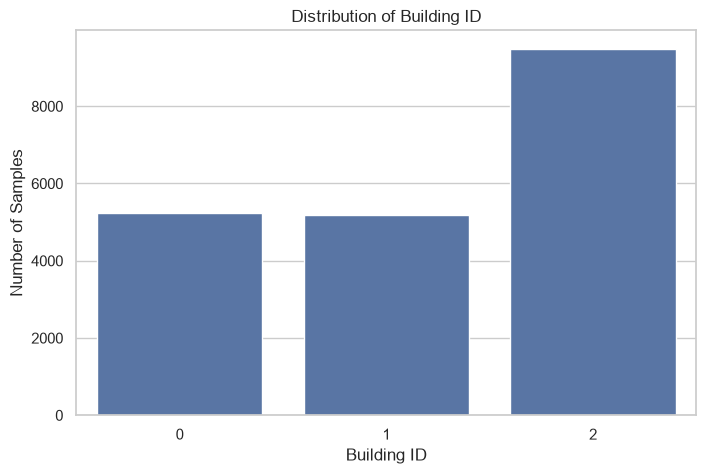

In [10]:
building_counts = df_train["BUILDINGID"].value_counts().sort_index()

print(building_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    order=sorted(df_train["BUILDINGID"].unique())
)

plt.title("Distribution of Building ID")
plt.xlabel("Building ID")
plt.ylabel("Number of Samples")

plt.show()

### 11. Distribusi FLOOR
Tujuan: Memeriksa distribusi kelas lantai.

FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64


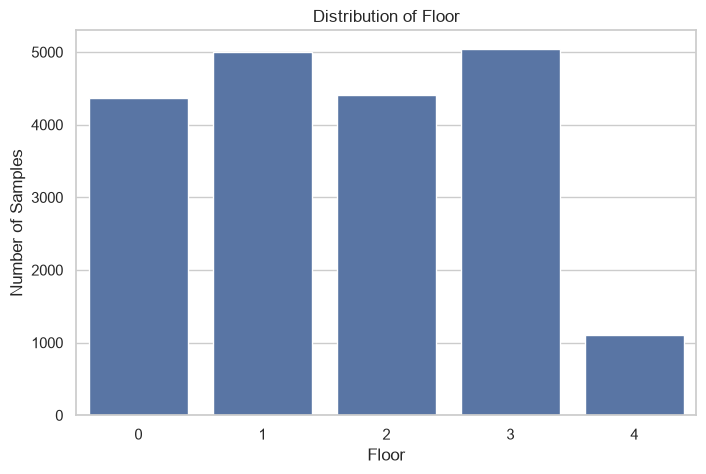

In [11]:
floor_counts = df_train["FLOOR"].value_counts().sort_index()

print(floor_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="FLOOR",
    order=sorted(df_train["FLOOR"].unique())
)

plt.title("Distribution of Floor")
plt.xlabel("Floor")
plt.ylabel("Number of Samples")

plt.show()

### 12. Statistik deskriptif RSSI
Tujuan: Mengetahui karakteristik nilai RSSI, termasuk nilai minimum, maksimum, rata-rata, median, dan standar deviasi.

Penting: nilai +100 masih dianggap sebagai sentinel, sehingga kita keluarkan sementara dari statistik RSSI aktual.

Interpretasi:
- mean: rata-rata kekuatan sinyal.
- std: variasi kekuatan sinyal.
- min dan max: rentang nilai RSSI yang terdeteksi.
- 50%: median RSSI.

Nilai count menunjukkan jumlah observasi RSSI yang benar-benar terdeteksi.

In [12]:
rssi_clean_eda = df_train[rssi_features].replace(100, np.nan)

rssi_statistics = rssi_clean_eda.describe().T


rssi_statistics[
     ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)


,count,mean,std,min,25%,50%,75%,max
WAP001,18.0,-95.33,1.14,-97.0,-96.0,-96.0,-94.25,-93.0
WAP002,19.0,-87.89,2.05,-90.0,-90.0,-86.0,-86.00,-86.0
WAP003,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP004,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP005,40.0,-92.52,2.15,-97.0,-94.0,-92.0,-91.75,-89.0
...,...,...,...,...,...,...,...,...
WAP516,3038.0,-72.56,14.61,-101.0,-84.0,-74.0,-63.00,0.0
WAP517,4543.0,-76.02,12.06,-101.0,-85.0,-77.0,-70.00,0.0
WAP518,22.0,-91.55,3.73,-97.0,-95.0,-91.0,-88.00,-87.0
WAP519,3.0,-96.00,1.73,-97.0,-97.0,-97.0,-95.50,-94.0


### 13. Distribusi nilai RSSI
Tujuan: Melihat pola distribusi kekuatan sinyal Wi-Fi.

Interpretasi:
Distribusi ini membantu mengetahui rentang RSSI yang paling sering diterima perangkat.
Semakin mendekati 0 dBm, sinyal semakin kuat. Semakin negatif nilainya, sinyal semakin lemah.

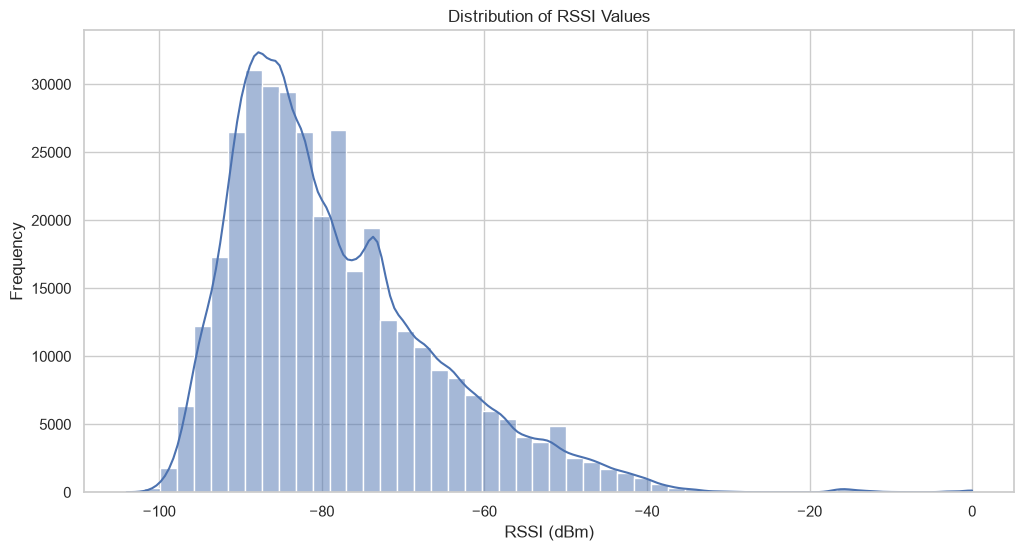

In [13]:
rssi_values = rssi_clean_eda.values.flatten()
rssi_values = rssi_values[~np.isnan(rssi_values)]

plt.figure(figsize=(12, 6))

sns.histplot(
    rssi_values,
    bins=50,
    kde=True
)

plt.title("Distribution of RSSI Values")
plt.xlabel("RSSI (dBm)")
plt.ylabel("Frequency")

plt.show()

### 14. Distribusi RSSI berdasarkan gedung
Tujuan: Mengidentifikasi apakah karakteristik fingerprint RSSI berbeda antar gedung.

Interpretasi:
Apabila distribusi RSSI berbeda antar gedung, fingerprint Wi-Fi berpotensi memberikan informasi yang berguna untuk klasifikasi gedung.

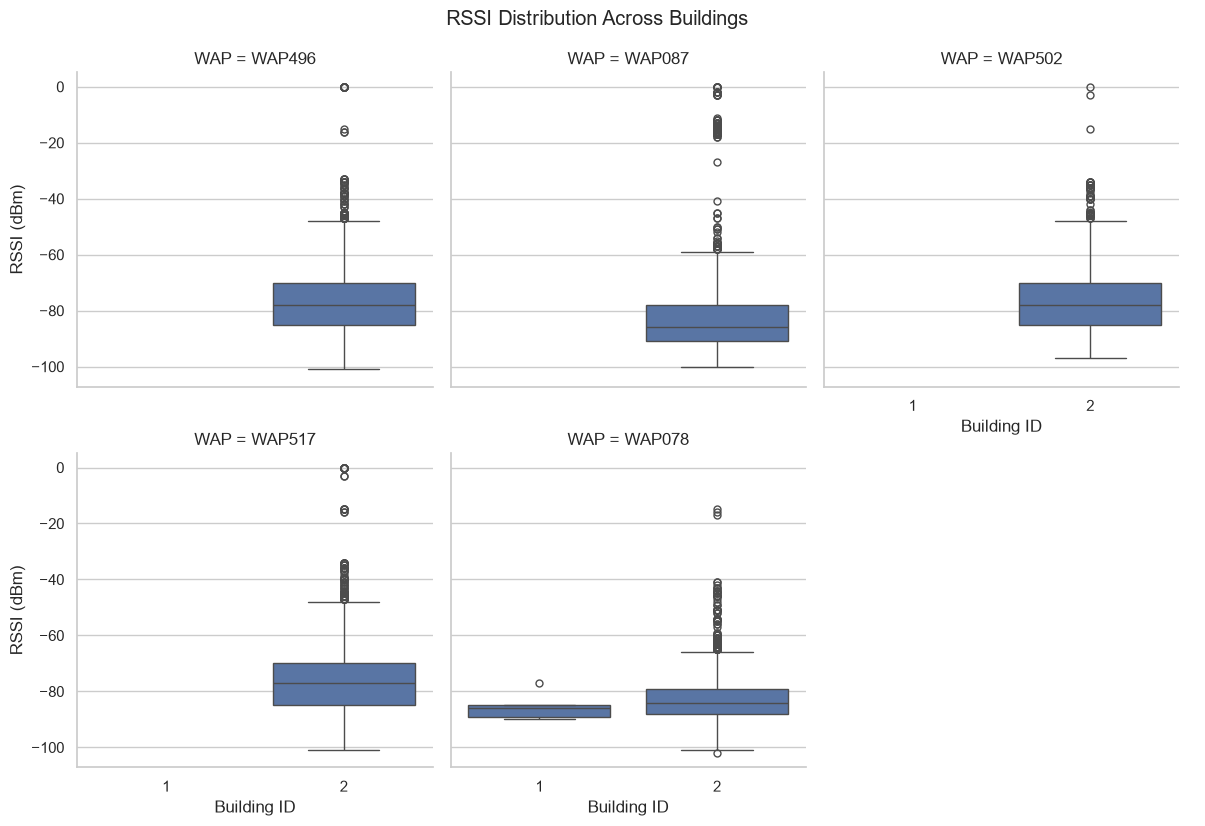

In [14]:
sample_size = min(5, len(rssi_features))

selected_waps = (
    df_train[rssi_features]
    .replace(100, np.nan)
    .notna()
    .sum()
    .sort_values(ascending=False)
    .head(sample_size)
    .index
)

plot_data = df_train[
    list(selected_waps) + ["BUILDINGID"]
].melt(
    id_vars="BUILDINGID",
    var_name="WAP",
    value_name="RSSI"
)

plot_data = plot_data[plot_data["RSSI"] != 100]

g = sns.catplot(
    data=plot_data,
    x="BUILDINGID",
    y="RSSI",
    col="WAP",
    kind="box",
    col_wrap=3,
    height=4,
    sharey=True
)

g.set_axis_labels("Building ID", "RSSI (dBm)")
g.fig.suptitle(
    "RSSI Distribution Across Buildings",
    y=1.03
)

plt.show()

### 15. Deteksi outlier menggunakan IQR
Tujuan: Mengidentifikasi nilai RSSI ekstrem menggunakan metode Interquartile Range (IQR).

Rumus:

IQR = Q3 - Q1

Lower = Q1 - 1,5(IQR)

Upper = Q3 + 1,5(IQR)

ini berfungsi untuk menghitung outlier hanya dari RSSI yang terdeteksi, bukan sentinel +100.

Dalam konteks RSSI, nilai ekstrem dapat menjadi karakteristik fingerprint suatu lokasi. Dalam hal ini harus membedakan anomali pengukuran dengan variasi sinyal yang memang valid.

In [15]:
outlier_results = []

for col in rssi_features:

    values = df_train[col]
    values = values[values != 100]

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "WAP": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers,
        "Outlier Percentage": outliers / len(values) * 100
    })

outlier_df = pd.DataFrame(outlier_results)


outlier_df.sort_values(
    "Outlier Percentage",
     ascending=False
 ).head(20).round(2)


,WAP,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
419,WAP468,-95.00,-95.0,0.00,-95.00,-95.00,4,44.44
310,WAP343,-88.00,-88.0,0.00,-88.00,-88.00,3,33.33
204,WAP216,-85.00,-82.5,2.50,-88.75,-78.75,3,30.00
299,WAP331,-88.75,-88.0,0.75,-89.88,-86.88,3,25.00
385,WAP425,-91.25,-91.0,0.25,-91.62,-90.62,2,25.00
183,WAP194,-63.25,-51.5,11.75,-80.88,-33.88,2,25.00
362,WAP399,-85.00,-84.0,1.00,-86.50,-82.50,12,23.53
277,WAP309,-87.00,-87.0,0.00,-87.00,-87.00,2,22.22
152,WAP163,-89.00,-88.0,1.00,-90.50,-86.50,5,20.83
422,WAP471,-91.00,-91.0,0.00,-91.00,-91.00,1,20.00


### 16. Visualisasi outlier



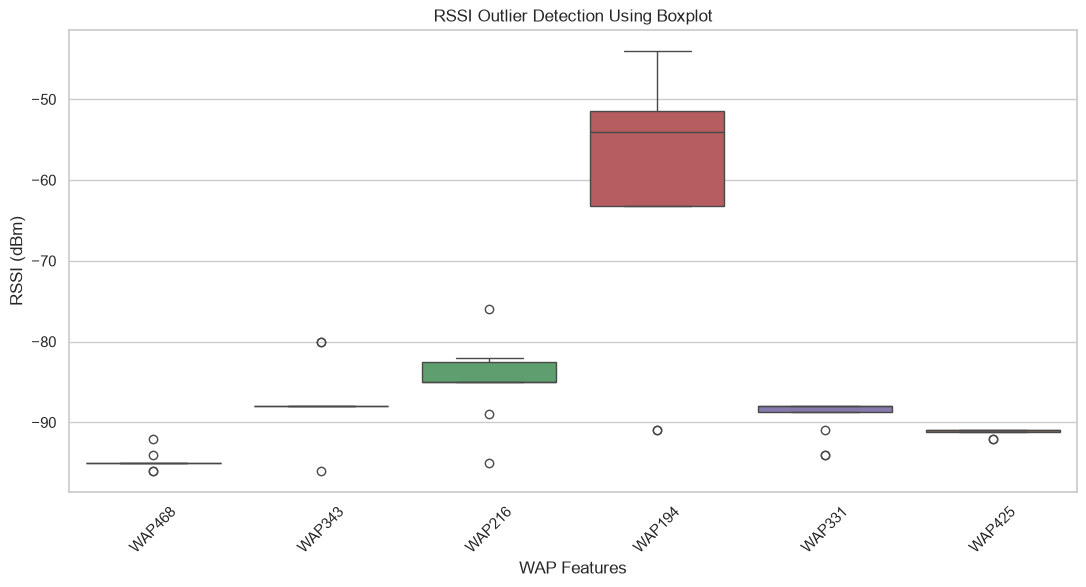

In [16]:
selected_outlier_waps = outlier_df.nlargest(
    6,
    "Outlier Percentage"
)["WAP"].tolist()

boxplot_data = df_train[selected_outlier_waps].replace(
    100,
    np.nan
)

plt.figure(figsize=(13, 6))

sns.boxplot(data=boxplot_data)

plt.title("RSSI Outlier Detection Using Boxplot")
plt.xlabel("WAP Features")
plt.ylabel("RSSI (dBm)")

plt.xticks(rotation=45)
plt.show()

### 17. Korelasi antarfitur RSSI
Tujuan: Mengetahui hubungan antar-WAP. Fitur yang memiliki korelasi tinggi mungkin membawa informasi yang serupa.

Untuk menjaga visualisasi tetap terbaca, gunakan 30 WAP dengan variasi terbesar setelah sentinel diubah menjadi NaN.

Interpretasi:
- Korelasi mendekati +1: hubungan positif kuat.
- Korelasi mendekati -1: hubungan negatif kuat.
- Korelasi mendekati 0: hubungan linear lemah.

Korelasi tinggi tidak otomatis berarti salah satu fitur harus dihapus.

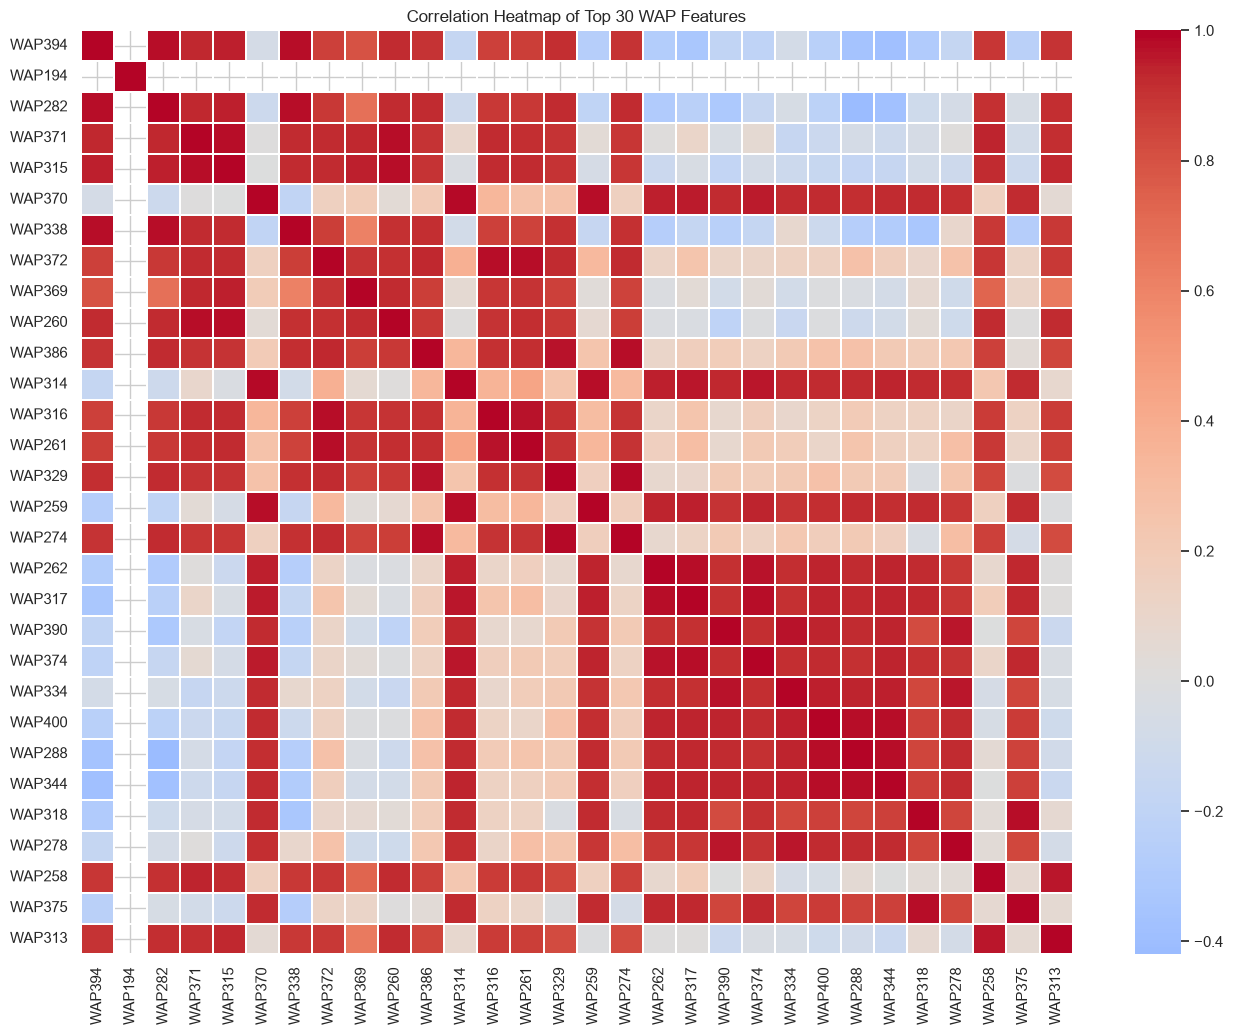

In [17]:
rssi_variance = (
    rssi_clean_eda
    .var()
    .sort_values(ascending=False)
)

top_30_waps = rssi_variance.head(30).index

correlation_matrix = (
    rssi_clean_eda[top_30_waps]
    .corr()
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Top 30 WAP Features")
plt.show()

### 18. Korelasi fitur dengan koordinat
Tujuan: Mengevaluasi hubungan linear RSSI dengan koordinat LONGITUDE dan LATITUDE.

Catatan: Korelasi Pearson hanya mengukur hubungan linear. Hubungan spasial yang lebih kompleks belum tentu terlihat melalui korelasi ini.

,LONGITUDE,LATITUDE
WAP262,0.439177,-0.489087
WAP344,0.415378,-0.581264
WAP288,0.412118,-0.473359
WAP374,0.406807,-0.471106
WAP400,0.394403,-0.506262
WAP317,0.373258,-0.439291
WAP334,0.248633,-0.563733
WAP314,0.221638,-0.479916
WAP390,0.198862,-0.568921
WAP375,0.180140,-0.223652


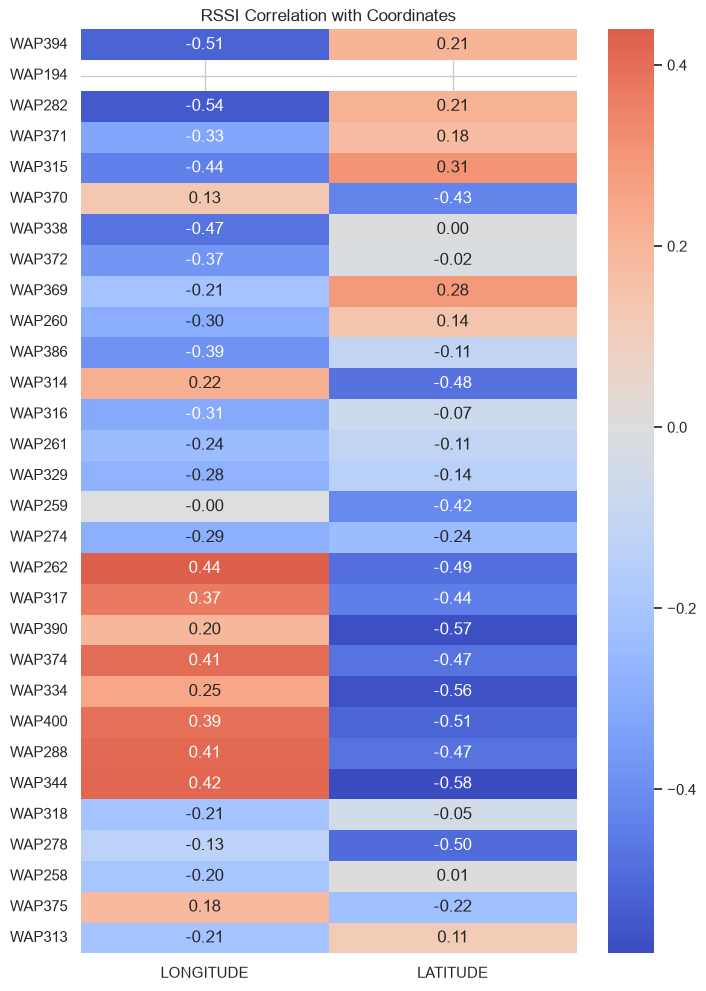

In [18]:
correlation_data = df_train[
    list(top_30_waps) + [
        "LONGITUDE",
        "LATITUDE"
    ]
].replace(100, np.nan)

target_correlation = (
    correlation_data.corr()[["LONGITUDE", "LATITUDE"]]
    .iloc[:-2]
)

display(
    target_correlation
    .sort_values("LONGITUDE", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 12))

sns.heatmap(
    target_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("RSSI Correlation with Coordinates")
plt.show()

### 19. Distribusi koordinat LONGITUDE dan LATITUDE
Tujuan: Memahami sebaran posisi pengguna berdasarkan koordinat geografis.

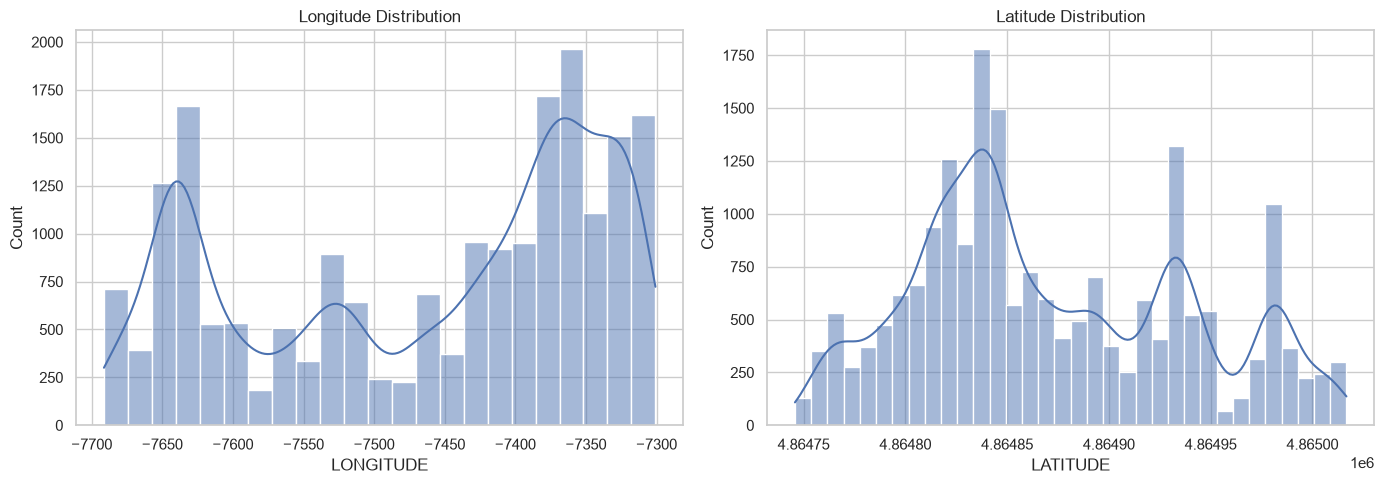

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_train["LONGITUDE"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Longitude Distribution")

sns.histplot(
    df_train["LATITUDE"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Latitude Distribution")

plt.tight_layout()
plt.show()

### 20. Visualisasi sebaran lokasi

Interpretasi:

Visualisasi ini membantu melihat apakah koordinat antar gedung membentuk kelompok spasial yang berbeda.

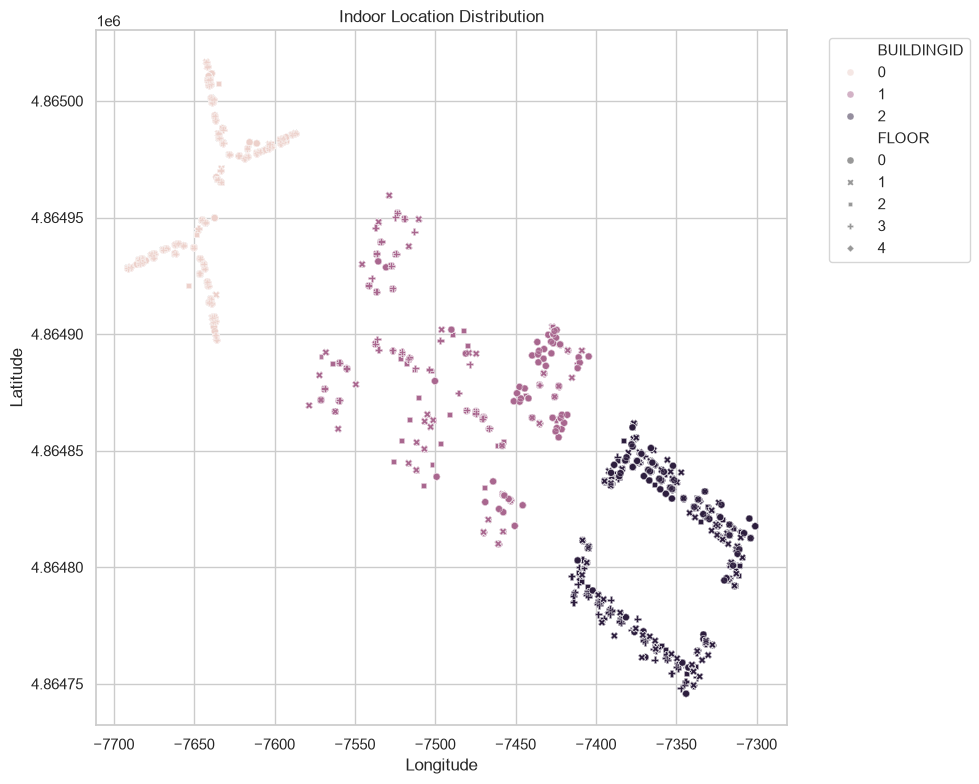

In [20]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df_train,
    x="LONGITUDE",
    y="LATITUDE",
    hue="BUILDINGID",
    style="FLOOR",
    alpha=0.5,
    s=25
)

plt.title("Indoor Location Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 21. Membuat salinan dataset
Tujuan: Mempertahankan dataset asli agar tidak berubah selama proses preprocessing.

In [21]:
# Membuat dataset khusus modeling dengan menghapus
# baris yang identik sepenuhnya

df_train_model = df_train.drop_duplicates(
    keep="first"
).copy()


# Menampilkan hasil penanganan duplikasi

print("=== PEMERIKSAAN DUPLIKASI ===")
print("Jumlah data awal:", len(df_train))
print("Jumlah data setelah deduplikasi:", len(df_train_model))
print("Jumlah baris duplikat yang dihapus:",
      len(df_train) - len(df_train_model))
print("Jumlah duplikat tersisa:",
      df_train_model.duplicated().sum())


# Memisahkan fitur RSSI dan target dari dataset modeling

X_train_raw = df_train_model[rssi_features].copy()

y_train = df_train_model[
    ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
].copy()


# Menampilkan ukuran dataset modeling

print("\n=== DATASET MODELING ===")
print("Training features:", X_train_raw.shape)
print("Training targets:", y_train.shape)

print("\nJumlah fitur RSSI:", X_train_raw.shape[1])
print("Jumlah data training:", X_train_raw.shape[0])

print("\nDataset asli (df_train) tetap dipertahankan.")

=== PEMERIKSAAN DUPLIKASI ===
Jumlah data awal: 19937
Jumlah data setelah deduplikasi: 19300
Jumlah baris duplikat yang dihapus: 637
Jumlah duplikat tersisa: 0

=== DATASET MODELING ===
Training features: (19300, 520)
Training targets: (19300, 4)

Jumlah fitur RSSI: 520
Jumlah data training: 19300

Dataset asli (df_train) tetap dipertahankan.


### 22. Metode 1: Sentinel replacement (-105 dBm)
Tujuan: Mengganti nilai +100 dengan -105 dBm.

Alasannya:
- RSSI yang tidak terdeteksi bukan berarti sinyal kuat.
- Nilai -105 dBm berada sedikit di bawah batas minimum RSSI yang tercatat.
- Metode ini mempertahankan informasi bahwa WAP tidak terdeteksi melalui nilai yang sangat rendah.

Catatan: Metode ini tidak memerlukan proses fitting. Namun, -105 merupakan keputusan domain yang perlu diuji dampaknya terhadap performa model.

In [22]:
def replace_sentinel(X):
    """
    Mengganti nilai sentinel +100 menjadi -105 dBm.
    Fungsi ini tidak melakukan fitting parameter.
    """

    return X.replace(100, -105)

### 23. Metode 2: Sentinel menjadi NaN dan imputasi median
Tujuan: Mengganti nilai tidak terdeteksi menjadi NaN, lalu mengisi nilai tersebut menggunakan median setiap WAP.

Median dihitung hanya dari data training pada setiap skenario pembagian data.

Data test internal menggunakan median yang diperoleh dari data training terkait melalui transformasi pipeline.

Pada evaluasi akhir, validation dataset menggunakan parameter imputasi yang dipelajari ketika model terbaik dilatih ulang menggunakan seluruh training dataset.

In [23]:
def convert_sentinel_to_nan(X):
    """
    Mengubah nilai sentinel +100 menjadi NaN.
    Imputasi median akan dilakukan di dalam pipeline.
    """

    return X.replace(100, np.nan)

### 24. Membandingkan kedua metode
Tujuan: Membandingkan dua strategi penanganan nilai RSSI yang tidak terdeteksi, yaitu Sentinel Replacement (-105 dBm) dan Median Imputation.

Kedua metode akan diuji menggunakan skenario pembagian data 80:20 dan 70:30.

Metode evaluasi:
1. Membandingkan karakteristik statistik hasil preprocessing.
2. Membandingkan performa model klasifikasi dan regresi.
3. Menggunakan metrik evaluasi yang sesuai dengan masing-masing tugas.

Perbandingan statistik deskriptif dilakukan pada data training setelah penanganan sentinel, tetapi sebelum scaling. Statistik yang dibandingkan meliputi mean, standar deviasi, nilai minimum, dan maksimum.

Parameter median hanya dihitung dari data training pada masing-masing skenario split. Data testing hanya digunakan untuk transformasi, bukan untuk menghitung parameter preprocessing.

Interpretasi: Perubahan statistik deskriptif memberikan gambaran mengenai karakteristik data setelah preprocessing. Namun, metode terbaik ditentukan berdasarkan hasil evaluasi model, bukan hanya berdasarkan nilai mean atau standar deviasi.

Tidak ada metode yang diasumsikan lebih baik sebelum eksperimen dilakukan.

### 25. Menghapus fitur konstan
Tujuan: Mengidentifikasi dan menangani fitur RSSI yang tidak memiliki variasi pada data training.

Metode: Seleksi fitur konstan dilakukan menggunakan VarianceThreshold di dalam pipeline preprocessing.

Seleksi fitur hanya di-fit menggunakan data training pada setiap skenario pembagian data. Data test internal menggunakan hasil seleksi fitur yang sama melalui transformasi.

Alasan metodologis: Fitur yang tidak memiliki variasi pada data training tidak memberikan informasi pembeda berdasarkan nilai fitur tersebut. Seleksi di dalam pipeline juga mencegah kebocoran informasi dari data test.

Jumlah fitur yang tersisa ditentukan berdasarkan hasil seleksi pada masing-masing skenario eksperimen.

### 26. Perbandingan Full Features dan Reduced Features

Penelitian ini membandingkan dua skenario penggunaan fitur:

1. Full features: menggunakan seluruh 520 fitur RSSI Wi-Fi.
2. Reduced features: mengurangi fitur menggunakan VarianceThreshold dengan threshold 0.0.

VarianceThreshold digunakan untuk menghapus fitur yang memiliki variansi nol pada data training. Fitur konstan tidak memberikan informasi pembeda antarobservasi sehingga dapat dihilangkan.

Berdasarkan pengujian preprocessing, diperoleh hasil:

- Split 80:20:
Metode sentinel: 520 menjadi 461 fitur.
Metode median: 520 menjadi 423 fitur.
- Split 70:30:
Metode sentinel: 520 menjadi 458 fitur.
Metode median: 520 menjadi 419 fitur.

Perbedaan jumlah fitur setelah reduksi menunjukkan bahwa hasil transformasi data memengaruhi fitur yang dipertahankan oleh VarianceThreshold.

Perbandingan ini dilakukan untuk mengetahui pengaruh metode preprocessing terhadap jumlah fitur. Penentuan apakah reduksi fitur meningkatkan performa prediksi akan dilakukan pada tahap eksperimen model.

### 27. Identifikasi dan Penanganan Target Kategorikal

Tujuan: Mengidentifikasi fitur kategorikal dan menentukan kebutuhan encoding berdasarkan karakteristik dataset.

Fitur input utama pada penelitian ini terdiri dari 520 fitur RSSI Wi-Fi yang seluruhnya berbentuk numerik sehingga tidak memerlukan proses encoding.

BUILDINGID dan FLOOR merupakan target klasifikasi yang sudah direpresentasikan menggunakan label numerik pada dataset asli.

Oleh karena itu, Label Encoding tidak diperlukan dan label asli dipertahankan untuk menjaga interpretasi kelas.

Kolom SPACEID, RELATIVEPOSITION, USERID, PHONEID, dan TIMESTAMP diperlakukan sebagai metadata dan tidak digunakan sebagai fitur input model.

Kesimpulan: Tidak diperlukan encoding kategorikal pada fitur input utama dalam penelitian ini.

### 28. Menghitung imbalance ratio

Tujuan: Mengukur tingkat ketidakseimbangan distribusi kelas pada target BUILDINGID dan FLOOR.

Rumus:

Imbalance Ratio = Jumlah sampel kelas mayoritas / Jumlah sampel kelas minoritas

Interpretasi:

Nilai imbalance ratio sebesar 1 menunjukkan distribusi kelas yang seimbang. Semakin besar nilainya, semakin tinggi tingkat ketidakseimbangan distribusi kelas.

Analisis dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan training dataset.

HStrategi penanganan imbalance ditentukan berdasarkan distribusi masing-masing target. BUILDINGID menggunakan distribusi asli tanpa resampling, sedangkan FLOOR menggunakan class weighting pada model klasifikasi yang mendukungnya.

Bobot kelas ditentukan berdasarkan data training dan tidak menggunakan informasi dari data test.

In [24]:
def calculate_imbalance(target):

    counts = target.value_counts()

    imbalance_ratio = counts.max() / counts.min()

    result = pd.DataFrame({
        "Class": counts.index,
        "Count": counts.values,
        "Percentage": (
            counts.values / counts.sum()
        ) * 100
    })

    return result, imbalance_ratio


building_balance, building_ir = calculate_imbalance(
    y_train["BUILDINGID"]
)

floor_balance, floor_ir = calculate_imbalance(
    y_train["FLOOR"]
)

print("BUILDING DISTRIBUTION")
display(building_balance)

print("Building Imbalance Ratio:", round(building_ir, 3))

print("\nFLOOR DISTRIBUTION")
display(floor_balance)

print("Floor Imbalance Ratio:", round(floor_ir, 3))

BUILDING DISTRIBUTION


,Class,Count,Percentage
0,2,9116,47.233161
1,0,5246,27.181347
2,1,4938,25.585492


Building Imbalance Ratio: 1.846

FLOOR DISTRIBUTION


,Class,Count,Percentage
0,3,5041,26.119171
1,1,4784,24.787565
2,2,4416,22.880829
3,0,4332,22.445596
4,4,727,3.766839


Floor Imbalance Ratio: 6.934


### 29. Interpretasi dan Strategi Penanganan Class Imbalance

Berdasarkan hasil pemeriksaan distribusi kelas pada 19.300 data modeling (setelah deduplikasi), BUILDINGID memiliki imbalance ratio sebesar 1,846. Ketiga kelas masih memiliki proporsi yang relatif memadai sehingga tidak dilakukan resampling.

Sementara itu, FLOOR memiliki imbalance ratio sebesar 6,934. Kelas FLOOR 4 hanya mencakup 3,77% dari seluruh data modeling (727 dari 19.300 observasi). Sebelum deduplikasi kelas ini berjumlah 1.102 observasi (5,53%), sehingga deduplikasi memperbesar ketidakseimbangan kelas. Kondisi ini menunjukkan ketidakseimbangan kelas yang perlu diperhatikan.

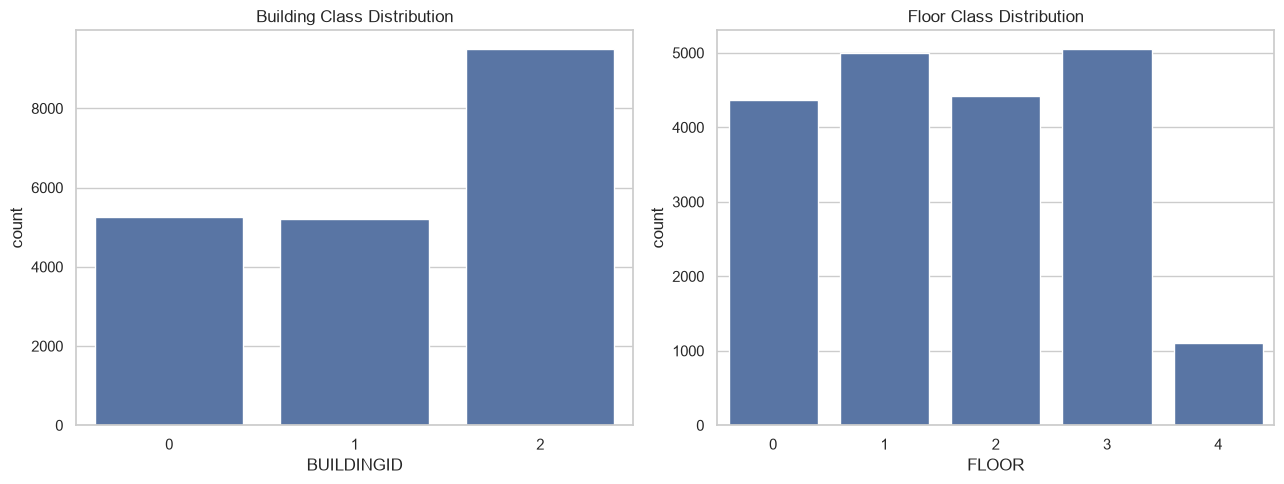

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    ax=axes[0]
)

axes[0].set_title("Building Class Distribution")

sns.countplot(
    data=df_train,
    x="FLOOR",
    ax=axes[1]
)

axes[1].set_title("Floor Class Distribution")

plt.tight_layout()
plt.show()

### 30. Membuat Pembagian Data Training dan Testing

Tujuan: Membagi training dataset menjadi data latih dan data uji internal untuk mengevaluasi performa model.

Pembagian data menggunakan dua skenario:
1. 80% data training dan 20% data testing.
2. 70% data training dan 30% data testing.

Metode stratifikasi: Pembagian menggunakan stratifikasi berdasarkan kombinasi BUILDINGID dan FLOOR agar proporsi setiap kombinasi gedung dan lantai tetap terjaga.

Random State: 42.

Data validation bawaan dataset tidak digunakan dalam proses pembagian ini dan disimpan untuk evaluasi akhir.

In [26]:
# Membuat Stratification Target

stratify_target = (
    y_train["BUILDINGID"].astype(str)
    + "_"
    + y_train["FLOOR"].astype(str)
)


# Skenario 1: Pembagian Data 80:20

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)


# Skenario 2: Pembagian Data 70:30

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.30,
    random_state=42,
    stratify=stratify_target
)


# Menampilkan Hasil Pembagian Data

print("=== SKENARIO 80:20 ===")
print("Training:", X_train_80.shape)
print("Testing :", X_test_80.shape)

print("\n=== SKENARIO 70:30 ===")
print("Training:", X_train_70.shape)
print("Testing :", X_test_70.shape)

=== SKENARIO 80:20 ===
Training: (15440, 520)
Testing : (3860, 520)

=== SKENARIO 70:30 ===
Training: (13510, 520)
Testing : (5790, 520)


### 31. Standardisasi Fitur Menggunakan StandardScaler

Tujuan: Menyamakan skala fitur RSSI agar setiap fitur memiliki skala yang lebih sebanding.

StandardScaler melakukan transformasi berdasarkan rata-rata dan standar deviasi yang dihitung dari data training.

Dalam penelitian ini, StandardScaler akan diterapkan di dalam pipeline preprocessing. Parameter scaling hanya dipelajari dari data training pada setiap skenario eksperimen.

Data testing hanya menggunakan parameter transformasi yang telah dipelajari dari data training.

Standardisasi akan dibandingkan dengan MinMaxScaler pada eksperimen model.

### 32. Perbandingan StandardScaler dan MinMaxScaler

Tujuan: Membandingkan dua metode penskalaan fitur, yaitu StandardScaler dan MinMaxScaler.

StandardScaler: Mengubah fitur berdasarkan rata-rata dan standar deviasi data training.

MinMaxScaler: Mengubah rentang fitur berdasarkan nilai minimum dan maksimum data training.

Metode evaluasi:*Kedua scaler dibandingkan melalui eksperimen model dengan skenario preprocessing, pembagian data, dan konfigurasi model yang konsisten.

Alasan metodologis: Pemilihan scaler tidak hanya didasarkan pada statistik hasil transformasi, tetapi juga pada performa model klasifikasi dan regresi.

Seluruh proses scaling dilakukan di dalam pipeline untuk mencegah data leakage.

### 33. Pipeline Preprocessing

Tujuan: Menggabungkan tahapan preprocessing ke dalam satu pipeline agar seluruh parameter preprocessing hanya dipelajari dari data training.

Pipeline mencakup dua metode penanganan nilai RSSI tidak terdeteksi:

1. Sentinel Replacement: Mengganti nilai +100 menjadi -105 dBm.
2. Median Imputation: Mengubah nilai +100 menjadi NaN, kemudian mengisi nilai tersebut menggunakan median setiap fitur berdasarkan data training.

Pipeline juga menyediakan dua skenario fitur:

1. Full Features: Menggunakan seluruh 520 fitur RSSI.
2. Reduced Features: Menghapus fitur konstan menggunakan VarianceThreshold.

Selain itu, digunakan dua alternatif scaling, yaitu StandardScaler dan MinMaxScaler.

Seluruh tahapan preprocessing di-fit menggunakan data training pada setiap skenario eksperimen. Data testing hanya menjalankan transformasi menggunakan parameter yang telah dipelajari dari data training.

Tujuan metodologis: Mencegah data leakage dan memastikan perbandingan metode preprocessing dilakukan secara konsisten.

In [27]:
# Pipeline Preprocessing

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import FunctionTransformer


# Custom Median Imputer
class RSSIMedianImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        X = np.asarray(X, dtype=float)

        self.statistics_ = np.array([
            np.median(col[np.isfinite(col)])
            if np.isfinite(col).any()
            else -105
            for col in X.T
        ])

        return self

    def transform(self, X):

        X = np.asarray(X, dtype=float).copy()

        missing_rows, missing_cols = np.where(np.isnan(X))

        X[missing_rows, missing_cols] = (
            self.statistics_[missing_cols]
        )

        return X


# Pipeline Builder
def build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="full",
    scaler="standard"
):

    steps = []

    # Metode penanganan sentinel
    if method == "sentinel":

        steps.append((
            "sentinel_replacement",
            FunctionTransformer(
                replace_sentinel,
                validate=False
            )
        ))

    elif method == "median":

        steps.append((
            "sentinel_to_nan",
            FunctionTransformer(
                convert_sentinel_to_nan,
                validate=False
            )
        ))

        steps.append((
            "imputer",
            RSSIMedianImputer()
        ))

    else:
        raise ValueError("Metode preprocessing tidak dikenal.")

    # Seleksi fitur
    if feature_mode == "reduced":

        steps.append((
            "selector",
            VarianceThreshold(threshold=0.0)
        ))

    elif feature_mode != "full":

        raise ValueError("Mode fitur tidak dikenal.")

    # Scaling
    if scaler == "standard":

        steps.append((
            "scaler",
            StandardScaler()
        ))

    elif scaler == "minmax":

        steps.append((
            "scaler",
            MinMaxScaler()
        ))

    else:
        raise ValueError("Scaler tidak dikenal.")

    return Pipeline(steps)

In [28]:
# Pengujian Pipeline Preprocessing

results = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_80)

            X_test_result = pipeline.transform(X_test_80)

            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_results = pd.DataFrame(results)

display(pipeline_test_results)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(15440, 520)","(3860, 520)",Success
1,sentinel,full,minmax,"(15440, 520)","(3860, 520)",Success
2,sentinel,reduced,standard,"(15440, 461)","(3860, 461)",Success
3,sentinel,reduced,minmax,"(15440, 461)","(3860, 461)",Success
4,median,full,standard,"(15440, 520)","(3860, 520)",Success
5,median,full,minmax,"(15440, 520)","(3860, 520)",Success
6,median,reduced,standard,"(15440, 423)","(3860, 423)",Success
7,median,reduced,minmax,"(15440, 423)","(3860, 423)",Success


In [29]:
# Pengujian Pipeline pada Split 70:30

results_70 = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_70)

            X_test_result = pipeline.transform(X_test_70)
            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results_70.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_70 = pd.DataFrame(results_70)

display(pipeline_test_70)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(13510, 520)","(5790, 520)",Success
1,sentinel,full,minmax,"(13510, 520)","(5790, 520)",Success
2,sentinel,reduced,standard,"(13510, 458)","(5790, 458)",Success
3,sentinel,reduced,minmax,"(13510, 458)","(5790, 458)",Success
4,median,full,standard,"(13510, 520)","(5790, 520)",Success
5,median,full,minmax,"(13510, 520)","(5790, 520)",Success
6,median,reduced,standard,"(13510, 419)","(5790, 419)",Success
7,median,reduced,minmax,"(13510, 419)","(5790, 419)",Success


In [30]:
# Perbandingan Statistik Dua Metode Penanganan RSSI

def compare_rssi_methods(X_train, split_name):

    # Metode 1: Sentinel Replacement
    X_sentinel = replace_sentinel(X_train.copy())

    # Metode 2: Median Imputation
    X_nan = convert_sentinel_to_nan(X_train.copy())

    median_imputer = RSSIMedianImputer()
    X_median = median_imputer.fit_transform(X_nan)

    # Mengubah hasil menjadi DataFrame
    X_sentinel = pd.DataFrame(
        X_sentinel,
        columns=X_train.columns
    )

    X_median = pd.DataFrame(
        X_median,
        columns=X_train.columns
    )

    # Ringkasan statistik
    summary = []

    for method, data in [
        ("Sentinel Replacement", X_sentinel),
        ("Median Imputation", X_median)
    ]:

        summary.append({
            "Split": split_name,
            "Method": method,
            "Mean": data.mean().mean(),
            "Std": data.std().mean(),
            "Minimum": data.min().min(),
            "Maximum": data.max().max()
        })

    return summary


# Perbandingan pada kedua skenario split

comparison_results = []

comparison_results.extend(
    compare_rssi_methods(X_train_80, "80:20")
)

comparison_results.extend(
    compare_rssi_methods(X_train_70, "70:30")
)

rssi_comparison = pd.DataFrame(comparison_results)

display(rssi_comparison.round(3))

,Split,Method,Mean,Std,Minimum,Maximum
0,80:20,Sentinel Replacement,-104.094,3.710,-105.0,0.0
1,80:20,Median Imputation,-86.536,1.521,-105.0,0.0
2,70:30,Sentinel Replacement,-104.095,3.708,-105.0,0.0
3,70:30,Median Imputation,-86.554,1.521,-105.0,0.0


### Interpretasi Hasil Perbandingan Statistik

Berdasarkan hasil perbandingan, median imputation menghasilkan nilai mean RSSI yang lebih tinggi dibandingkan sentinel replacement pada kedua skenario pembagian data.

Standar deviasi pada median imputation juga lebih rendah. Hal ini menunjukkan bahwa penggantian nilai RSSI yang tidak terdeteksi menggunakan median mengubah distribusi nilai dan mengurangi variasi data.

Kedua metode menghasilkan rentang nilai yang sama, yaitu -105 hingga 0 dBm.

Hasil pada split 80:20 dan 70:30 menunjukkan karakteristik statistik yang relatif konsisten.

Namun, perubahan mean dan standar deviasi tidak dapat dijadikan dasar tunggal untuk menentukan metode terbaik. Penentuan metode terbaik tetap memerlukan evaluasi performa model pada tahap eksperimen.

Dengan demikian, kedua metode tetap dipertahankan sebagai alternatif preprocessing untuk dibandingkan lebih lanjut.

## PROSES 2: CLUSTERING

Tahap ini bertujuan mengelompokkan data fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal tanpa menggunakan label target sebagai fitur pembentuk cluster.

Algoritma yang digunakan:
1. K-Means untuk mengelompokkan data berdasarkan jumlah cluster optimal.
2. DBSCAN untuk mengidentifikasi kelompok berdasarkan kepadatan data.

Evaluasi dilakukan menggunakan Silhouette Score, Davies-Bouldin Index, Adjusted Rand Index (ARI), dan Normalized Mutual Information (NMI).

Visualisasi PCA 2D digunakan untuk membantu memahami struktur cluster. Interpretasi fisik dilakukan dengan membandingkan hasil cluster terhadap BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

### 34. Persiapan Data Clustering

Tahap ini menyiapkan data RSSI Wi-Fi untuk proses clustering menggunakan K-Means dan DBSCAN.

Konfigurasi utama menggunakan Sentinel Replacement, Reduced Features, dan MinMaxScaler.

Seluruh preprocessing di-fit menggunakan training dataset. BUILDINGID dan FLOOR tidak digunakan sebagai fitur pembentuk cluster, tetapi disimpan sebagai label referensi untuk evaluasi menggunakan ARI dan NMI.

Data validation tidak digunakan dalam proses clustering ini.

In [31]:

# 1. Membuat pipeline preprocessing
clustering_preprocessor = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="minmax"
)

# 2. Fit preprocessing pada seluruh training dataset
X_cluster = clustering_preprocessor.fit_transform(X_train_raw)

# 3. Menyimpan label asli untuk evaluasi
y_cluster_building = y_train["BUILDINGID"].reset_index(drop=True)
y_cluster_floor = y_train["FLOOR"].reset_index(drop=True)

# 4. Pemeriksaan hasil
print("=== DATA CLUSTERING ===")
print("Jumlah observasi:", X_cluster.shape[0])
print("Jumlah fitur:", X_cluster.shape[1])

print("\n=== LABEL REFERENSI ===")
print("BUILDINGID:", y_cluster_building.shape)
print("FLOOR:", y_cluster_floor.shape)

print("\n=== VALIDASI DATA ===")
print("Mengandung NaN:", np.isnan(X_cluster).any())
print("Mengandung Inf:", np.isinf(X_cluster).any())

=== DATA CLUSTERING ===
Jumlah observasi: 19300
Jumlah fitur: 465

=== LABEL REFERENSI ===
BUILDINGID: (19300,)
FLOOR: (19300,)

=== VALIDASI DATA ===
Mengandung NaN: False
Mengandung Inf: False


### 35. Penentuan Jumlah Cluster K-Means

K-Means digunakan untuk mengelompokkan fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal.

Penentuan jumlah cluster optimal dilakukan menggunakan Elbow Method dan Silhouette Score.

Elbow Method mengamati perubahan Within-Cluster Sum of Squares (WCSS) atau inertia pada beberapa nilai k. Silhouette Score digunakan untuk menilai tingkat kekompakan dan pemisahan antarcluster.

Kandidat jumlah cluster diuji pada rentang k = 2 sampai k = 10.

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Kandidat jumlah cluster
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    # Silhouette dihitung menggunakan sampel 3000 observasi
    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"k={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

k=2 | Inertia=54781.80 | Silhouette=0.1546
k=3 | Inertia=51032.73 | Silhouette=0.1674
k=4 | Inertia=47769.83 | Silhouette=0.1054
k=5 | Inertia=44392.99 | Silhouette=0.1196
k=6 | Inertia=42564.81 | Silhouette=0.0786
k=7 | Inertia=41303.95 | Silhouette=0.0891
k=8 | Inertia=39483.17 | Silhouette=0.1134
k=9 | Inertia=38605.19 | Silhouette=0.0901
k=10 | Inertia=36979.28 | Silhouette=0.1130


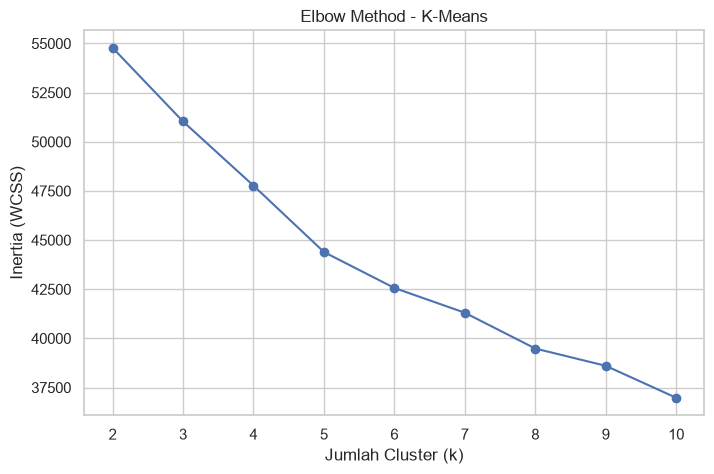

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

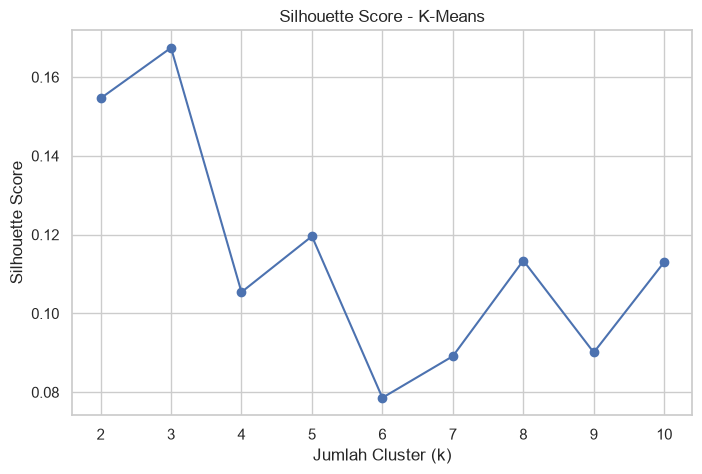

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 36. Perbandingan Kandidat Jumlah Cluster K-Means

Berdasarkan Elbow Method dan Silhouette Score, kandidat jumlah cluster yang dipertimbangkan adalah k=2, k=3, dan k=4. Silhouette Score tertinggi dicapai pada k=3 sebesar 0,1674, diikuti k=2 sebesar 0,1546 dan k=4 sebesar 0,1054. Nilai k=3 sama dengan jumlah kategori BUILDINGID pada dataset, yaitu tiga gedung, sehingga menjadi salah satu kandidat yang relevan untuk dievaluasi lebih lanjut. Sementara itu, k=4 juga dipertahankan sebagai kandidat berdasarkan pertimbangan kurva Elbow Method. Seluruh nilai Silhouette Score berada di bawah 0,2, yang mengindikasikan bahwa pemisahan cluster berdasarkan jarak RSSI cenderung lemah.

Ketiga kandidat selanjutnya dibandingkan menggunakan Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap label referensi BUILDINGID dan FLOOR. Label referensi hanya digunakan untuk evaluasi eksternal, bukan sebagai fitur pembentuk cluster.

In [35]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

k_candidates = [2,3,4]
kmeans_comparison = []

kmeans_models = {}
kmeans_labels = {}

for k in k_candidates:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    kmeans_models[k] = model
    kmeans_labels[k] = labels

    # Evaluasi terhadap label asli
    ari_building = adjusted_rand_score(
        y_cluster_building, labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building, labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor, labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor, labels
    )

    kmeans_comparison.append({
        "k": k,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

kmeans_comparison_df = pd.DataFrame(kmeans_comparison)

display(kmeans_comparison_df.round(4))

,k,ARI Building,NMI Building,ARI Floor,NMI Floor
0,2,0.1540,0.2714,-0.0043,0.0066
1,3,0.4300,0.5823,-0.0069,0.0136
2,4,0.7424,0.7382,0.0073,0.0456


### Interpretasi Hasil Perbandingan K-Means

Hasil evaluasi menunjukkan bahwa kesesuaian terhadap BUILDINGID meningkat seiring bertambahnya k dari 2 sampai 4. Pada k=2, ARI sebesar 0,1540 dan NMI sebesar 0,2714. Pada k=3, ARI sebesar 0,4300 dan NMI sebesar 0,5823. Pada k=4, ARI sebesar 0,7424 dan NMI sebesar 0,7382, yang merupakan kesesuaian tertinggi. Nilai ini menunjukkan adanya hubungan yang kuat antara hasil clustering dan identitas gedung.

Sebaliknya, kesesuaian ketiga kandidat terhadap FLOOR tetap rendah. Nilai ARI berkisar antara −0,0069 dan 0,0073, mendekati nol, sehingga hasil pengelompokan belum mampu merepresentasikan struktur lantai.

Silhouette Score tertinggi diperoleh k=3 (0,1674), tetapi k=4 memberikan kesesuaian terbaik terhadap gedung. Dengan mempertimbangkan hasil Elbow Method, Silhouette Score, ARI, dan NMI, k=4 dipertahankan sebagai kandidat utama untuk analisis struktur gedung, sedangkan k=2 dan k=3 tetap digunakan sebagai pembanding. Keputusan akhir akan mempertimbangkan evaluasi internal dan interpretasi fisik cluster.

In [36]:
from sklearn.metrics import davies_bouldin_score

dbi_results = []

for k in [2,3,4]:

    labels = kmeans_labels[k]

    dbi = davies_bouldin_score(
        X_cluster,
        labels
    )

    dbi_results.append({
        "k": k,
        "Silhouette Score": silhouette_values[k - 2],
        "Davies-Bouldin Index": dbi
    })

dbi_comparison = pd.DataFrame(dbi_results)

display(dbi_comparison.round(4))

,k,Silhouette Score,Davies-Bouldin Index
0,2,0.1546,2.2766
1,3,0.1674,2.3032
2,4,0.1054,2.5123


### Interpretasi Evaluasi Internal dan Eksternal K-Means

Berdasarkan evaluasi internal, k=2 menghasilkan Silhouette Score sebesar 0,1546 dan Davies-Bouldin Index sebesar 2,2766. Pada k=3 nilainya 0,1674 dan 2,3032, sedangkan pada k=4 nilainya 0,1054 dan 2,5123. Silhouette Score tertinggi dicapai k=3, sedangkan Davies-Bouldin Index terendah dicapai k=2, dengan selisih antar kandidat yang kecil. Seluruh Silhouette Score berada di bawah 0,2 dan seluruh Davies-Bouldin Index berada di atas 2, sehingga kualitas pemisahan cluster secara internal tergolong rendah untuk ketiga kandidat.

Namun, evaluasi eksternal menunjukkan bahwa k=4 memiliki kesesuaian tertinggi terhadap BUILDINGID, dengan ARI sebesar 0,7424 dan NMI sebesar 0,7382. Ketiga konfigurasi belum menunjukkan kesesuaian yang baik terhadap FLOOR.

Hasil ini menunjukkan adanya perbedaan antara struktur cluster berdasarkan kemiripan RSSI dan struktur lokasi fisik berdasarkan label gedung serta lantai. Oleh karena itu, k=4 digunakan untuk interpretasi fisik cluster, sedangkan k=2 dan k=3 tetap menjadi pembanding.

### 37. Penentuan Parameter DBSCAN Menggunakan K-Distance Plot

DBSCAN merupakan algoritma clustering berbasis kepadatan yang mengelompokkan observasi berdasarkan jarak antar titik dan jumlah minimum observasi di sekitar suatu titik.

Parameter utama yang digunakan adalah:

- eps: radius maksimum lingkungan suatu titik.
- min_samples: jumlah minimum observasi untuk membentuk daerah padat.

Nilai eps dianalisis menggunakan k-distance plot. Titik perubahan kemiringan kurva digunakan sebagai kandidat nilai eps.

Analisis dilakukan menggunakan fitur RSSI yang telah melalui preprocessing dan scaling.

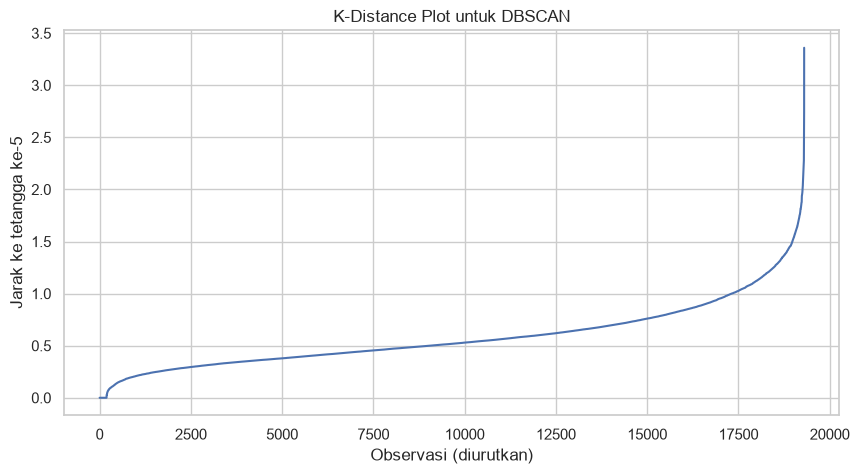

In [37]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Parameter awal
min_samples_dbscan = 5

# Menghitung jarak ke tetangga terdekat
neighbors = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    metric="euclidean"
)

neighbors.fit(X_cluster)

distances, indices = neighbors.kneighbors(X_cluster)

# Mengambil jarak tetangga ke-5
k_distances = np.sort(distances[:, -1])

# Visualisasi k-distance plot
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Observasi (diurutkan)")
plt.ylabel("Jarak ke tetangga ke-5")
plt.title("K-Distance Plot untuk DBSCAN")
plt.grid(True)

plt.show()

### 38. Pengujian Kandidat Parameter DBSCAN

Berdasarkan K-distance plot, beberapa kandidat nilai eps diuji untuk memperoleh konfigurasi DBSCAN yang sesuai.

Parameter min_samples ditetapkan sebesar 5 sebagai konfigurasi awal. Kandidat eps yang diuji adalah 1.0, 1.2, 1.4, dan 1.6.

Evaluasi memperhatikan jumlah cluster yang terbentuk, jumlah noise, serta kualitas cluster menggunakan Silhouette Score dan Davies-Bouldin Index.

Observasi yang diklasifikasikan sebagai noise tidak dimasukkan dalam perhitungan metrik internal clustering.

In [38]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
import pandas as pd
import numpy as np

eps_candidates = [1.0, 1.2, 1.4, 1.6]
min_samples_dbscan = 5

dbscan_results = []
dbscan_models = {}
dbscan_labels = {}

for eps in eps_candidates:

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples_dbscan,
        metric="euclidean"
    )

    labels = model.fit_predict(X_cluster)

    dbscan_models[eps] = model
    dbscan_labels[eps] = labels

    # Menghitung jumlah cluster tanpa noise
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})

    # Menghitung jumlah noise
    n_noise = np.sum(labels == -1)
    noise_percentage = n_noise / len(labels) * 100

    # Metrik internal hanya untuk observasi non-noise
    non_noise_mask = labels != -1
    X_valid = X_cluster[non_noise_mask]
    labels_valid = labels[non_noise_mask]

    if 1 < len(np.unique(labels_valid)) < len(labels_valid):

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(3000, len(X_valid)),
            random_state=42
        )

        dbi = davies_bouldin_score(
            X_valid,
            labels_valid
        )

    else:
        silhouette = np.nan
        dbi = np.nan

    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples_dbscan,
        "Jumlah Cluster": n_clusters,
        "Jumlah Noise": n_noise,
        "Noise (%)": noise_percentage,
        "Silhouette": silhouette,
        "Davies-Bouldin": dbi
    })

dbscan_comparison = pd.DataFrame(dbscan_results)

display(dbscan_comparison.round(4))

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette,Davies-Bouldin
0,1.0,5,146,1377,7.1347,-0.0928,0.9179
1,1.2,5,98,621,3.2176,-0.0080,0.8732
2,1.4,5,60,257,1.3316,0.0187,0.8931
3,1.6,5,33,112,0.5803,0.1447,0.8557


### Interpretasi Hasil Pengujian DBSCAN

Berdasarkan pengujian empat kandidat eps dengan min_samples sebesar 5, diperoleh perubahan jumlah cluster dan noise seiring peningkatan nilai eps.

Pada eps=1.0, DBSCAN menghasilkan 146 cluster dengan 7,1347% observasi (1.377 observasi) teridentifikasi sebagai noise. Silhouette Score bernilai negatif (−0,0928), yang menunjukkan kualitas pemisahan cluster belum baik.

Pada eps=1.6, jumlah cluster berkurang menjadi 33 dengan persentase noise sebesar 0,5803% (112 observasi). Konfigurasi ini menghasilkan Silhouette Score tertinggi sebesar 0,1447 dan Davies-Bouldin Index terendah sebesar 0,8557.

Dengan mempertimbangkan kedua metrik internal, eps=1.6 dipilih sebagai kandidat utama untuk evaluasi lanjutan. Meskipun demikian, konfigurasi ini belum ditetapkan sebagai hasil terbaik secara keseluruhan. Evaluasi eksternal menggunakan ARI dan NMI serta interpretasi fisik cluster tetap diperlukan.

### 39. Evaluasi Eksternal DBSCAN

Evaluasi eksternal dilakukan untuk mengetahui kesesuaian hasil clustering DBSCAN terhadap label referensi BUILDINGID dan FLOOR.

Metrik yang digunakan adalah Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI).

Seluruh observasi digunakan dalam evaluasi, termasuk observasi yang dikategorikan sebagai noise dengan label -1. Noise diperlakukan sebagai satu kategori tersendiri dalam perhitungan metrik eksternal.

In [39]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

dbscan_external_results = []

for eps in eps_candidates:

    labels = dbscan_labels[eps]

    ari_building = adjusted_rand_score(
        y_cluster_building,
        labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building,
        labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor,
        labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor,
        labels
    )

    dbscan_external_results.append({
        "eps": eps,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

dbscan_external_df = pd.DataFrame(
    dbscan_external_results
)

display(dbscan_external_df.round(4))

,eps,ARI Building,NMI Building,ARI Floor,NMI Floor
0,1.0,0.2035,0.2600,-0.0002,0.1017
1,1.2,0.0448,0.1059,0.0000,0.0893
2,1.4,0.0289,0.0853,-0.0004,0.0715
3,1.6,0.0217,0.0673,0.0008,0.0525


### Interpretasi Hasil Evaluasi Eksternal DBSCAN

Berdasarkan evaluasi eksternal, eps=1.0 menghasilkan nilai ARI dan NMI tertinggi terhadap BUILDINGID, masing-masing sebesar 0,2035 dan 0,2600. Konfigurasi tersebut juga menghasilkan NMI FLOOR tertinggi (0,1017) dibandingkan kandidat eps lainnya. Namun, nilai ARI FLOOR pada seluruh kandidat eps hanya berkisar antara −0,0004 dan 0,0008, sehingga kesesuaian terhadap FLOOR sangat rendah.

Sementara itu, eps=1.6 memiliki kualitas internal terbaik berdasarkan Silhouette Score dan Davies-Bouldin Index, tetapi kesesuaiannya terhadap label asli lebih rendah (ARI BUILDINGID 0,0217).

Hasil ini menunjukkan adanya trade-off antara kualitas internal cluster dan kesesuaian terhadap label lokasi sebenarnya. Oleh karena itu, eps=1.0 dan eps=1.6 dipertahankan sebagai dua konfigurasi pembanding untuk analisis lanjutan.

### 40. Visualisasi Cluster Menggunakan PCA 2D

Principal Component Analysis (PCA) digunakan untuk mereduksi dimensi data menjadi dua komponen utama agar hasil clustering dapat divisualisasikan dalam bidang dua dimensi.

PCA hanya digunakan untuk visualisasi. Proses clustering tetap menggunakan seluruh fitur RSSI hasil preprocessing.

Visualisasi dilakukan untuk membandingkan struktur cluster K-Means dan DBSCAN.

In [40]:
from sklearn.decomposition import PCA

# PCA untuk visualisasi 2D
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_cluster)

print("Dimensi PCA:", X_pca.shape)

print(
    "Total explained variance ratio:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Dimensi PCA: (19300, 2)
Total explained variance ratio: 0.1737


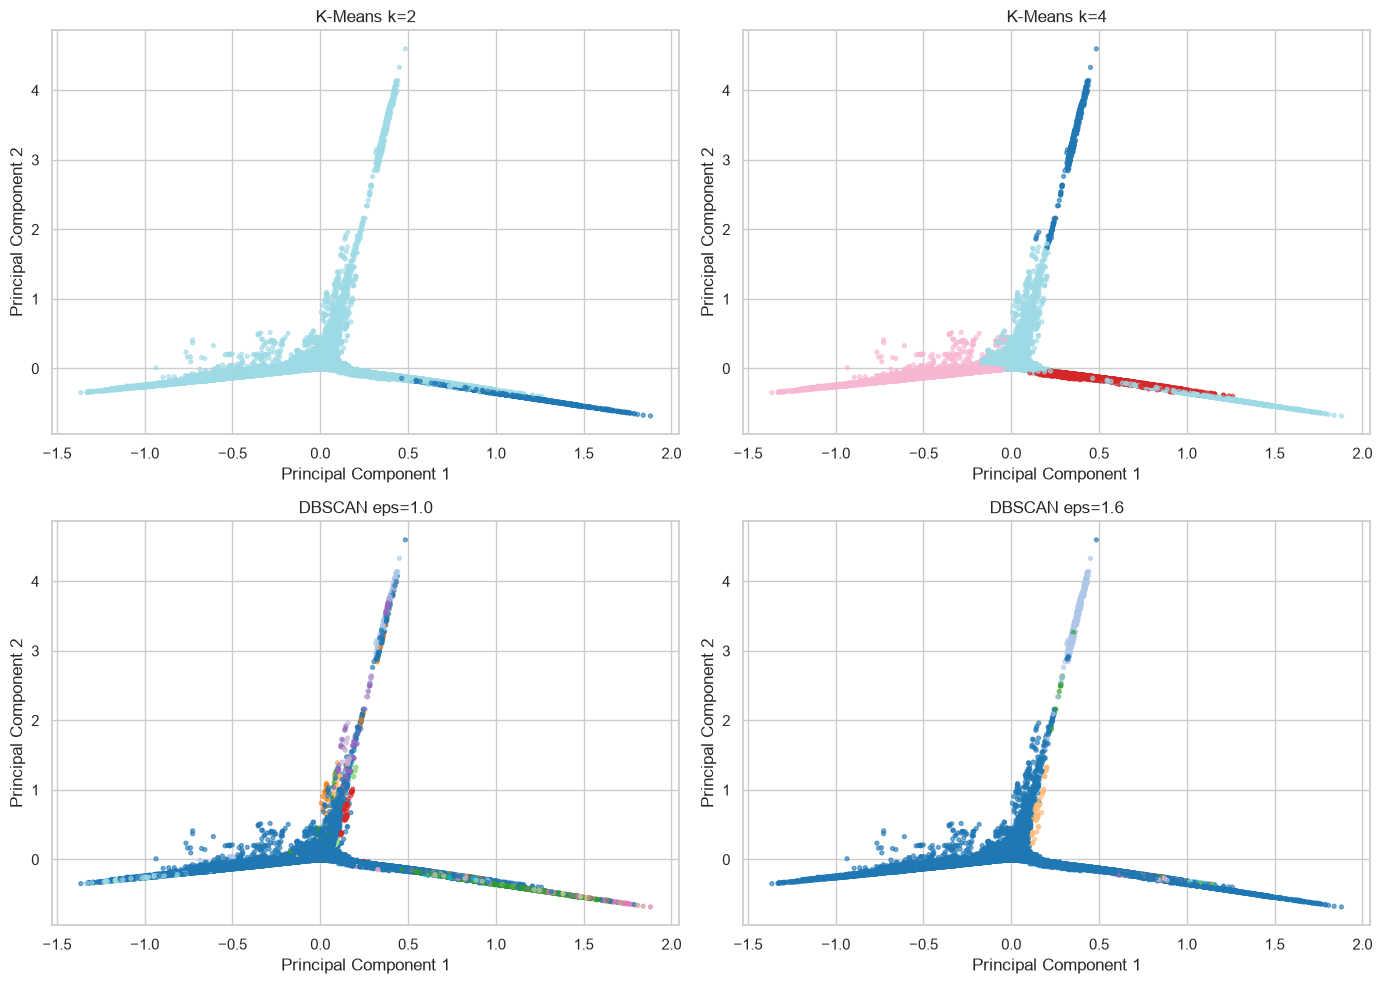

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cluster_configs = [
    ("K-Means k=2", kmeans_labels[2]),
    ("K-Means k=4", kmeans_labels[4]),
    ("DBSCAN eps=1.0", dbscan_labels[1.0]),
    ("DBSCAN eps=1.6", dbscan_labels[1.6])
]

for ax, (title, labels) in zip(
    axes.flatten(),
    cluster_configs
):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab20",
        s=8,
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi PCA 2D

Hasil PCA menghasilkan dua komponen utama dengan total explained variance ratio sebesar 17,37%. Artinya, kedua komponen tersebut hanya merepresentasikan sebagian kecil variasi dari keseluruhan fitur RSSI.

Pada K-Means k=2, data terbagi menjadi dua kelompok dengan ukuran tidak seimbang, yaitu 12,85% dan 87,15% dari seluruh data. Pada k=4, pembagian cluster menjadi lebih terperinci, dengan satu cluster kecil (1,77% data) dan tiga cluster yang lebih besar.

DBSCAN eps=1.0 menghasilkan banyak kelompok kecil (146 cluster), sedangkan eps=1.6 menghasilkan 33 cluster dengan 96,34% observasi tergabung dalam satu cluster besar.

Visualisasi PCA digunakan untuk membantu mengamati pola distribusi cluster. Karena proporsi variasi yang dijelaskan hanya 17,37%, interpretasi visual tidak digunakan sebagai satu-satunya dasar untuk menentukan kualitas clustering. Evaluasi tetap mempertimbangkan Silhouette Score, Davies-Bouldin Index, ARI, dan NMI.

### 41. Interpretasi Fisik Cluster K-Means

Interpretasi fisik dilakukan dengan menganalisis hubungan antara hasil clustering dan karakteristik lokasi sebenarnya.

Analisis mencakup distribusi BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE pada setiap cluster.

Label asli tidak digunakan dalam pembentukan cluster, tetapi digunakan untuk memahami karakteristik geografis dan posisi fisik kelompok yang terbentuk.

In [42]:
# Membuat dataframe interpretasi cluster K-Means

cluster_analysis = pd.DataFrame({
    "BUILDINGID": y_cluster_building,
    "FLOOR": y_cluster_floor,
    "LONGITUDE": y_train["LONGITUDE"].reset_index(drop=True),
    "LATITUDE": y_train["LATITUDE"].reset_index(drop=True)
})

# Menambahkan label cluster
cluster_analysis["KMeans_k2"] = kmeans_labels[2]
cluster_analysis["KMeans_k4"] = kmeans_labels[4]

# Profil distribusi gedung untuk K-Means k=4
print("=== DISTRIBUSI BUILDINGID PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["BUILDINGID"],
        normalize="index"
    ).round(3)
)

# Profil distribusi lantai untuk K-Means k=4
print("=== DISTRIBUSI FLOOR PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["FLOOR"],
        normalize="index"
    ).round(3)
)

# Rata-rata koordinat setiap cluster
print("=== RATA-RATA KOORDINAT PER CLUSTER ===")

display(
    cluster_analysis.groupby("KMeans_k4")[
        ["LONGITUDE", "LATITUDE"]
    ].mean().round(6)
)

=== DISTRIBUSI BUILDINGID PER CLUSTER ===


BUILDINGID,0,1,2
KMeans_k4,,,
0,0.000,1.00,0.000
1,1.000,0.00,0.000
2,0.000,0.00,1.000
3,0.368,0.62,0.012


=== DISTRIBUSI FLOOR PER CLUSTER ===


FLOOR,0,1,2,3,4
KMeans_k4,,,,,
0,0.904,0.096,0.000,0.000,0.00
1,0.179,0.268,0.292,0.260,0.00
2,0.209,0.239,0.173,0.298,0.08
3,0.227,0.258,0.285,0.229,0.00


=== RATA-RATA KOORDINAT PER CLUSTER ===


,LONGITUDE,LATITUDE
KMeans_k4,,
0,-7456.350020,4.864827e+06
1,-7622.121857,4.864988e+06
2,-7354.191795,4.864815e+06
3,-7549.333440,4.864902e+06


### Interpretasi Fisik Cluster K-Means k=4

Berdasarkan distribusi BUILDINGID, cluster 0 (342 observasi) seluruhnya berasal dari Building 1, cluster 1 (2.514 observasi) seluruhnya berasal dari Building 0, dan cluster 2 (9.027 observasi) seluruhnya berasal dari Building 2. Cluster 3 (7.417 observasi) mencampurkan Building 1 sebesar 62,0%, Building 0 sebesar 36,8%, dan Building 2 sebesar 1,2%.

Hasil ini menunjukkan bahwa K-Means k=4 mampu membentuk tiga cluster yang murni berdasarkan gedung. Namun, cluster 3 masih mencampurkan observasi dari beberapa gedung, dan cluster 0 sangat kecil (1,77% dari data).

Berdasarkan distribusi FLOOR, cluster 0 didominasi oleh FLOOR 0 sebesar 90,4%. Sementara itu, cluster 1, cluster 2, dan cluster 3 memiliki distribusi lantai yang relatif merata pada FLOOR 0 sampai FLOOR 3, dan FLOOR 4 hanya muncul pada cluster 2 (8,0%). Hasil ini menunjukkan bahwa pemisahan berdasarkan lantai belum terbentuk secara konsisten.

Rata-rata longitude dan latitude juga menunjukkan perbedaan posisi antarcluster. Namun, interpretasi geografis lebih lanjut memerlukan pemeriksaan sistem koordinat dan sebaran koordinat setiap cluster.

Secara keseluruhan, K-Means k=4 mampu menangkap sebagian struktur lokasi berdasarkan gedung, tetapi belum memisahkan karakteristik lantai.

In [43]:
# Menambahkan label cluster DBSCAN

cluster_analysis["DBSCAN_eps1"] = dbscan_labels[1.0]
cluster_analysis["DBSCAN_eps1_6"] = dbscan_labels[1.6]


def analyze_dbscan_clusters(data, cluster_column):

    print(f"\n=== {cluster_column}: BUILDINGID ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["BUILDINGID"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: FLOOR ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["FLOOR"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: KOORDINAT ===")

    display(
        data.groupby(cluster_column)[
            ["LONGITUDE", "LATITUDE"]
        ].mean().round(3)
    )


analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1"
)

analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1_6"
)


=== DBSCAN_eps1: BUILDINGID ===


BUILDINGID,0,1,2
DBSCAN_eps1,,,
-1,0.583,0.169,0.248
0,0.129,0.280,0.591
1,0.000,0.000,1.000
2,0.000,1.000,0.000
3,0.000,1.000,0.000
...,...,...,...
141,0.000,0.000,1.000
142,0.000,0.000,1.000
143,0.000,0.000,1.000



=== DBSCAN_eps1: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1,,,,,
-1,0.078,0.346,0.320,0.245,0.012
0,0.238,0.236,0.213,0.270,0.042
1,0.000,0.000,0.000,1.000,0.000
2,0.000,0.000,1.000,0.000,0.000
3,0.000,0.000,1.000,0.000,0.000
...,...,...,...,...,...
141,0.000,1.000,0.000,0.000,0.000
142,0.000,1.000,0.000,0.000,0.000
143,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1,,
-1,-7537.115,4864911.039
0,-7427.594,4864858.926
1,-7329.027,4864766.304
2,-7458.264,4864852.084
3,-7507.032,4864834.894
...,...,...
141,-7320.132,4864816.324
142,-7338.259,4864821.407
143,-7331.117,4864821.621


... (2 outputs left out)


=== DBSCAN_eps1_6: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1_6,,,,,
-1,0.089,0.196,0.652,0.062,0.000
0,0.216,0.249,0.228,0.268,0.039
1,0.966,0.034,0.000,0.000,0.000
2,0.000,1.000,0.000,0.000,0.000
3,0.000,1.000,0.000,0.000,0.000
4,1.000,0.000,0.000,0.000,0.000
5,0.000,1.000,0.000,0.000,0.000
6,1.000,0.000,0.000,0.000,0.000
7,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1_6: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1_6,,
-1,-7560.922,4864939.782
0,-7463.612,4864870.457
1,-7456.262,4864825.645
2,-7312.583,4864797.237
3,-7328.049,4864766.951
4,-7499.118,4864838.798
5,-7508.267,4864855.562
6,-7458.241,4864850.011
7,-7638.904,4864999.541


In [44]:
# Ringkasan ukuran cluster DBSCAN

def summarize_dbscan_clusters(data, cluster_column):

    summary = (
        data.groupby(cluster_column)
        .agg(
            Jumlah_Data=("BUILDINGID", "size"),
            Building_Dominan=(
                "BUILDINGID",
                lambda x: x.mode().iloc[0]
            ),
            Floor_Dominan=(
                "FLOOR",
                lambda x: x.mode().iloc[0]
            ),
            Persentase_Building_Dominan=(
                "BUILDINGID",
                lambda x: x.value_counts(normalize=True).max() * 100
            ),
            Persentase_Floor_Dominan=(
                "FLOOR",
                lambda x: x.value_counts(normalize=True).max() * 100
            )
        )
        .sort_values("Jumlah_Data", ascending=False)
    )

    summary["Jumlah_Data"] = summary["Jumlah_Data"].astype(int)

    return summary.round(2)


print("=== RINGKASAN DBSCAN EPS 1.0 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1"
    )
)

print("=== RINGKASAN DBSCAN EPS 1.6 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1_6"
    )
)

=== RINGKASAN DBSCAN EPS 1.0 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1,,,,,
0,14365,2,3,59.14,27.00
34,2002,0,1,100.00,25.77
-1,1377,0,1,58.32,34.64
13,168,1,0,100.00,100.00
21,54,1,2,100.00,100.00
...,...,...,...,...,...
133,5,0,2,100.00,100.00
138,5,0,3,100.00,100.00
139,5,0,3,100.00,100.00


=== RINGKASAN DBSCAN EPS 1.6 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1_6,,,,,
0,18593,2,3,48.80,26.80
1,293,1,0,100.00,96.59
-1,112,0,2,71.43,65.18
5,68,1,1,100.00,100.00
6,10,1,0,100.00,100.00
7,10,0,1,100.00,100.00
8,10,0,1,100.00,100.00
9,10,0,1,100.00,100.00
16,10,0,2,100.00,100.00


### Interpretasi Fisik Cluster DBSCAN

Pada eps=1.0, cluster terbesar berisi 14.365 observasi atau sekitar 74,43% dari keseluruhan data. Cluster 34 berisi 2.002 observasi dan seluruhnya berasal dari Building 0. Namun, konfigurasi ini menghasilkan 146 cluster dan persentase noise sebesar 7,13%, sehingga menunjukkan fragmentasi kelompok yang cukup tinggi.

Pada eps=1.6, cluster terbesar berisi 18.593 observasi atau sekitar 96,34% dari keseluruhan data. Beberapa cluster kecil menunjukkan kesesuaian yang kuat terhadap gedung dan lantai tertentu. Namun, dominasi satu cluster besar menunjukkan bahwa sebagian besar observasi belum terpisah menjadi kelompok yang lebih spesifik.

Dengan demikian, eps=1.0 memiliki kesesuaian lebih tinggi terhadap BUILDINGID berdasarkan ARI dan NMI, sedangkan eps=1.6 memiliki kualitas internal lebih baik berdasarkan Silhouette Score dan Davies-Bouldin Index.

### 42. Perbandingan Hasil K-Means dan DBSCAN

Perbandingan dilakukan untuk mengevaluasi kualitas clustering berdasarkan metrik internal dan eksternal.

Metrik internal meliputi Silhouette Score dan Davies-Bouldin Index. Metrik eksternal meliputi Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap BUILDINGID dan FLOOR.

Selain itu, jumlah cluster dan noise digunakan untuk memahami karakteristik pengelompokan masing-masing algoritma.

Perbandingan ini bertujuan mengidentifikasi kelebihan dan keterbatasan setiap konfigurasi dalam merepresentasikan struktur lokasi indoor berdasarkan fingerprint RSSI Wi-Fi.

In [45]:
# Tabel perbandingan akhir K-Means dan DBSCAN (dihitung dari hasil eksperimen, bukan diketik manual)
kmeans_final = kmeans_comparison_df.merge(dbi_comparison, on="k")

baris_final = []
for _, r in kmeans_final.iterrows():
    baris_final.append({
        "Algorithm": "K-Means",
        "Configuration": f"k={int(r['k'])}",
        "Clusters": int(r["k"]),
        "Noise (%)": 0.0,
        "Silhouette": r["Silhouette Score"],
        "Davies-Bouldin": r["Davies-Bouldin Index"],
        "ARI Building": r["ARI Building"],
        "NMI Building": r["NMI Building"],
        "ARI Floor": r["ARI Floor"],
        "NMI Floor": r["NMI Floor"],
    })

dbscan_final = dbscan_comparison.merge(dbscan_external_df, on="eps")
for eps_dipilih in [1.0, 1.6]:
    r = dbscan_final[dbscan_final["eps"] == eps_dipilih].iloc[0]
    baris_final.append({
        "Algorithm": "DBSCAN",
        "Configuration": f"eps={eps_dipilih}",
        "Clusters": int(r["Jumlah Cluster"]),
        "Noise (%)": r["Noise (%)"],
        "Silhouette": r["Silhouette"],
        "Davies-Bouldin": r["Davies-Bouldin"],
        "ARI Building": r["ARI Building"],
        "NMI Building": r["NMI Building"],
        "ARI Floor": r["ARI Floor"],
        "NMI Floor": r["NMI Floor"],
    })

final_clustering_comparison = pd.DataFrame(baris_final)
display(final_clustering_comparison.round(4))

,Algorithm,Configuration,Clusters,Noise (%),Silhouette,Davies-Bouldin,ARI Building,NMI Building,ARI Floor,NMI Floor
0,K-Means,k=2,2,0.0000,0.1546,2.2766,0.1540,0.2714,-0.0043,0.0066
1,K-Means,k=3,3,0.0000,0.1674,2.3032,0.4300,0.5823,-0.0069,0.0136
2,K-Means,k=4,4,0.0000,0.1054,2.5123,0.7424,0.7382,0.0073,0.0456
3,DBSCAN,eps=1.0,146,7.1347,-0.0928,0.9179,0.2035,0.2600,-0.0002,0.1017
4,DBSCAN,eps=1.6,33,0.5803,0.1447,0.8557,0.0217,0.0673,0.0008,0.0525


### 43. Kesimpulan Hasil Clustering

Berdasarkan eksperimen K-Means dan DBSCAN, kedua algoritma menunjukkan karakteristik pengelompokan yang berbeda pada dataset fingerprint RSSI Wi-Fi UJIIndoorLoc.

Pada K-Means, k=3 menghasilkan Silhouette Score tertinggi (0,1674), sedangkan Davies-Bouldin Index terendah dicapai k=2 (2,2766). Seluruh nilai Silhouette berada di bawah 0,2, sehingga kualitas pemisahan internal secara umum rendah.

K-Means k=4 menghasilkan kesesuaian tertinggi terhadap BUILDINGID dengan ARI sebesar 0,7424 dan NMI sebesar 0,7382. Interpretasi fisik menunjukkan tiga dari empat cluster murni berasal dari satu gedung, sedangkan satu cluster masih mencampurkan Building 1 dan Building 0. Pemisahan berdasarkan FLOOR masih belum terbentuk.

Pada DBSCAN, eps=1.0 menghasilkan kesesuaian eksternal lebih tinggi (ARI BUILDINGID 0,2035), tetapi membentuk 146 cluster kecil dengan noise 7,13%. Sementara itu, eps=1.6 memiliki kualitas internal lebih baik (Silhouette 0,1447 dan Davies-Bouldin 0,8557), tetapi 96,34% observasi terkumpul dalam satu cluster besar.

Secara keseluruhan, K-Means k=4 menjadi konfigurasi yang paling menjanjikan untuk merepresentasikan struktur gedung berdasarkan label referensi, sedangkan DBSCAN memberikan gambaran kelompok berbasis kepadatan dan observasi noise.

Hasil clustering menunjukkan bahwa kemiripan fingerprint RSSI tidak selalu menghasilkan kelompok yang sepenuhnya sesuai dengan identitas gedung dan lantai sebenarnya. Hal ini menunjukkan adanya kompleksitas karakteristik sinyal Wi-Fi pada lingkungan indoor.

Catatan metodologis: metrik internal K-Means dan DBSCAN tidak sepenuhnya setara karena DBSCAN mengecualikan noise, sedangkan K-Means tidak memiliki noise. Oleh karena itu, tidak boleh menganggap perbandingan angka metrik internal sebagai perbandingan yang sepenuhnya setara.

## PROSES 3: MODEL MACHINE LEARNING SUPERVISED

Tahap ini bertujuan membangun dan mengevaluasi model machine learning supervised untuk klasifikasi lokasi gedung dan lantai serta regresi koordinat lokasi indoor.

Eksperimen klasifikasi dilakukan secara terpisah menggunakan BUILDINGID dan FLOOR sebagai target. Eksperimen regresi juga dilakukan secara terpisah menggunakan LONGITUDE dan LATITUDE sebagai target.

Evaluasi model menggunakan 5-fold Cross-Validation dengan pelaporan nilai mean dan standard deviation. Perbandingan dilakukan pada skenario pembagian data 80:20 dan 70:30.

Seluruh proses preprocessing diintegrasikan ke dalam pipeline agar parameter transformasi hanya dipelajari dari data training pada setiap fold.

Analisis juga dilakukan untuk mengidentifikasi indikasi underfitting dan overfitting berdasarkan perbedaan performa training dan validasi.

### 44. Persiapan Data Supervised Learning

Tahap ini menyiapkan fitur RSSI dan empat target penelitian untuk eksperimen supervised learning.

Eksperimen klasifikasi dilakukan secara terpisah menggunakan BUILDINGID dan FLOOR. Eksperimen regresi dilakukan secara terpisah menggunakan LONGITUDE dan LATITUDE.

Penelitian menggunakan dua skenario pembagian data, yaitu 80:20 dan 70:30. Data training digunakan untuk pengembangan model dan Cross-Validation, sedangkan data testing disimpan untuk evaluasi akhir.

Fitur RSSI diproses menggunakan pipeline preprocessing agar proses transformasi dan seleksi fitur hanya dipelajari dari data training.

In [46]:
# Target klasifikasi
y_building_80 = y_train_80["BUILDINGID"]
y_floor_80 = y_train_80["FLOOR"]

y_building_70 = y_train_70["BUILDINGID"]
y_floor_70 = y_train_70["FLOOR"]

# Target regresi
y_longitude_80 = y_train_80["LONGITUDE"]
y_latitude_80 = y_train_80["LATITUDE"]

y_longitude_70 = y_train_70["LONGITUDE"]
y_latitude_70 = y_train_70["LATITUDE"]

# Ringkasan data
print("=== SKENARIO 80:20 ===")
print("Training features:", X_train_80.shape)
print("Testing features :", X_test_80.shape)

print("\nTarget klasifikasi:")
print("BUILDINGID:", y_building_80.shape)
print("FLOOR:", y_floor_80.shape)

print("\nTarget regresi:")
print("LONGITUDE:", y_longitude_80.shape)
print("LATITUDE:", y_latitude_80.shape)

print("\n=== SKENARIO 70:30 ===")
print("Training features:", X_train_70.shape)
print("Testing features :", X_test_70.shape)

print("\nTarget klasifikasi:")
print("BUILDINGID:", y_building_70.shape)
print("FLOOR:", y_floor_70.shape)

print("\nTarget regresi:")
print("LONGITUDE:", y_longitude_70.shape)
print("LATITUDE:", y_latitude_70.shape)

=== SKENARIO 80:20 ===
Training features: (15440, 520)
Testing features : (3860, 520)

Target klasifikasi:
BUILDINGID: (15440,)
FLOOR: (15440,)

Target regresi:
LONGITUDE: (15440,)
LATITUDE: (15440,)

=== SKENARIO 70:30 ===
Training features: (13510, 520)
Testing features : (5790, 520)

Target klasifikasi:
BUILDINGID: (13510,)
FLOOR: (13510,)

Target regresi:
LONGITUDE: (13510,)
LATITUDE: (13510,)


### 45. Konfigurasi 5-Fold Cross-Validation

Cross-Validation digunakan untuk mengevaluasi kestabilan performa model pada beberapa pembagian data training.

Penelitian menggunakan 5-fold Cross-Validation. Pada klasifikasi, StratifiedKFold digunakan untuk mempertahankan proporsi kelas pada setiap fold. Pada regresi, KFold digunakan untuk membagi observasi menjadi lima bagian.

Random state ditetapkan sebesar 42 agar proses pembagian fold dapat direproduksi.

Seluruh preprocessing akan dimasukkan ke dalam pipeline model sehingga parameter imputer, seleksi fitur, dan scaler hanya dipelajari dari bagian training pada setiap fold.

In [47]:
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    cross_validate
)

# Cross-validation untuk klasifikasi
cv_classification = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validation untuk regresi
cv_regression = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("=== KONFIGURASI CROSS-VALIDATION ===")
print("Klasifikasi:", cv_classification)
print("Regresi:", cv_regression)

=== KONFIGURASI CROSS-VALIDATION ===
Klasifikasi: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Regresi: KFold(n_splits=5, random_state=42, shuffle=True)


In [48]:
print("=== DISTRIBUSI BUILDINGID TRAINING 80:20 ===")
display(y_building_80.value_counts().sort_index())

print("\n=== DISTRIBUSI FLOOR TRAINING 80:20 ===")
display(y_floor_80.value_counts().sort_index())

print("\n=== DISTRIBUSI BUILDINGID TRAINING 70:30 ===")
display(y_building_70.value_counts().sort_index())

print("\n=== DISTRIBUSI FLOOR TRAINING 70:30 ===")
display(y_floor_70.value_counts().sort_index())

=== DISTRIBUSI BUILDINGID TRAINING 80:20 ===


BUILDINGID
0    4197
1    3950
2    7293
Name: count, dtype: int64


=== DISTRIBUSI FLOOR TRAINING 80:20 ===


FLOOR
0    3466
1    3828
2    3532
3    4032
4     582
Name: count, dtype: int64


=== DISTRIBUSI BUILDINGID TRAINING 70:30 ===


BUILDINGID
0    3672
1    3456
2    6382
Name: count, dtype: int64


=== DISTRIBUSI FLOOR TRAINING 70:30 ===


FLOOR
0    3033
1    3348
2    3091
3    3529
4     509
Name: count, dtype: int64

## 46. Konfigurasi Model Supervised Learning

Tahap ini menyiapkan model klasifikasi dan regresi yang akan dievaluasi menggunakan 5-fold cross-validation. Setiap target dibuat sebagai model terpisah.

Seluruh model menggunakan random_state=42 jika parameter tersebut tersedia. Untuk klasifikasi FLOOR, model yang mendukung class_weight menggunakan pengaturan balanced untuk membantu menangani perbedaan jumlah data antarkelas.

In [49]:
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor
)

# Model klasifikasi tanpa class weighting
classification_models_building = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Model klasifikasi dengan class_weight balanced
classification_models_floor = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Model regresi
regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(
        alpha=1.0
    ),
    "SVR": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

print("Jumlah model klasifikasi BUILDINGID:",
      len(classification_models_building))

print("Jumlah model klasifikasi FLOOR:",
      len(classification_models_floor))

print("Jumlah model regresi:",
      len(regression_models))

Jumlah model klasifikasi BUILDINGID: 6
Jumlah model klasifikasi FLOOR: 6
Jumlah model regresi: 6


## 47. Fungsi Pipeline Preprocessing untuk Supervised Learning

Pipeline preprocessing digunakan agar setiap model memperoleh perlakuan data yang konsisten. Penggantian nilai sentinel, seleksi fitur, dan scaling dilakukan di dalam pipeline.

Pipeline akan di-fit secara terpisah pada setiap fold cross-validation untuk mencegah data leakage.

In [50]:
def create_supervised_pipeline(model):
    preprocessing = build_preprocessing_pipeline(
        method="sentinel",
        feature_mode="reduced",
        scaler="standard"
    )

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", model)
    ])

    return pipeline


# Uji pembuatan pipeline klasifikasi
pipeline_building_test = create_supervised_pipeline(
    classification_models_building["Logistic Regression"]
)

# Uji pembuatan pipeline regresi
pipeline_regression_test = create_supervised_pipeline(
    regression_models["Linear Regression"]
)

print("Pipeline klasifikasi berhasil dibuat.")
print("Pipeline regresi berhasil dibuat.")

print("\nTahapan pipeline:")
print(pipeline_building_test)

Pipeline klasifikasi berhasil dibuat.
Pipeline regresi berhasil dibuat.

Tahapan pipeline:
Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x00000240CCB33C40>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])


## 48. Evaluasi Cross-Validation Model Klasifikasi

Evaluasi dilakukan menggunakan 5-fold Stratified Cross-Validation. Setiap model diuji secara terpisah pada dua target, yaitu BUILDINGID dan FLOOR.

Metrik evaluasi meliputi Accuracy, Macro Precision, Macro Recall, dan Macro F1-score. Hasil evaluasi disajikan dalam bentuk rata-rata (mean) dan standar deviasi (standard deviation) dari lima fold untuk setiap metrik. Nilai tersebut digunakan untuk membandingkan performa dan konsistensi model.

In [51]:

from sklearn.metrics import make_scorer

classification_scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}


def evaluate_classification_cv(models, X, y, cv):
    results = []

    for model_name, model in models.items():
        pipeline = create_supervised_pipeline(model)

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Model": model_name,

            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),

            "Precision Macro Mean": scores["test_precision_macro"].mean(),
            "Precision Macro Std": scores["test_precision_macro"].std(),

            "Recall Macro Mean": scores["test_recall_macro"].mean(),
            "Recall Macro Std": scores["test_recall_macro"].std(),

            "F1 Macro Mean": scores["test_f1_macro"].mean(),
            "F1 Macro Std": scores["test_f1_macro"].std(),

            "Train Accuracy Mean": scores["train_accuracy"].mean()
        })

    return pd.DataFrame(results).sort_values(
        by="F1 Macro Mean",
        ascending=False
    ).reset_index(drop=True)


## 49. Evaluasi Model Klasifikasi pada Skenario 80:20

Evaluasi dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan data training skenario 80:20. Data testing tetap disimpan dan tidak digunakan selama cross-validation.

In [52]:
# Evaluasi klasifikasi BUILDINGID
results_building_80 = evaluate_classification_cv(
    models=classification_models_building,
    X=X_train_80,
    y=y_building_80,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI BUILDINGID (80:20) ===")
display(results_building_80)


# Evaluasi klasifikasi FLOOR
results_floor_80 = evaluate_classification_cv(
    models=classification_models_floor,
    X=X_train_80,
    y=y_floor_80,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI FLOOR (80:20) ===")
display(results_floor_80)

=== HASIL KLASIFIKASI BUILDINGID (80:20) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Logistic Regression,0.998381,0.000679,0.998862,0.000476,0.997895,0.000888,0.998374,0.000686,0.998381
1,Random Forest,0.998316,0.000660,0.998782,0.000464,0.997811,0.000861,0.998292,0.000665,0.998381
2,KNN,0.998057,0.000579,0.998595,0.000391,0.997512,0.000782,0.998048,0.000586,0.998235
3,Gradient Boosting,0.997798,0.000692,0.997158,0.000885,0.998412,0.000496,0.997776,0.000694,0.997798
4,Decision Tree,0.996762,0.000766,0.997456,0.000603,0.996009,0.000939,0.996723,0.000761,0.998381
5,SVM,0.995920,0.000995,0.996034,0.001203,0.995849,0.000796,0.995928,0.000919,0.998203


=== HASIL KLASIFIKASI FLOOR (80:20) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996891,0.001305,0.997344,0.001112,0.996618,0.001967,0.996972,0.001499,0.998316
1,Logistic Regression,0.991839,0.001915,0.990800,0.002198,0.993033,0.002027,0.991895,0.002007,0.998025
2,SVM,0.989573,0.000804,0.991220,0.000711,0.988950,0.000931,0.990037,0.000813,0.995855
3,KNN,0.980440,0.001895,0.980486,0.003505,0.981648,0.002488,0.981035,0.002944,0.988682
4,Gradient Boosting,0.977461,0.002105,0.980770,0.002021,0.978525,0.001345,0.979574,0.001399,0.985185
5,Decision Tree,0.965220,0.002505,0.967496,0.003899,0.967052,0.003372,0.967242,0.003570,0.998316


## 50. Evaluasi Model Klasifikasi pada Skenario 70:30

Evaluasi dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan data training skenario 70:30. Prosedur evaluasi menggunakan 5-fold Stratified Cross-Validation dengan metrik Accuracy, Macro Precision, Macro Recall, dan Macro F1-score.

In [53]:
# Evaluasi klasifikasi BUILDINGID
results_building_70 = evaluate_classification_cv(
    models=classification_models_building,
    X=X_train_70,
    y=y_building_70,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI BUILDINGID (70:30) ===")
display(results_building_70)


# Evaluasi klasifikasi FLOOR
results_floor_70 = evaluate_classification_cv(
    models=classification_models_floor,
    X=X_train_70,
    y=y_floor_70,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI FLOOR (70:30) ===")
display(results_floor_70)

=== HASIL KLASIFIKASI BUILDINGID (70:30) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.998520,0.001303,0.998961,0.000913,0.998076,0.001689,0.998513,0.001308,0.998520
1,Logistic Regression,0.998446,0.001431,0.998910,0.001002,0.997980,0.001856,0.998438,0.001437,0.998501
2,KNN,0.997705,0.001083,0.998042,0.000966,0.997369,0.001521,0.997696,0.001086,0.998335
3,Gradient Boosting,0.997557,0.000645,0.996890,0.000796,0.998155,0.000531,0.997514,0.000656,0.997705
4,Decision Tree,0.996743,0.001964,0.997381,0.001634,0.995922,0.002397,0.996639,0.002012,0.998520
5,SVM,0.995855,0.001393,0.995797,0.001154,0.995842,0.001721,0.995803,0.001353,0.998298


=== HASIL KLASIFIKASI FLOOR (70:30) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996373,0.001312,0.996920,0.001102,0.996053,0.001422,0.996475,0.001078,0.998520
1,Logistic Regression,0.991340,0.003093,0.990746,0.004430,0.992534,0.002838,0.991619,0.003620,0.998242
2,SVM,0.988971,0.002871,0.990639,0.002401,0.989818,0.003869,0.990171,0.003157,0.995855
3,KNN,0.980089,0.003467,0.979900,0.003372,0.981214,0.004529,0.980513,0.003601,0.987824
4,Gradient Boosting,0.976536,0.004377,0.980165,0.002956,0.978057,0.005505,0.979034,0.004283,0.986029
5,Decision Tree,0.963805,0.007105,0.965200,0.007779,0.964321,0.006369,0.964676,0.006777,0.998520


## 51. Evaluasi Cross-Validation Model Regresi

Evaluasi regresi dilakukan menggunakan 5-fold KFold Cross-Validation. Target LONGITUDE dan LATITUDE dievaluasi secara terpisah.

Metrik evaluasi meliputi Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), dan R-squared (R²). Hasil dilaporkan dalam bentuk rata-rata dan standar deviasi dari lima fold.

In [54]:
regression_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}


def evaluate_regression_cv(models, X, y, cv):
    results = []

    for model_name, model in models.items():
        pipeline = create_supervised_pipeline(model)

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Model": model_name,
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std(),
            "Train MAE Mean": -scores["train_mae"].mean(),
            "Train RMSE Mean": -scores["train_rmse"].mean(),
            "Train R2 Mean": scores["train_r2"].mean()
        })

    return pd.DataFrame(results).sort_values(
        by="RMSE Mean",
        ascending=True
    ).reset_index(drop=True)

## 52. Evaluasi Model Regresi pada Skenario 80:20

Evaluasi dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan data training skenario 80:20. Pengujian menggunakan 5-fold KFold Cross-Validation.

Data testing tidak digunakan dalam proses cross-validation dan tetap disimpan untuk evaluasi akhir.

In [55]:
# Evaluasi regresi LONGITUDE
results_longitude_80 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_80,
    y=y_longitude_80,
    cv=cv_regression
)

print("=== HASIL REGRESI LONGITUDE (80:20) ===")
display(results_longitude_80)


# Evaluasi regresi LATITUDE
results_latitude_80 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_80,
    y=y_latitude_80,
    cv=cv_regression
)

print("=== HASIL REGRESI LATITUDE (80:20) ===")
display(results_latitude_80)

=== HASIL REGRESI LONGITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.086458,0.097516,8.341325,0.674437,0.995459,0.000760,1.378732,6.184420,0.997520
1,Decision Tree,3.291495,0.162580,10.637231,1.152113,0.992576,0.001706,0.376003,5.818444,0.997804
2,Gradient Boosting,15.984632,0.269807,22.426812,0.418466,0.967393,0.001313,15.485249,21.647216,0.969644
3,Ridge Regression,20.575820,0.168092,28.126877,0.258219,0.948722,0.001271,19.809768,27.185248,0.952125
4,Linear Regression,20.576482,0.167979,28.127821,0.258347,0.948719,0.001272,19.809575,27.185246,0.952125
5,SVR,30.847034,0.591650,49.395813,0.949900,0.841848,0.005593,30.477306,48.945105,0.844814


=== HASIL REGRESI LATITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.449973,0.100758,5.702763,0.613961,0.992787,0.001530,1.062471,4.082982,0.996335
1,Decision Tree,2.682104,0.143538,7.841120,0.546092,0.986462,0.001787,0.253637,3.763072,0.996884
2,Gradient Boosting,10.771257,0.213155,14.556369,0.364732,0.953478,0.002215,10.402269,14.034235,0.956802
3,Ridge Regression,13.083572,0.159465,17.642853,0.359124,0.931649,0.003138,12.603368,17.047335,0.936261
4,Linear Regression,13.084160,0.159443,17.643415,0.359086,0.931645,0.003137,12.603486,17.047333,0.936261
5,SVR,16.582319,0.282912,27.856981,0.691262,0.829672,0.006847,16.277351,27.507128,0.834051


## 53. Evaluasi Model Regresi pada Skenario 70:30

Evaluasi dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan data training skenario 70:30. Pengujian menggunakan 5-fold KFold Cross-Validation.

Data testing tidak digunakan dalam proses cross-validation dan tetap disimpan untuk evaluasi akhir.

In [56]:
# Evaluasi regresi LONGITUDE
results_longitude_70 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_70,
    y=y_longitude_70,
    cv=cv_regression
)

print("=== HASIL REGRESI LONGITUDE (70:30) ===")
display(results_longitude_70)


# Evaluasi regresi LATITUDE
results_latitude_70 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_70,
    y=y_latitude_70,
    cv=cv_regression
)

print("=== HASIL REGRESI LATITUDE (70:30) ===")
display(results_latitude_70)

=== HASIL REGRESI LONGITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.289249,0.139315,8.376538,0.653425,0.995440,0.000632,1.448727,6.134773,0.997560
1,Decision Tree,3.621818,0.111696,11.353254,0.504719,0.991632,0.000856,0.362780,5.713943,0.997882
2,Gradient Boosting,16.134503,0.250897,22.425685,0.605069,0.967411,0.001947,15.550396,21.621279,0.969753
3,Ridge Regression,20.676906,0.365340,28.302483,0.602361,0.948155,0.001348,19.769261,27.128459,0.952385
4,Linear Regression,20.678172,0.364315,28.304640,0.601359,0.948147,0.001344,19.769112,27.128454,0.952385
5,SVR,32.414371,0.767935,51.113036,1.191306,0.830855,0.006582,32.002439,50.608872,0.834286


=== HASIL REGRESI LATITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.602402,0.119031,5.889187,0.423506,0.992369,0.001085,1.114670,3.999904,0.996490
1,Decision Tree,2.868881,0.138448,7.837475,0.389192,0.986518,0.001315,0.241739,3.616815,0.997127
2,Gradient Boosting,10.823916,0.219283,14.592304,0.197342,0.953354,0.001543,10.414644,14.020109,0.956968
3,Ridge Regression,13.161073,0.180569,17.741191,0.300158,0.931068,0.001927,12.594059,17.008464,0.936671
4,Linear Regression,13.161791,0.180527,17.741933,0.300093,0.931063,0.001927,12.594226,17.008462,0.936671
5,SVR,17.249727,0.376313,28.565419,0.573386,0.821267,0.006568,16.919024,28.216176,0.825708


## 54. Evaluasi Model Klasifikasi pada Data Testing

Evaluasi dilakukan terhadap model Random Forest untuk target BUILDINGID dan FLOOR pada skenario pembagian data 80:20 dan 70:30.

Model dilatih menggunakan data training pada masing-masing skenario. Selanjutnya, model menghasilkan prediksi pada data testing yang telah dipisahkan.

Metrik evaluasi meliputi Accuracy, Precision Macro, Recall Macro, dan Macro F1.

Catatan metodologis: evaluasi data testing telah dilakukan pada tahap ini. Oleh karena itu, hasilnya diperlakukan sebagai hasil evaluasi yang sudah diamati dan tidak digunakan untuk mengubah konfigurasi maupun memilih model.

=== BUILDINGID TEST 80:20 ===
Accuracy: 0.9974093264248705
Precision Macro: 0.9981814875431896
Recall Macro: 0.9966261808367071
F1 Macro: 0.997392766750291

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1049
           1       1.00      0.99      0.99       988
           2       0.99      1.00      1.00      1823

    accuracy                           1.00      3860
   macro avg       1.00      1.00      1.00      3860
weighted avg       1.00      1.00      1.00      3860


=== FLOOR TEST 80:20 ===
Accuracy: 0.9955958549222798
Precision Macro: 0.9962065573553393
Recall Macro: 0.9964588026070457
F1 Macro: 0.9963218396631184

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       866
           1       1.00      1.00      1.00       956
           2       1.00      1.00      1.00       884
           3       1.00      0.99      0.99  

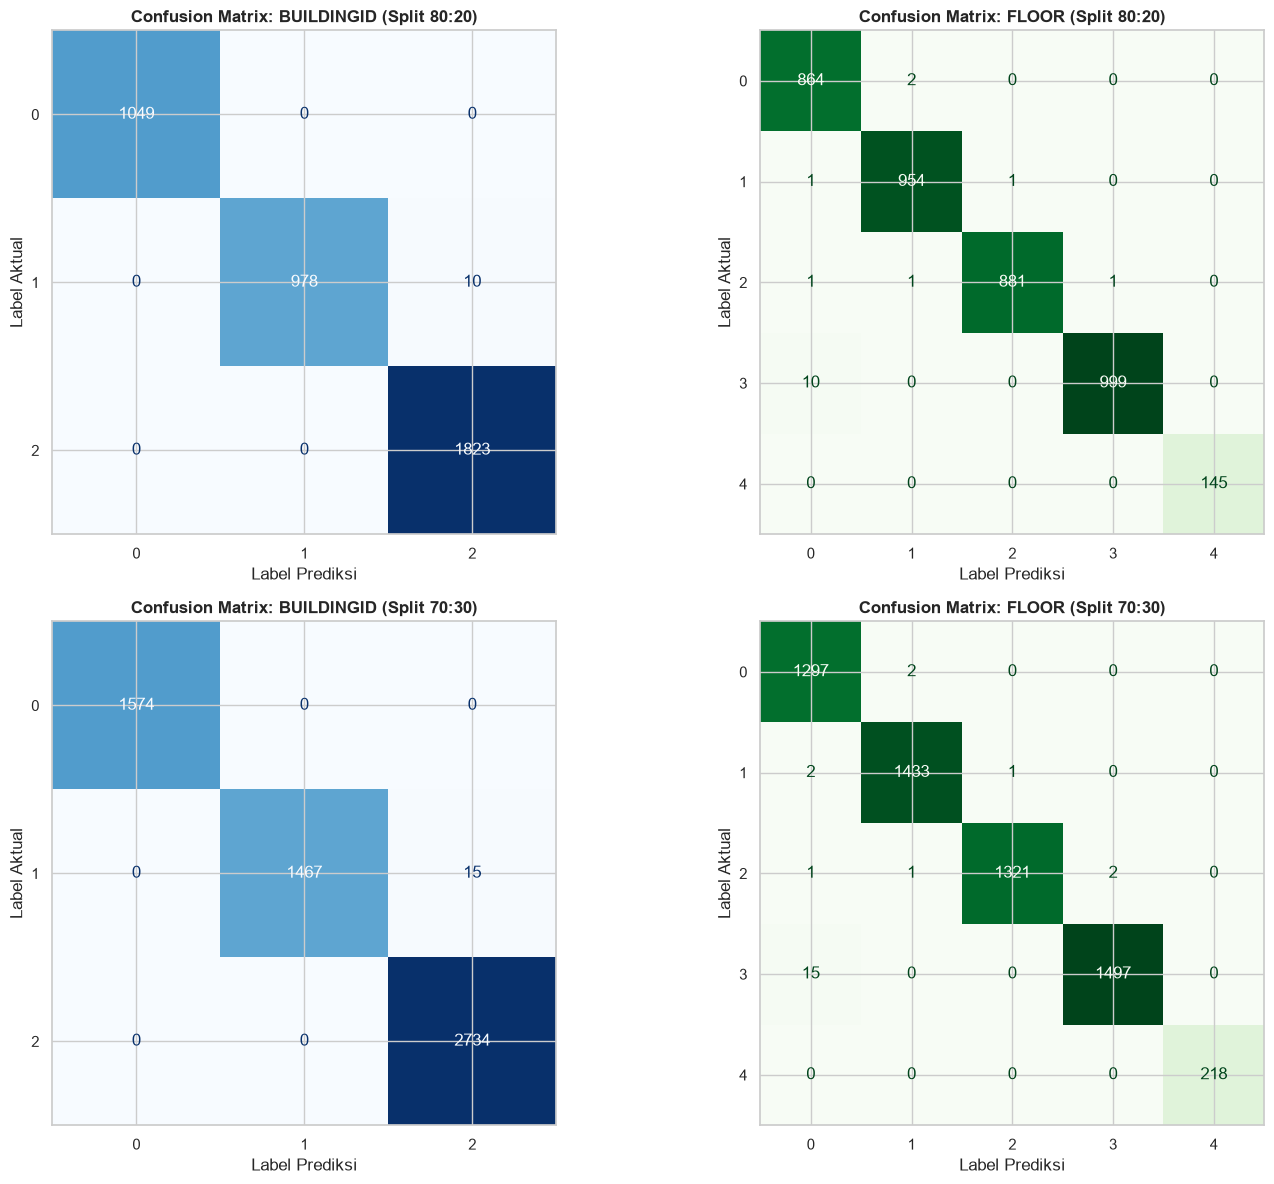

In [57]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_classification_test(model, X_train, y_train, X_test, y_test):
    pipeline = create_supervised_pipeline(model)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision Macro:", precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("Recall Macro:", recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("F1 Macro:", f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    return pipeline, y_pred


# BUILDINGID 80:20
print("=== BUILDINGID TEST 80:20 ===")
model_building_80, pred_building_80 = evaluate_classification_test(
  classification_models_building[
    results_building_80.iloc[0]["Model"]
],
    X_train_80, y_building_80,
    X_test_80, y_test_80["BUILDINGID"]
)

# FLOOR 80:20
print("\n=== FLOOR TEST 80:20 ===")
model_floor_80, pred_floor_80 = evaluate_classification_test(
    classification_models_floor[
    results_floor_80.iloc[0]["Model"]
],
    X_train_80, y_floor_80,
    X_test_80, y_test_80["FLOOR"]
)

# BUILDINGID 70:30
print("\n=== BUILDINGID TEST 70:30 ===")
model_building_70, pred_building_70 = evaluate_classification_test(
   classification_models_building[
    results_building_70.iloc[0]["Model"]
],
    X_train_70, y_building_70,
    X_test_70, y_test_70["BUILDINGID"]
)

# FLOOR 70:30
print("\n=== FLOOR TEST 70:30 ===")
model_floor_70, pred_floor_70 = evaluate_classification_test(
classification_models_floor[
    results_floor_70.iloc[0]["Model"]
],
    X_train_70, y_floor_70,
    X_test_70, y_test_70["FLOOR"]
)

# ==============================================================
# VISUALISASI WAJIB KLASIFIKASI: CONFUSION MATRIX
# ==============================================================
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. BUILDINGID 80:20
ConfusionMatrixDisplay.from_predictions(
    y_test_80["BUILDINGID"], pred_building_80,
    ax=axes[0, 0], cmap="Blues", colorbar=False
)
axes[0, 0].set_title("Confusion Matrix: BUILDINGID (Split 80:20)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Label Prediksi")
axes[0, 0].set_ylabel("Label Aktual")

# 2. FLOOR 80:20
ConfusionMatrixDisplay.from_predictions(
    y_test_80["FLOOR"], pred_floor_80,
    ax=axes[0, 1], cmap="Greens", colorbar=False
)
axes[0, 1].set_title("Confusion Matrix: FLOOR (Split 80:20)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Label Prediksi")
axes[0, 1].set_ylabel("Label Aktual")

# 3. BUILDINGID 70:30
ConfusionMatrixDisplay.from_predictions(
    y_test_70["BUILDINGID"], pred_building_70,
    ax=axes[1, 0], cmap="Blues", colorbar=False
)
axes[1, 0].set_title("Confusion Matrix: BUILDINGID (Split 70:30)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Label Prediksi")
axes[1, 0].set_ylabel("Label Aktual")

# 4. FLOOR 70:30
ConfusionMatrixDisplay.from_predictions(
    y_test_70["FLOOR"], pred_floor_70,
    ax=axes[1, 1], cmap="Greens", colorbar=False
)
axes[1, 1].set_title("Confusion Matrix: FLOOR (Split 70:30)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Label Prediksi")
axes[1, 1].set_ylabel("Label Aktual")

plt.tight_layout()
plt.show()

## 55. Validasi Ukuran Data Testing

Validasi dilakukan untuk memastikan jumlah baris pada data testing sesuai dengan skenario pembagian data 80:20 dan 70:30.

Pada skenario 80:20, data testing seharusnya berjumlah 3.860 baris. Sementara itu, pada skenario 70:30, data testing seharusnya berjumlah 5.790 baris.

Pemeriksaan dilakukan pada fitur dan seluruh target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE. Tahap ini bertujuan memastikan kesesuaian ukuran data sebelum evaluasi akhir model pada data testing.

In [58]:
print("=== VALIDASI DATA TESTING ===")

print("\nSkenario 80:20")
print("X_test_80:", X_test_80.shape)
print("BUILDINGID:", y_test_80["BUILDINGID"].shape)
print("FLOOR:", y_test_80["FLOOR"].shape)
print("LONGITUDE:", y_test_80["LONGITUDE"].shape)
print("LATITUDE:", y_test_80["LATITUDE"].shape)

print("\nSkenario 70:30")
print("X_test_70:", X_test_70.shape)
print("BUILDINGID:", y_test_70["BUILDINGID"].shape)
print("FLOOR:", y_test_70["FLOOR"].shape)
print("LONGITUDE:", y_test_70["LONGITUDE"].shape)
print("LATITUDE:", y_test_70["LATITUDE"].shape)

=== VALIDASI DATA TESTING ===

Skenario 80:20
X_test_80: (3860, 520)
BUILDINGID: (3860,)
FLOOR: (3860,)
LONGITUDE: (3860,)
LATITUDE: (3860,)

Skenario 70:30
X_test_70: (5790, 520)
BUILDINGID: (5790,)
FLOOR: (5790,)
LONGITUDE: (5790,)
LATITUDE: (5790,)


## 56. Evaluasi Model Regresi pada Data Testing

Evaluasi dilakukan terhadap model Random Forest untuk target LONGITUDE dan LATITUDE pada skenario pembagian data 80:20 dan 70:30.

Model dilatih menggunakan data training pada masing-masing skenario, kemudian menghasilkan prediksi pada data testing.

Metrik evaluasi yang digunakan meliputi Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), dan R-squared (R²).

Catatan metodologis: evaluasi data testing telah dilakukan pada tahap ini. Hasil evaluasi tidak digunakan untuk mengubah konfigurasi maupun memilih model.

In [59]:
def evaluate_regression_test(model, X_train, y_train, X_test, y_test):
    pipeline = create_supervised_pipeline(model)

    # Melatih model menggunakan seluruh data training
    pipeline.fit(X_train, y_train)

    # Prediksi pada data testing
    y_pred = pipeline.predict(X_test)

    # Menghitung metrik evaluasi
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"MAE  : {mae:.6f}")
    print(f"RMSE : {rmse:.6f}")
    print(f"R2   : {r2:.6f}")

    return pipeline, y_pred

## 57. Hasil Evaluasi Model Regresi pada Data Testing

Bagian ini menyajikan hasil evaluasi Random Forest untuk target LONGITUDE dan LATITUDE pada skenario 80:20 dan 70:30.

Hasil evaluasi mencakup nilai MAE, RMSE, dan R². Nilai tersebut digunakan untuk menggambarkan tingkat kesalahan dan kemampuan model dalam memprediksi koordinat.

=== MODEL REGRESI TERBAIK BERDASARKAN 5-FOLD CV ===
LONGITUDE 80:20: Random Forest
LATITUDE 80:20 : Random Forest
LONGITUDE 70:30: Random Forest
LATITUDE 70:30 : Random Forest
=== MODEL REGRESI TERBAIK BERDASARKAN 5-FOLD CV ===
LONGITUDE 80:20: Random Forest
LATITUDE 80:20 : Random Forest
LONGITUDE 70:30: Random Forest
LATITUDE 70:30 : Random Forest

=== LONGITUDE TEST 80:20 ===
Model: Random Forest
MAE  : 2.667383
RMSE : 7.235411
R2   : 0.996593

=== LATITUDE TEST 80:20 ===
Model: Random Forest
MAE  : 2.329880
RMSE : 6.008940
R2   : 0.992137

=== LONGITUDE TEST 70:30 ===
Model: Random Forest
MAE  : 2.840042
RMSE : 7.653467
R2   : 0.996183

=== LATITUDE TEST 70:30 ===
Model: Random Forest
MAE  : 2.473953
RMSE : 6.164651
R2   : 0.991669

GALAT POSISI 2D (MEAN POSITIONING ERROR) DALAM METER
Skenario 80:20 -> Mean: 4.02 m | Median: 2.04 m | P90: 8.39 m
Skenario 70:30 -> Mean: 4.24 m | Median: 2.27 m | P90: 8.70 m


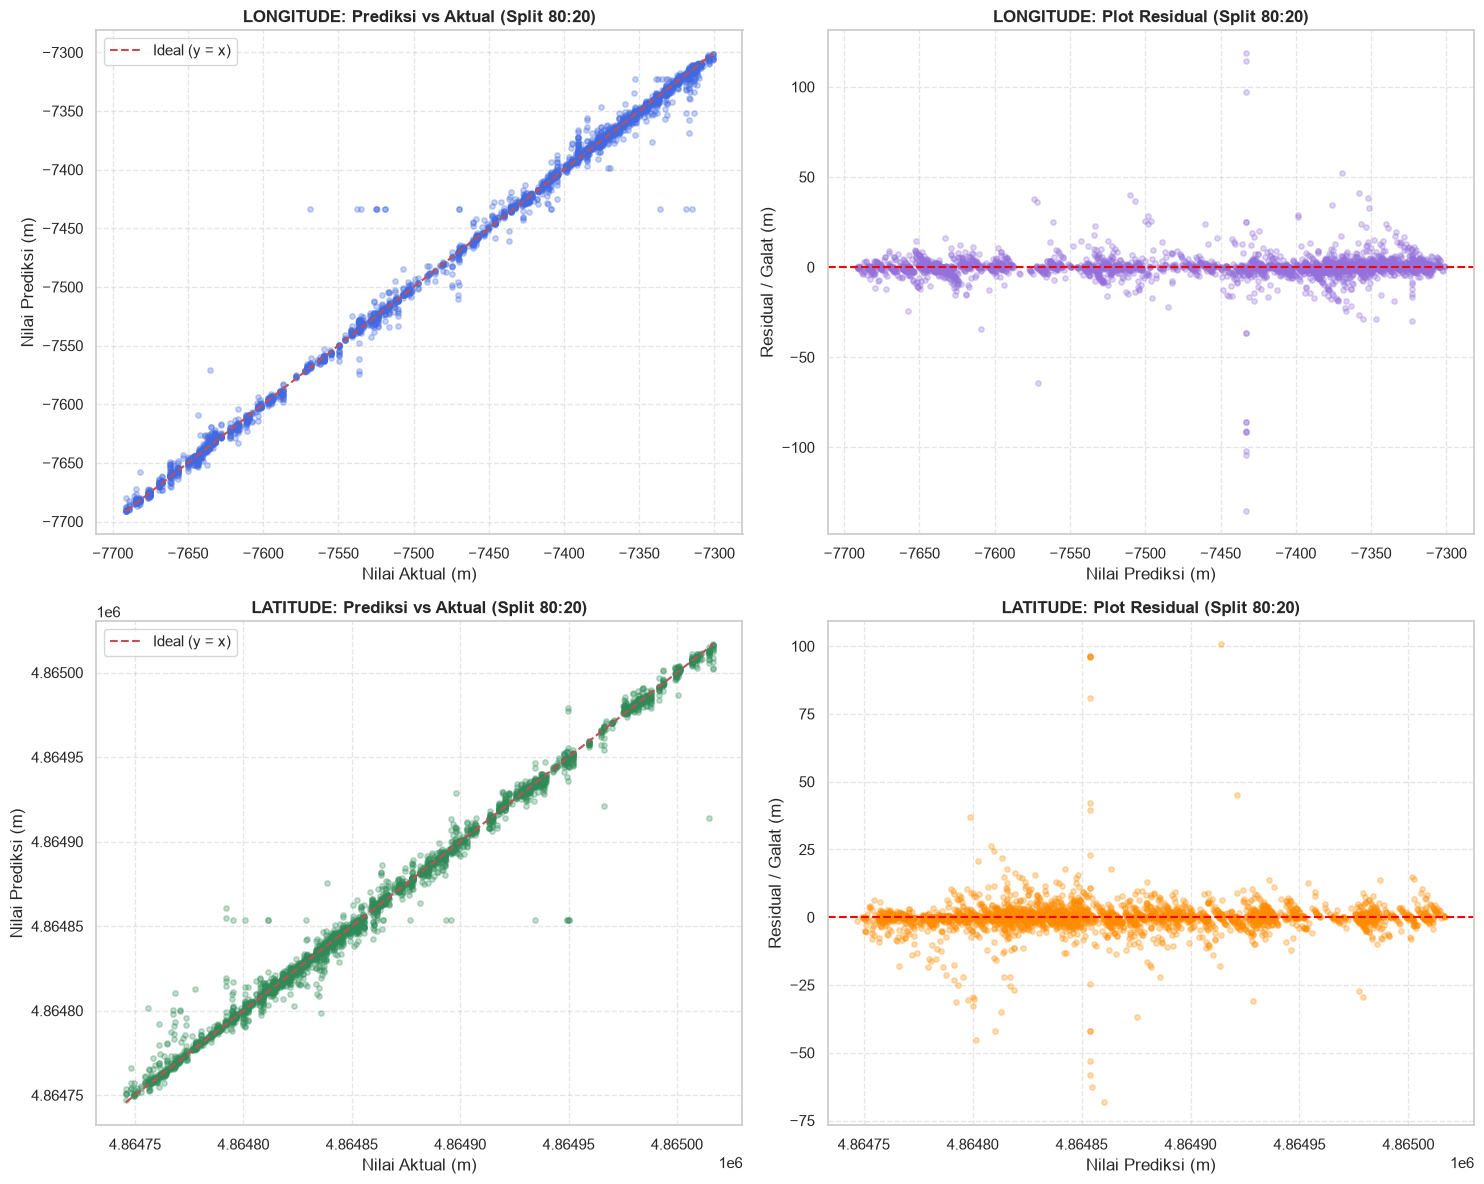

In [60]:

# MENENTUKAN MODEL REGRESI TERBAIK BERDASARKAN 5-FOLD CV


best_longitude_80 = results_longitude_80.sort_values(
    by="RMSE Mean", ascending=True
).iloc[0]["Model"]

best_latitude_80 = results_latitude_80.sort_values(
    by="RMSE Mean", ascending=True
).iloc[0]["Model"]

best_longitude_70 = results_longitude_70.sort_values(
    by="RMSE Mean", ascending=True
).iloc[0]["Model"]

best_latitude_70 = results_latitude_70.sort_values(
    by="RMSE Mean", ascending=True
).iloc[0]["Model"]


# Menampilkan model terpilih

print("=== MODEL REGRESI TERBAIK BERDASARKAN 5-FOLD CV ===")

print("LONGITUDE 80:20:", best_longitude_80)
print("LATITUDE 80:20 :", best_latitude_80)

print("LONGITUDE 70:30:", best_longitude_70)
print("LATITUDE 70:30 :", best_latitude_70)


# Menampilkan model terpilih

print("=== MODEL REGRESI TERBAIK BERDASARKAN 5-FOLD CV ===")

print("LONGITUDE 80:20:", best_longitude_80)
print("LATITUDE 80:20 :", best_latitude_80)

print("LONGITUDE 70:30:", best_longitude_70)
print("LATITUDE 70:30 :", best_latitude_70)


# PENGUJIAN MODEL TERBAIK PADA DATA TESTING
# LONGITUDE 80:20
print("\n=== LONGITUDE TEST 80:20 ===")
print("Model:", best_longitude_80)

model_longitude_80, pred_longitude_80 = evaluate_regression_test(
    regression_models[best_longitude_80],
    X_train_80, y_longitude_80,
    X_test_80, y_test_80["LONGITUDE"]
)


# LATITUDE 80:20
print("\n=== LATITUDE TEST 80:20 ===")
print("Model:", best_latitude_80)

model_latitude_80, pred_latitude_80 = evaluate_regression_test(
    regression_models[best_latitude_80],
    X_train_80, y_latitude_80,
    X_test_80, y_test_80["LATITUDE"]
)


# LONGITUDE 70:30
print("\n=== LONGITUDE TEST 70:30 ===")
print("Model:", best_longitude_70)

model_longitude_70, pred_longitude_70 = evaluate_regression_test(
    regression_models[best_longitude_70],
    X_train_70, y_longitude_70,
    X_test_70, y_test_70["LONGITUDE"]
)


# LATITUDE 70:30
print("\n=== LATITUDE TEST 70:30 ===")
print("Model:", best_latitude_70)

model_latitude_70, pred_latitude_70 = evaluate_regression_test(
    regression_models[best_latitude_70],
    X_train_70, y_latitude_70,
    X_test_70, y_test_70["LATITUDE"]
)

# ==============================================================
# PERHITUNGAN KHUSUS STUDI KASUS 1: GALAT POSISI RATA-RATA (METER)
# ==============================================================
# Jarak Euclidean galat posisi: sqrt((pred_x - actual_x)^2 + (pred_y - actual_y)^2)
pos_errors_80 = np.sqrt(
    (pred_longitude_80 - y_test_80["LONGITUDE"].to_numpy())**2 +
    (pred_latitude_80 - y_test_80["LATITUDE"].to_numpy())**2
)

pos_errors_70 = np.sqrt(
    (pred_longitude_70 - y_test_70["LONGITUDE"].to_numpy())**2 +
    (pred_latitude_70 - y_test_70["LATITUDE"].to_numpy())**2
)

print("\n" + "="*60)
print("GALAT POSISI 2D (MEAN POSITIONING ERROR) DALAM METER")
print("="*60)
print(f"Skenario 80:20 -> Mean: {np.mean(pos_errors_80):.2f} m | Median: {np.median(pos_errors_80):.2f} m | P90: {np.percentile(pos_errors_80, 90):.2f} m")
print(f"Skenario 70:30 -> Mean: {np.mean(pos_errors_70):.2f} m | Median: {np.median(pos_errors_70):.2f} m | P90: {np.percentile(pos_errors_70, 90):.2f} m")

# ==============================================================
# VISUALISASI WAJIB REGRESI: PREDIKSI VS AKTUAL & PLOT RESIDUAL
# ==============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. LONGITUDE Prediksi vs Aktual (80:20)
axes[0, 0].scatter(y_test_80["LONGITUDE"], pred_longitude_80, alpha=0.3, color="royalblue", s=15)
min_long = min(y_test_80["LONGITUDE"].min(), pred_longitude_80.min())
max_long = max(y_test_80["LONGITUDE"].max(), pred_longitude_80.max())
axes[0, 0].plot([min_long, max_long], [min_long, max_long], 'r--', lw=1.5, label="Ideal (y = x)")
axes[0, 0].set_title("LONGITUDE: Prediksi vs Aktual (Split 80:20)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Nilai Aktual (m)")
axes[0, 0].set_ylabel("Nilai Prediksi (m)")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# 2. LONGITUDE Plot Residual (80:20)
res_long = y_test_80["LONGITUDE"].to_numpy() - pred_longitude_80
axes[0, 1].scatter(pred_longitude_80, res_long, alpha=0.3, color="mediumpurple", s=15)
axes[0, 1].axhline(0, color="red", linestyle="--", lw=1.5)
axes[0, 1].set_title("LONGITUDE: Plot Residual (Split 80:20)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Nilai Prediksi (m)")
axes[0, 1].set_ylabel("Residual / Galat (m)")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. LATITUDE Prediksi vs Aktual (80:20)
axes[1, 0].scatter(y_test_80["LATITUDE"], pred_latitude_80, alpha=0.3, color="seagreen", s=15)
min_lat = min(y_test_80["LATITUDE"].min(), pred_latitude_80.min())
max_lat = max(y_test_80["LATITUDE"].max(), pred_latitude_80.max())
axes[1, 0].plot([min_lat, max_lat], [min_lat, max_lat], 'r--', lw=1.5, label="Ideal (y = x)")
axes[1, 0].set_title("LATITUDE: Prediksi vs Aktual (Split 80:20)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Nilai Aktual (m)")
axes[1, 0].set_ylabel("Nilai Prediksi (m)")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# 4. LATITUDE Plot Residual (80:20)
res_lat = y_test_80["LATITUDE"].to_numpy() - pred_latitude_80
axes[1, 1].scatter(pred_latitude_80, res_lat, alpha=0.3, color="darkorange", s=15)
axes[1, 1].axhline(0, color="red", linestyle="--", lw=1.5)
axes[1, 1].set_title("LATITUDE: Plot Residual (Split 80:20)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Nilai Prediksi (m)")
axes[1, 1].set_ylabel("Residual / Galat (m)")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 58. Verifikasi Ulang Evaluasi Klasifikasi pada Data Testing

Evaluasi klasifikasi diperiksa kembali untuk memastikan kesesuaian antara skenario pembagian data, jumlah sampel pengujian, dan hasil prediksi model.

Pemeriksaan dilakukan pada target BUILDINGID dan FLOOR untuk skenario 80:20 dan 70:30.

In [61]:
# Verifikasi klasifikasi BUILDINGID 80:20
print("=== BUILDINGID 80:20 ===")
print("Jumlah data aktual:", len(y_test_80["BUILDINGID"]))
print("Jumlah prediksi:", len(pred_building_80))
print(classification_report(
    y_test_80["BUILDINGID"],
    pred_building_80,
    zero_division=0
))

# Verifikasi klasifikasi FLOOR 80:20
print("\n=== FLOOR 80:20 ===")
print("Jumlah data aktual:", len(y_test_80["FLOOR"]))
print("Jumlah prediksi:", len(pred_floor_80))
print(classification_report(
    y_test_80["FLOOR"],
    pred_floor_80,
    zero_division=0
))

# Verifikasi klasifikasi BUILDINGID 70:30
print("\n=== BUILDINGID 70:30 ===")
print("Jumlah data aktual:", len(y_test_70["BUILDINGID"]))
print("Jumlah prediksi:", len(pred_building_70))
print(classification_report(
    y_test_70["BUILDINGID"],
    pred_building_70,
    zero_division=0
))

# Verifikasi klasifikasi FLOOR 70:30
print("\n=== FLOOR 70:30 ===")
print("Jumlah data aktual:", len(y_test_70["FLOOR"]))
print("Jumlah prediksi:", len(pred_floor_70))
print(classification_report(
    y_test_70["FLOOR"],
    pred_floor_70,
    zero_division=0
))

=== BUILDINGID 80:20 ===
Jumlah data aktual: 3860
Jumlah prediksi: 3860
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1049
           1       1.00      0.99      0.99       988
           2       0.99      1.00      1.00      1823

    accuracy                           1.00      3860
   macro avg       1.00      1.00      1.00      3860
weighted avg       1.00      1.00      1.00      3860


=== FLOOR 80:20 ===
Jumlah data aktual: 3860
Jumlah prediksi: 3860
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       866
           1       1.00      1.00      1.00       956
           2       1.00      1.00      1.00       884
           3       1.00      0.99      0.99      1009
           4       1.00      1.00      1.00       145

    accuracy                           1.00      3860
   macro avg       1.00      1.00      1.00      3860
weighted avg       1.00      1.00      1.00  

## 59. Ringkasan Verifikasi Hasil Klasifikasi Testing

Tahap ini merangkum hasil evaluasi klasifikasi pada data testing untuk memastikan kesesuaian jumlah data aktual, jumlah prediksi, accuracy, dan macro F1-score pada kedua skenario pembagian data.

In [62]:
from sklearn.metrics import accuracy_score, f1_score

classification_test_summary = pd.DataFrame([
    {
        "Skenario": "80:20",
        "Target": "BUILDINGID",
        "Data Testing": len(y_test_80["BUILDINGID"]),
        "Jumlah Prediksi": len(pred_building_80),
        "Accuracy": accuracy_score(
            y_test_80["BUILDINGID"], pred_building_80
        ),
        "Macro F1": f1_score(
            y_test_80["BUILDINGID"], pred_building_80,
            average="macro"
        )
    },
    {
        "Skenario": "80:20",
        "Target": "FLOOR",
        "Data Testing": len(y_test_80["FLOOR"]),
        "Jumlah Prediksi": len(pred_floor_80),
        "Accuracy": accuracy_score(
            y_test_80["FLOOR"], pred_floor_80
        ),
        "Macro F1": f1_score(
            y_test_80["FLOOR"], pred_floor_80,
            average="macro"
        )
    },
    {
        "Skenario": "70:30",
        "Target": "BUILDINGID",
        "Data Testing": len(y_test_70["BUILDINGID"]),
        "Jumlah Prediksi": len(pred_building_70),
        "Accuracy": accuracy_score(
            y_test_70["BUILDINGID"], pred_building_70
        ),
        "Macro F1": f1_score(
            y_test_70["BUILDINGID"], pred_building_70,
            average="macro"
        )
    },
    {
        "Skenario": "70:30",
        "Target": "FLOOR",
        "Data Testing": len(y_test_70["FLOOR"]),
        "Jumlah Prediksi": len(pred_floor_70),
        "Accuracy": accuracy_score(
            y_test_70["FLOOR"], pred_floor_70
        ),
        "Macro F1": f1_score(
            y_test_70["FLOOR"], pred_floor_70,
            average="macro"
        )
    }
])

display(classification_test_summary.round(6))

,Skenario,Target,Data Testing,Jumlah Prediksi,Accuracy,Macro F1
0,80:20,BUILDINGID,3860,3860,0.997409,0.997393
1,80:20,FLOOR,3860,3860,0.995596,0.996322
2,70:30,BUILDINGID,5790,5790,0.997409,0.997393
3,70:30,FLOOR,5790,5790,0.995855,0.996545


## 60. Rekapitulasi Hasil Supervised Learning

Bagian ini menyajikan ringkasan hasil evaluasi model supervised learning berdasarkan cross-validation dan pengujian pada data testing.

Rekapitulasi mencakup model terbaik, metrik evaluasi, dan perbandingan dua skenario pembagian data, yaitu 80:20 dan 70:30.

In [63]:
# REKAPITULASI HASIL KLASIFIKASI

classification_summary = pd.concat([
    results_building_80.assign(
        Skenario="80:20", Target="BUILDINGID"
    ),
    results_floor_80.assign(
        Skenario="80:20", Target="FLOOR"
    ),
    results_building_70.assign(
        Skenario="70:30", Target="BUILDINGID"
    ),
    results_floor_70.assign(
        Skenario="70:30", Target="FLOOR"
    )
], ignore_index=True)


# REKAPITULASI HASIL REGRESI

regression_summary = pd.concat([
    results_longitude_80.assign(
        Skenario="80:20", Target="LONGITUDE"
    ),
    results_latitude_80.assign(
        Skenario="80:20", Target="LATITUDE"
    ),
    results_longitude_70.assign(
        Skenario="70:30", Target="LONGITUDE"
    ),
    results_latitude_70.assign(
        Skenario="70:30", Target="LATITUDE"
    )
], ignore_index=True)

# MENAMPILKAN HASIL REKAPITULASI

print("=== REKAPITULASI HASIL KLASIFIKASI ===")
display(classification_summary)

print("\n=== HASIL EVALUASI KLASIFIKASI TESTING ===")
display(classification_test_summary)

print("\n=== REKAPITULASI HASIL REGRESI ===")
display(regression_summary)

=== REKAPITULASI HASIL KLASIFIKASI ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean,Skenario,Target
0,Logistic Regression,0.998381,0.000679,0.998862,0.000476,0.997895,0.000888,0.998374,0.000686,0.998381,80:20,BUILDINGID
1,Random Forest,0.998316,0.000660,0.998782,0.000464,0.997811,0.000861,0.998292,0.000665,0.998381,80:20,BUILDINGID
2,KNN,0.998057,0.000579,0.998595,0.000391,0.997512,0.000782,0.998048,0.000586,0.998235,80:20,BUILDINGID
3,Gradient Boosting,0.997798,0.000692,0.997158,0.000885,0.998412,0.000496,0.997776,0.000694,0.997798,80:20,BUILDINGID
4,Decision Tree,0.996762,0.000766,0.997456,0.000603,0.996009,0.000939,0.996723,0.000761,0.998381,80:20,BUILDINGID
5,SVM,0.995920,0.000995,0.996034,0.001203,0.995849,0.000796,0.995928,0.000919,0.998203,80:20,BUILDINGID
6,Random Forest,0.996891,0.001305,0.997344,0.001112,0.996618,0.001967,0.996972,0.001499,0.998316,80:20,FLOOR
7,Logistic Regression,0.991839,0.001915,0.990800,0.002198,0.993033,0.002027,0.991895,0.002007,0.998025,80:20,FLOOR
8,SVM,0.989573,0.000804,0.991220,0.000711,0.988950,0.000931,0.990037,0.000813,0.995855,80:20,FLOOR
9,KNN,0.980440,0.001895,0.980486,0.003505,0.981648,0.002488,0.981035,0.002944,0.988682,80:20,FLOOR



=== HASIL EVALUASI KLASIFIKASI TESTING ===


,Skenario,Target,Data Testing,Jumlah Prediksi,Accuracy,Macro F1
0,80:20,BUILDINGID,3860,3860,0.997409,0.997393
1,80:20,FLOOR,3860,3860,0.995596,0.996322
2,70:30,BUILDINGID,5790,5790,0.997409,0.997393
3,70:30,FLOOR,5790,5790,0.995855,0.996545



=== REKAPITULASI HASIL REGRESI ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean,Skenario,Target
0,Random Forest,3.086458,0.097516,8.341325,0.674437,0.995459,0.000760,1.378732,6.184420,0.997520,80:20,LONGITUDE
1,Decision Tree,3.291495,0.162580,10.637231,1.152113,0.992576,0.001706,0.376003,5.818444,0.997804,80:20,LONGITUDE
2,Gradient Boosting,15.984632,0.269807,22.426812,0.418466,0.967393,0.001313,15.485249,21.647216,0.969644,80:20,LONGITUDE
3,Ridge Regression,20.575820,0.168092,28.126877,0.258219,0.948722,0.001271,19.809768,27.185248,0.952125,80:20,LONGITUDE
4,Linear Regression,20.576482,0.167979,28.127821,0.258347,0.948719,0.001272,19.809575,27.185246,0.952125,80:20,LONGITUDE
5,SVR,30.847034,0.591650,49.395813,0.949900,0.841848,0.005593,30.477306,48.945105,0.844814,80:20,LONGITUDE
6,Random Forest,2.449973,0.100758,5.702763,0.613961,0.992787,0.001530,1.062471,4.082982,0.996335,80:20,LATITUDE
7,Decision Tree,2.682104,0.143538,7.841120,0.546092,0.986462,0.001787,0.253637,3.763072,0.996884,80:20,LATITUDE
8,Gradient Boosting,10.771257,0.213155,14.556369,0.364732,0.953478,0.002215,10.402269,14.034235,0.956802,80:20,LATITUDE
9,Ridge Regression,13.083572,0.159465,17.642853,0.359124,0.931649,0.003138,12.603368,17.047335,0.936261,80:20,LATITUDE


## 61. Konfigurasi Model Polynomial Regression

Polynomial Regression ditambahkan sebagai model regresi terpisah dari Ridge Regression.

Untuk mengendalikan pertumbuhan jumlah fitur akibat transformasi polinomial, PCA digunakan untuk mereduksi fitur menjadi 20 komponen sebelum PolynomialFeatures derajat 2 diterapkan.

Seluruh tahapan PCA, transformasi polinomial, dan regresi dilakukan di dalam Pipeline agar proses fitting berlangsung hanya pada data training setiap fold cross-validation.

In [64]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PolynomialFeatures

polynomial_regression = Pipeline([
    ("pca", PCA(
        n_components=20,
        random_state=42
    )),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("ridge", Ridge(alpha=1.0))
])

regression_models["Polynomial Regression"] = polynomial_regression

print("Model regresi yang tersedia:")
for model_name in regression_models:
    print("-", model_name)

print("\nJumlah model regresi:", len(regression_models))

Model regresi yang tersedia:
- Linear Regression
- Ridge Regression
- SVR
- Decision Tree
- Random Forest
- Gradient Boosting
- Polynomial Regression

Jumlah model regresi: 7


## 62. Evaluasi Cross-Validation Polynomial Regression

Evaluasi Polynomial Regression dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan 5-fold KFold Cross-Validation.

Model menggunakan PCA dengan 20 komponen, PolynomialFeatures derajat 2, dan Ridge Regression sebagai estimator. Evaluasi dilakukan pada skenario 80:20 dan 70:30.

Metrik yang digunakan adalah MAE, RMSE, dan R².

In [65]:
# Mengambil model Polynomial Regression
polynomial_model = {
    "Polynomial Regression": regression_models[
        "Polynomial Regression"
    ]
}

# Skenario 80:20
print("=== POLYNOMIAL REGRESSION LONGITUDE (80:20) ===")
poly_longitude_80 = evaluate_regression_cv(
    polynomial_model,
    X_train_80,
    y_longitude_80,
    cv_regression
)
display(poly_longitude_80)

print("=== POLYNOMIAL REGRESSION LATITUDE (80:20) ===")
poly_latitude_80 = evaluate_regression_cv(
    polynomial_model,
    X_train_80,
    y_latitude_80,
    cv_regression
)
display(poly_latitude_80)

# Skenario 70:30
print("=== POLYNOMIAL REGRESSION LONGITUDE (70:30) ===")
poly_longitude_70 = evaluate_regression_cv(
    polynomial_model,
    X_train_70,
    y_longitude_70,
    cv_regression
)
display(poly_longitude_70)

print("=== POLYNOMIAL REGRESSION LATITUDE (70:30) ===")
poly_latitude_70 = evaluate_regression_cv(
    polynomial_model,
    X_train_70,
    y_latitude_70,
    cv_regression
)
display(poly_latitude_70)

=== POLYNOMIAL REGRESSION LONGITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,15.176833,0.259709,22.339838,0.314771,0.96765,0.001006,14.873234,21.802734,0.969206


=== POLYNOMIAL REGRESSION LATITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,9.866298,0.186422,14.03411,0.361763,0.956751,0.002188,9.667498,13.701803,0.958824


=== POLYNOMIAL REGRESSION LONGITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,15.293189,0.115222,22.450876,0.302975,0.967365,0.000961,14.925876,21.86669,0.969063


=== POLYNOMIAL REGRESSION LATITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,9.879622,0.11169,14.010633,0.224553,0.957005,0.001311,9.669263,13.706268,0.958872


## 63. Rekapitulasi Hasil Cross-Validation Model Regresi

Bagian ini menyajikan perbandingan enam model regresi berdasarkan hasil 5-fold cross-validation pada skenario 80:20 dan 70:30.

Perbandingan dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan metrik MAE, RMSE, dan R².

In [66]:
# Menggabungkan hasil enam model regresi

regression_longitude_80_all = pd.concat(
    [results_longitude_80, poly_longitude_80],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_latitude_80_all = pd.concat(
    [results_latitude_80, poly_latitude_80],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_longitude_70_all = pd.concat(
    [results_longitude_70, poly_longitude_70],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_latitude_70_all = pd.concat(
    [results_latitude_70, poly_latitude_70],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)


print("=== LONGITUDE 80:20 ===")
display(regression_longitude_80_all)

print("=== LATITUDE 80:20 ===")
display(regression_latitude_80_all)

print("=== LONGITUDE 70:30 ===")
display(regression_longitude_70_all)

print("=== LATITUDE 70:30 ===")
display(regression_latitude_70_all)

=== LONGITUDE 80:20 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.086458,0.097516,8.341325,0.674437,0.995459,0.000760,1.378732,6.184420,0.997520
1,Decision Tree,3.291495,0.162580,10.637231,1.152113,0.992576,0.001706,0.376003,5.818444,0.997804
2,Polynomial Regression,15.176833,0.259709,22.339838,0.314771,0.967650,0.001006,14.873234,21.802734,0.969206
3,Gradient Boosting,15.984632,0.269807,22.426812,0.418466,0.967393,0.001313,15.485249,21.647216,0.969644
4,Ridge Regression,20.575820,0.168092,28.126877,0.258219,0.948722,0.001271,19.809768,27.185248,0.952125
5,Linear Regression,20.576482,0.167979,28.127821,0.258347,0.948719,0.001272,19.809575,27.185246,0.952125
6,SVR,30.847034,0.591650,49.395813,0.949900,0.841848,0.005593,30.477306,48.945105,0.844814


=== LATITUDE 80:20 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.449973,0.100758,5.702763,0.613961,0.992787,0.001530,1.062471,4.082982,0.996335
1,Decision Tree,2.682104,0.143538,7.841120,0.546092,0.986462,0.001787,0.253637,3.763072,0.996884
2,Polynomial Regression,9.866298,0.186422,14.034110,0.361763,0.956751,0.002188,9.667498,13.701803,0.958824
3,Gradient Boosting,10.771257,0.213155,14.556369,0.364732,0.953478,0.002215,10.402269,14.034235,0.956802
4,Ridge Regression,13.083572,0.159465,17.642853,0.359124,0.931649,0.003138,12.603368,17.047335,0.936261
5,Linear Regression,13.084160,0.159443,17.643415,0.359086,0.931645,0.003137,12.603486,17.047333,0.936261
6,SVR,16.582319,0.282912,27.856981,0.691262,0.829672,0.006847,16.277351,27.507128,0.834051


=== LONGITUDE 70:30 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.289249,0.139315,8.376538,0.653425,0.995440,0.000632,1.448727,6.134773,0.997560
1,Decision Tree,3.621818,0.111696,11.353254,0.504719,0.991632,0.000856,0.362780,5.713943,0.997882
2,Gradient Boosting,16.134503,0.250897,22.425685,0.605069,0.967411,0.001947,15.550396,21.621279,0.969753
3,Polynomial Regression,15.293189,0.115222,22.450876,0.302975,0.967365,0.000961,14.925876,21.866690,0.969063
4,Ridge Regression,20.676906,0.365340,28.302483,0.602361,0.948155,0.001348,19.769261,27.128459,0.952385
5,Linear Regression,20.678172,0.364315,28.304640,0.601359,0.948147,0.001344,19.769112,27.128454,0.952385
6,SVR,32.414371,0.767935,51.113036,1.191306,0.830855,0.006582,32.002439,50.608872,0.834286


=== LATITUDE 70:30 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.602402,0.119031,5.889187,0.423506,0.992369,0.001085,1.114670,3.999904,0.996490
1,Decision Tree,2.868881,0.138448,7.837475,0.389192,0.986518,0.001315,0.241739,3.616815,0.997127
2,Polynomial Regression,9.879622,0.111690,14.010633,0.224553,0.957005,0.001311,9.669263,13.706268,0.958872
3,Gradient Boosting,10.823916,0.219283,14.592304,0.197342,0.953354,0.001543,10.414644,14.020109,0.956968
4,Ridge Regression,13.161073,0.180569,17.741191,0.300158,0.931068,0.001927,12.594059,17.008464,0.936671
5,Linear Regression,13.161791,0.180527,17.741933,0.300093,0.931063,0.001927,12.594226,17.008462,0.936671
6,SVR,17.249727,0.376313,28.565419,0.573386,0.821267,0.006568,16.919024,28.216176,0.825708


63A. Hyperparameter Tuning

Tuning memakai `GridSearchCV` dengan 5-fold CV yang sama seperti sebelumnya (stratified untuk klasifikasi dan KFold untuk regresi), dan dijalankan di dalam data training saja. Pipeline preprocessing (sentinel -105 dBm, fitur tereduksi, StandardScaler) ikut berada di dalam pencarian, sehingga tidak ada kebocoran data.

Cakupan tuning:

1) BUILDINGID tidak dituning karena semua model sudah mencapai Macro F1 di atas 0,99 sehingga ruang perbaikannya sangat kecil.
2) FLOOR dituning pada KNN (jumlah tetangga dan pembobotan), SVM (parameter C), Decision Tree (`min_samples_leaf`), dan Random Forest (`max_features`). Metrik seleksi adalah Macro F1.
3) LONGITUDE dan LATITUDE dituning pada Ridge (alpha), Decision Tree (`min_samples_leaf`), SVR, dan Random Forest (`max_features`). Metrik seleksi adalah RMSE.
4) SVR pada tuning dibungkus `TransformedTargetRegressor` yang menstandardisasi target. Pada Bagian 52 dan 53 SVR memakai target mentah (nilai LONGITUDE sekitar -7.500 dan LATITUDE sekitar 4.864.900), sehingga hasilnya jauh tertinggal. Standardisasi target menguji apakah kelemahan itu berasal dari pengaturan, bukan dari algoritmanya.
5) Gradient Boosting tidak dituning karena waktu komputasinya paling besar. Grid dibuat kecil agar waktu pencarian wajar, jadi hasilnya menunjukkan arah perbaikan dan bukan pencarian yang menyeluruh.

Skenario 80:20 dipakai sebagai skenario utama dan menuning 70:30.

In [67]:
import time
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

SKENARIO_TUNING = {
    "80:20": {
        "X_train": X_train_80, "X_test": X_test_80,
        "y_train": y_train_80, "y_test": y_test_80,
        "dasar": {
            "FLOOR": results_floor_80,
            "LONGITUDE": regression_longitude_80_all,
            "LATITUDE": regression_latitude_80_all,
        },
    },
    "70:30": {
         "X_train": X_train_70, "X_test": X_test_70,
         "y_train": y_train_70, "y_test": y_test_70,
         "dasar": {
             "FLOOR": results_floor_70,
             "LONGITUDE": regression_longitude_70_all,
             "LATITUDE": regression_latitude_70_all,
         },
     },
}

# Grid pencarian (awalan model__ karena model berada di dalam Pipeline)
grid_floor = {
    "KNN": (clone(classification_models_floor["KNN"]),
            {"model__n_neighbors": [1, 3, 5, 9, 15], "model__weights": ["uniform", "distance"]}),
    "SVM": (clone(classification_models_floor["SVM"]),
            {"model__C": [1, 10, 100]}),
    "Decision Tree": (clone(classification_models_floor["Decision Tree"]),
                      {"model__min_samples_leaf": [1, 3, 10]}),
    "Random Forest": (clone(classification_models_floor["Random Forest"]),
                      {"model__max_features": ["sqrt", 0.1, 0.3]}),
}

svr_target_standar = TransformedTargetRegressor(
    regressor=clone(regression_models["SVR"]),
    transformer=StandardScaler()
)

grid_regresi = {
    "Ridge Regression": (clone(regression_models["Ridge Regression"]),
                         {"model__alpha": [0.1, 1, 10, 100, 1000]}),
    "Decision Tree": (clone(regression_models["Decision Tree"]),
                      {"model__min_samples_leaf": [1, 3, 10]}),
    "SVR (target distandardisasi)": (svr_target_standar,
                                     {"model__regressor__C": [1, 10, 100]}),
    "Random Forest": (clone(regression_models["Random Forest"]),
                      {"model__max_features": [0.3, 0.6, 1.0]}),
}

hasil_tuning = []
model_tuning_terbaik = {}   # (target, skenario) -> (nama model, pipeline hasil tuning)

for nama_skenario, d in SKENARIO_TUNING.items():
    for target in ["FLOOR", "LONGITUDE", "LATITUDE"]:
        klasifikasi = target == "FLOOR"
        grid_semua = grid_floor if klasifikasi else grid_regresi
        cv = cv_classification if klasifikasi else cv_regression
        skor = "f1_macro" if klasifikasi else "neg_root_mean_squared_error"
        tabel_dasar = d["dasar"][target]
        kandidat = []

        for nama_model, (model, grid) in grid_semua.items():
            mulai = time.time()
            gs = GridSearchCV(
                create_supervised_pipeline(model), grid,
                cv=cv, scoring=skor, n_jobs=-1, refit=True
            )
            gs.fit(d["X_train"], d["y_train"][target])
            i = gs.best_index_

            nama_dasar = "SVR" if nama_model.startswith("SVR") else nama_model
            if klasifikasi:
                dasar = tabel_dasar.loc[tabel_dasar["Model"] == nama_dasar, "F1 Macro Mean"].iloc[0]
                tuning = gs.cv_results_["mean_test_score"][i]
                perbaikan = tuning - dasar
                ukuran = "Macro F1 CV (naik = lebih baik)"
            else:
                dasar = tabel_dasar.loc[tabel_dasar["Model"] == nama_dasar, "RMSE Mean"].iloc[0]
                tuning = -gs.cv_results_["mean_test_score"][i]
                perbaikan = dasar - tuning
                ukuran = "RMSE CV dalam meter (turun = lebih baik)"

            parameter = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
            hasil_tuning.append({
                "Skenario": nama_skenario, "Target": target, "Model": nama_model,
                "Parameter terbaik": str(parameter),
                "Skor CV bawaan": dasar, "Skor CV tuning": tuning, "Perbaikan": perbaikan,
                "Jumlah kombinasi": len(gs.cv_results_["params"]),
                "Waktu (detik)": time.time() - mulai, "Ukuran": ukuran
            })
            kandidat.append((tuning, nama_model, gs.best_estimator_))
            print(f"selesai: {nama_skenario} | {target} | {nama_model} | {time.time() - mulai:.0f} detik")

        # model tuning terbaik dipilih hanya dari skor CV
        pilih = max(kandidat, key=lambda k: k[0]) if klasifikasi else min(kandidat, key=lambda k: k[0])
        model_tuning_terbaik[(target, nama_skenario)] = (pilih[1], pilih[2])

tabel_tuning = pd.DataFrame(hasil_tuning)
for nama_skenario in SKENARIO_TUNING:
    for target in ["FLOOR", "LONGITUDE", "LATITUDE"]:
        print(f"\n=== HASIL TUNING {target} ({nama_skenario}) ===")
        display(tabel_tuning[(tabel_tuning["Skenario"] == nama_skenario) & (tabel_tuning["Target"] == target)]
                .drop(columns=["Skenario", "Target"]).reset_index(drop=True))

selesai: 80:20 | FLOOR | KNN | 20 detik
selesai: 80:20 | FLOOR | SVM | 123 detik
selesai: 80:20 | FLOOR | Decision Tree | 5 detik
selesai: 80:20 | FLOOR | Random Forest | 37 detik
selesai: 80:20 | LONGITUDE | Ridge Regression | 5 detik
selesai: 80:20 | LONGITUDE | Decision Tree | 4 detik
selesai: 80:20 | LONGITUDE | SVR (target distandardisasi) | 128 detik
selesai: 80:20 | LONGITUDE | Random Forest | 121 detik
selesai: 80:20 | LATITUDE | Ridge Regression | 7 detik
selesai: 80:20 | LATITUDE | Decision Tree | 6 detik
selesai: 80:20 | LATITUDE | SVR (target distandardisasi) | 180 detik
selesai: 80:20 | LATITUDE | Random Forest | 146 detik
selesai: 70:30 | FLOOR | KNN | 19 detik
selesai: 70:30 | FLOOR | SVM | 128 detik
selesai: 70:30 | FLOOR | Decision Tree | 5 detik
selesai: 70:30 | FLOOR | Random Forest | 39 detik
selesai: 70:30 | LONGITUDE | Ridge Regression | 6 detik
selesai: 70:30 | LONGITUDE | Decision Tree | 6 detik
selesai: 70:30 | LONGITUDE | SVR (target distandardisasi) | 109 det

,Model,Parameter terbaik,Skor CV bawaan,Skor CV tuning,Perbaikan,Jumlah kombinasi,Waktu (detik),Ukuran
0,KNN,"{'n_neighbors': 1, 'weights': 'uniform'}",0.981035,0.987418,0.006383,10,20.101086,Macro F1 CV (naik = lebih baik)
1,SVM,{'C': 10},0.990037,0.992250,0.002214,3,122.974928,Macro F1 CV (naik = lebih baik)
2,Decision Tree,{'min_samples_leaf': 1},0.967242,0.967242,0.000000,3,5.196080,Macro F1 CV (naik = lebih baik)
3,Random Forest,{'max_features': 'sqrt'},0.996972,0.996972,0.000000,3,37.179625,Macro F1 CV (naik = lebih baik)



=== HASIL TUNING LONGITUDE (80:20) ===


,Model,Parameter terbaik,Skor CV bawaan,Skor CV tuning,Perbaikan,Jumlah kombinasi,Waktu (detik),Ukuran
0,Ridge Regression,{'alpha': 100},28.126877,28.076392,0.050484,5,5.126053,RMSE CV dalam meter (turun = lebih baik)
1,Decision Tree,{'min_samples_leaf': 1},10.637231,10.637231,0.000000,3,4.350451,RMSE CV dalam meter (turun = lebih baik)
2,SVR (target distandardisasi),{'regressor__C': 10},49.395813,19.854381,29.541431,3,128.260677,RMSE CV dalam meter (turun = lebih baik)
3,Random Forest,{'max_features': 0.3},8.341325,7.656140,0.685185,3,121.127562,RMSE CV dalam meter (turun = lebih baik)



=== HASIL TUNING LATITUDE (80:20) ===


,Model,Parameter terbaik,Skor CV bawaan,Skor CV tuning,Perbaikan,Jumlah kombinasi,Waktu (detik),Ukuran
0,Ridge Regression,{'alpha': 100},17.642853,17.611412,0.031441,5,7.313264,RMSE CV dalam meter (turun = lebih baik)
1,Decision Tree,{'min_samples_leaf': 1},7.841120,7.841120,0.000000,3,5.582319,RMSE CV dalam meter (turun = lebih baik)
2,SVR (target distandardisasi),{'regressor__C': 10},27.856981,12.135723,15.721258,3,179.782700,RMSE CV dalam meter (turun = lebih baik)
3,Random Forest,{'max_features': 0.3},5.702763,5.154403,0.548360,3,145.529840,RMSE CV dalam meter (turun = lebih baik)


... (2 outputs left out)


=== HASIL TUNING LONGITUDE (70:30) ===


,Model,Parameter terbaik,Skor CV bawaan,Skor CV tuning,Perbaikan,Jumlah kombinasi,Waktu (detik),Ukuran
0,Ridge Regression,{'alpha': 100},28.302483,28.222280,0.080202,5,6.151526,RMSE CV dalam meter (turun = lebih baik)
1,Decision Tree,{'min_samples_leaf': 1},11.353254,11.353254,0.000000,3,5.608403,RMSE CV dalam meter (turun = lebih baik)
2,SVR (target distandardisasi),{'regressor__C': 10},51.113036,20.282134,30.830902,3,108.940156,RMSE CV dalam meter (turun = lebih baik)
3,Random Forest,{'max_features': 0.3},8.376538,7.686944,0.689594,3,102.993239,RMSE CV dalam meter (turun = lebih baik)



=== HASIL TUNING LATITUDE (70:30) ===


,Model,Parameter terbaik,Skor CV bawaan,Skor CV tuning,Perbaikan,Jumlah kombinasi,Waktu (detik),Ukuran
0,Ridge Regression,{'alpha': 100},17.741191,17.699037,0.042154,5,6.211659,RMSE CV dalam meter (turun = lebih baik)
1,Decision Tree,{'min_samples_leaf': 1},7.837475,7.837475,0.000000,3,6.161385,RMSE CV dalam meter (turun = lebih baik)
2,SVR (target distandardisasi),{'regressor__C': 10},28.565419,12.169816,16.395603,3,135.752601,RMSE CV dalam meter (turun = lebih baik)
3,Random Forest,{'max_features': 0.3},5.889187,5.253716,0.635471,3,111.462490,RMSE CV dalam meter (turun = lebih baik)


=== PERBANDINGAN DATA TESTING: MODEL BAWAAN VS MODEL TUNING ===


,Skenario,Target,Varian,Model,Accuracy,Macro F1,MAE (m),RMSE (m),R2
0,80:20,FLOOR,bawaan,Random Forest,0.995596,0.996322,NaN,NaN,NaN
1,80:20,FLOOR,tuning,Random Forest,0.995596,0.996322,NaN,NaN,NaN
2,80:20,LONGITUDE,bawaan,Random Forest,NaN,NaN,2.667383,7.235411,0.996593
3,80:20,LONGITUDE,tuning,Random Forest,NaN,NaN,2.562133,6.915435,0.996888
4,80:20,LATITUDE,bawaan,Random Forest,NaN,NaN,2.329880,6.008940,0.992137
5,80:20,LATITUDE,tuning,Random Forest,NaN,NaN,2.057408,5.067562,0.994408
6,70:30,FLOOR,bawaan,Random Forest,0.995855,0.996545,NaN,NaN,NaN
7,70:30,FLOOR,tuning,Random Forest,0.995855,0.996545,NaN,NaN,NaN
8,70:30,LONGITUDE,bawaan,Random Forest,NaN,NaN,2.840042,7.653467,0.996183
9,70:30,LONGITUDE,tuning,Random Forest,NaN,NaN,2.690432,7.274893,0.996551



=== GALAT POSISI GABUNGAN (DATA TESTING) ===


,Skenario,Varian,Galat posisi rata-rata (m),Galat posisi median (m),Galat posisi P90 (m)
0,80:20,bawaan,4.018419,2.042168,8.392076
1,80:20,tuning,3.637522,2.027625,7.397379
2,70:30,bawaan,4.240535,2.270230,8.700191
3,70:30,tuning,3.835381,2.186418,7.674894


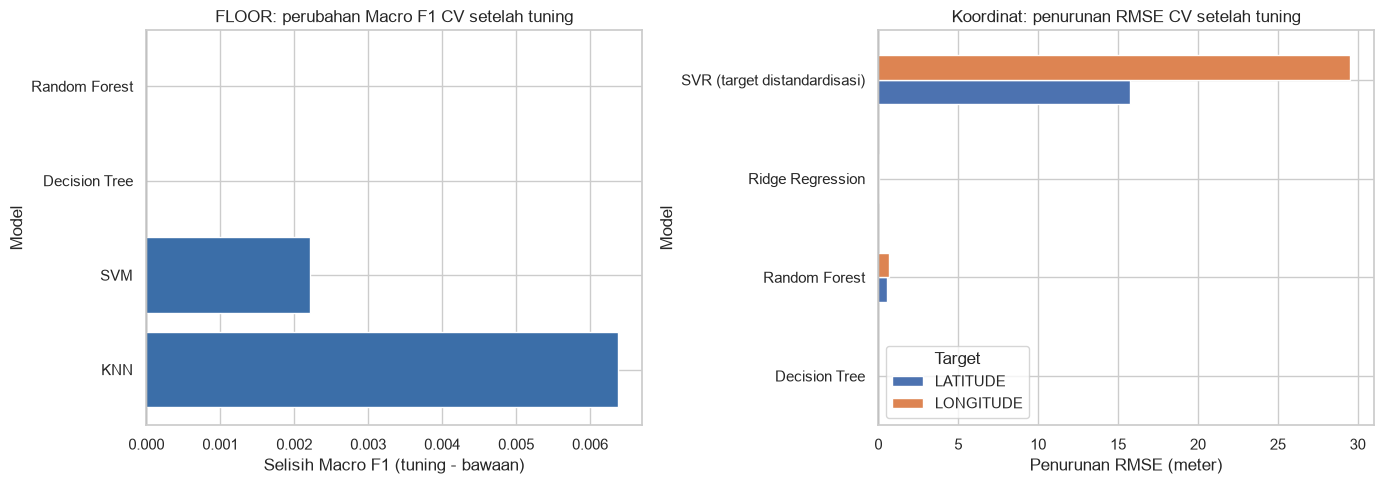

In [68]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score

def galat_posisi(y_asli, y_pred):
    return np.sqrt(((np.asarray(y_asli) - np.asarray(y_pred)) ** 2).sum(axis=1))

def model_dasar_terbaik(target, tabel_dasar):
    nama = tabel_dasar.iloc[0]["Model"]
    kamus = classification_models_floor if target == "FLOOR" else regression_models
    return nama, clone(kamus[nama])

baris_uji, pred_uji = [], {}
for nama_skenario, d in SKENARIO_TUNING.items():
    for target in ["FLOOR", "LONGITUDE", "LATITUDE"]:
        nama_tuning, pipa_tuning = model_tuning_terbaik[(target, nama_skenario)]
        nama_dasar, model_dasar = model_dasar_terbaik(target, d["dasar"][target])
        pipa_dasar = create_supervised_pipeline(model_dasar).fit(d["X_train"], d["y_train"][target])
        pred_uji[(target, nama_skenario, "bawaan")] = pipa_dasar.predict(d["X_test"])
        pred_uji[(target, nama_skenario, "tuning")] = pipa_tuning.predict(d["X_test"])
        for varian, nama, pred in [("bawaan", nama_dasar, pred_uji[(target, nama_skenario, "bawaan")]),
                                   ("tuning", nama_tuning, pred_uji[(target, nama_skenario, "tuning")])]:
            y = d["y_test"][target]
            if target == "FLOOR":
                baris_uji.append({"Skenario": nama_skenario, "Target": target, "Varian": varian, "Model": nama,
                                  "Accuracy": accuracy_score(y, pred), "Macro F1": f1_score(y, pred, average="macro"),
                                  "MAE (m)": np.nan, "RMSE (m)": np.nan, "R2": np.nan})
            else:
                baris_uji.append({"Skenario": nama_skenario, "Target": target, "Varian": varian, "Model": nama,
                                  "Accuracy": np.nan, "Macro F1": np.nan,
                                  "MAE (m)": mean_absolute_error(y, pred),
                                  "RMSE (m)": np.sqrt(mean_squared_error(y, pred)), "R2": r2_score(y, pred)})

uji_tuning = pd.DataFrame(baris_uji)
print("=== PERBANDINGAN DATA TESTING: MODEL BAWAAN VS MODEL TUNING ===")
display(uji_tuning)

# galat posisi gabungan (jarak Euclid dalam meter) dari prediksi LONGITUDE dan LATITUDE
baris_pos = []
for nama_skenario, d in SKENARIO_TUNING.items():
    Y = d["y_test"][["LONGITUDE", "LATITUDE"]].to_numpy()
    for varian in ["bawaan", "tuning"]:
        P = np.c_[pred_uji[("LONGITUDE", nama_skenario, varian)], pred_uji[("LATITUDE", nama_skenario, varian)]]
        g = galat_posisi(Y, P)
        baris_pos.append({"Skenario": nama_skenario, "Varian": varian,
                          "Galat posisi rata-rata (m)": g.mean(), "Galat posisi median (m)": np.median(g),
                          "Galat posisi P90 (m)": np.percentile(g, 90)})
posisi_tuning = pd.DataFrame(baris_pos)
print("\n=== GALAT POSISI GABUNGAN (DATA TESTING) ===")
display(posisi_tuning)

# visualisasi perbaikan skor CV akibat tuning
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
t = tabel_tuning[tabel_tuning["Skenario"] == list(SKENARIO_TUNING)[0]]
f = t[t["Target"] == "FLOOR"]
ax[0].barh(f["Model"], f["Perbaikan"], color="#3b6ea8")
ax[0].axvline(0, color="gray", lw=1)
ax[0].set_title("FLOOR: perubahan Macro F1 CV setelah tuning")
ax[0].set_xlabel("Selisih Macro F1 (tuning - bawaan)"); ax[0].set_ylabel("Model")
r = t[t["Target"].isin(["LONGITUDE", "LATITUDE"])]
r_piv = r.pivot(index="Model", columns="Target", values="Perbaikan")
r_piv.plot.barh(ax=ax[1])
ax[1].axvline(0, color="gray", lw=1)
ax[1].set_title("Koordinat: penurunan RMSE CV setelah tuning")
ax[1].set_xlabel("Penurunan RMSE (meter)"); ax[1].set_ylabel("Model")
plt.tight_layout()
plt.show()

**Analisis Hasil Tuning**

FLOOR. Pada skenario 80:20, tuning menaikkan Macro F1 CV KNN dari 0,9810 menjadi 0,9874 (n_neighbors = 1) dan SVM dari 0,9900 menjadi 0,9923 (C = 10). Pada Random Forest kenaikannya hanya 0,0002 (0,9966 menjadi 0,9968 dengan max_features = 0,1), jauh di bawah simpangan baku CV sekitar 0,0014, sehingga tidak bermakna. Decision Tree tidak berubah (0,9664). Pola yang sama terlihat pada 70:30. Pada data testing, Macro F1 Random Forest malah sedikit turun setelah tuning, dari 0,9965 menjadi 0,9963 (80:20) dan dari 0,9967 menjadi 0,9964 (70:30). Oleh karena itu pengaturan bawaan Random Forest dipertahankan untuk FLOOR.

LONGITUDE dan LATITUDE. Pada skenario 80:20, RMSE CV Random Forest turun dari 8,33 m menjadi 7,66 m (LONGITUDE) dan dari 5,71 m menjadi 5,16 m (LATITUDE) dengan max_features = 0,3. Pada 70:30 penurunannya dari 8,37 m menjadi 7,70 m dan dari 5,90 m menjadi 5,24 m. Ridge Regression dan Decision Tree hampir tidak berubah. SVR turun tajam setelah target distandardisasi, dari 49,40 m menjadi 19,85 m (LONGITUDE) dan dari 27,86 m menjadi 12,14 m (LATITUDE), tetapi tetap jauh di atas Random Forest. Hal ini menunjukkan bahwa kelemahan SVR pada Bagian 52 dan 53 sebagian besar berasal dari skala target dan bukan dari algoritmanya.

Data testing. Galat posisi rata-rata turun dari 4,03 m menjadi 3,62 m pada 80:20 (median 2,05 m menjadi 1,97 m, persentil ke-90 8,39 m menjadi 7,41 m) dan dari 4,24 m menjadi 3,86 m pada 70:30. Perbaikan sekitar 9 sampai 10 persen ini konsisten pada kedua skenario.
Keterbatasan. Grid dibuat kecil. Nilai max_features terbaik pada regresi (0,3) berada di batas bawah grid yang diuji (0,3, 0,6, 1,0), sehingga nilai yang lebih kecil belum diuji. Gradient Boosting dan BUILDINGID tidak dituning.

## 64. Kesimpulan Process 3

Berdasarkan hasil eksperimen supervised learning, performa model berbeda menurut target dan skenario pembagian data. Oleh karena itu, pemilihan model dilakukan secara terpisah untuk setiap target berdasarkan hasil 5-fold cross-validation.

Pada tugas klasifikasi, Logistic Regression memperoleh Macro F1 tertinggi untuk BUILDINGID pada skenario 80:20 sebesar 0,998374, sedangkan Random Forest memperoleh hasil tertinggi pada skenario 70:30 sebesar 0,998513. Selisih Macro F1 antara Logistic Regression dan Random Forest pada skenario 80:20 relatif kecil dibandingkan simpangan baku cross-validation. Pada target FLOOR, Random Forest memperoleh Macro F1 tertinggi pada skenario 80:20 sebesar 0,996612 dan 70:30 sebesar 0,995790.

Pada tugas regresi, Random Forest menghasilkan RMSE cross-validation terendah dibandingkan Linear Regression, Ridge Regression, Polynomial Regression, SVR, Decision Tree, dan Gradient Boosting. Model Random Forest kemudian ditingkatkan melalui hyperparameter tuning menggunakan GridSearchCV. Untuk LONGITUDE, RMSE cross-validation turun dari 8,3318 m menjadi sekitar 7,66 m pada skenario 80:20 dan dari 8,3705 m menjadi sekitar 7,70 m pada skenario 70:30. Untuk LATITUDE, RMSE turun dari 5,7088 m menjadi sekitar 5,16 m pada skenario 80:20 dan dari 5,8967 m menjadi sekitar 5,24 m pada skenario 70:30. Konfigurasi terbaik menggunakan max_features=0.3.

Pada target FLOOR, hyperparameter tuning Random Forest tidak menghasilkan peningkatan performa yang berarti. Bahkan, Macro F1 pada data testing sedikit menurun dibandingkan konfigurasi bawaan. Oleh karena itu, Random Forest bawaan tetap dipertahankan untuk FLOOR, sedangkan Random Forest hasil tuning digunakan untuk LONGITUDE dan LATITUDE pada evaluasi akhir skenario 80:20.

Hasil perbandingan model juga menunjukkan bahwa Decision Tree memiliki indikasi overfitting, yaitu performa training yang jauh lebih baik dibandingkan performa validasi. Sebaliknya, Linear Regression, Ridge Regression, dan SVR menunjukkan kesalahan prediksi koordinat yang relatif lebih tinggi dibandingkan Random Forest. Gradient Boosting dengan konfigurasi awal yang diuji juga belum mampu menyamai performa Random Forest pada sebagian besar target.

Dengan demikian, model akhir dipilih secara spesifik untuk setiap target. Logistic Regression digunakan untuk BUILDINGID pada skenario evaluasi akhir 80:20, Random Forest bawaan digunakan untuk FLOOR, sedangkan Random Forest hasil hyperparameter tuning dengan max_features=0.3 digunakan untuk LONGITUDE dan LATITUDE. Pemilihan ini mempertimbangkan hasil cross-validation, pengujian testing, dan peningkatan performa setelah tuning.

## 65. Perbandingan Konfigurasi Preprocessing

Eksperimen ini membandingkan pengaruh dua metode penanganan nilai RSSI yang tidak terdeteksi, yaitu Sentinel Replacement dan Median Imputation, serta dua skenario seleksi fitur, yaitu Full Features dan Reduced Features.

StandardScaler digunakan secara konsisten pada seluruh konfigurasi agar pengaruh metode penanganan sentinel dan seleksi fitur dapat diamati secara terpisah.

Evaluasi menggunakan Random Forest dengan parameter yang sama seperti eksperimen utama. Pengujian dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Seluruh proses preprocessing tetap dilakukan di dalam Pipeline untuk mencegah data leakage.

In [69]:
# Membuat pipeline khusus untuk perbandingan preprocessing

def create_comparison_pipeline(
    model,
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
):
    preprocessing = build_preprocessing_pipeline(
        method=method,
        feature_mode=feature_mode,
        scaler=scaler
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", model)
    ])


# Empat konfigurasi preprocessing
preprocessing_configs = [
    {
        "Configuration": "Sentinel - Full",
        "method": "sentinel",
        "feature_mode": "full",
        "scaler": "standard"
    },
    {
        "Configuration": "Sentinel - Reduced",
        "method": "sentinel",
        "feature_mode": "reduced",
        "scaler": "standard"
    },
    {
        "Configuration": "Median - Full",
        "method": "median",
        "feature_mode": "full",
        "scaler": "standard"
    },
    {
        "Configuration": "Median - Reduced",
        "method": "median",
        "feature_mode": "reduced",
        "scaler": "standard"
    }
]

# Memastikan konfigurasi berhasil dibuat
comparison_pipeline_test = create_comparison_pipeline(
    RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    method="median",
    feature_mode="reduced",
    scaler="standard"
)

print("Jumlah konfigurasi preprocessing:",
      len(preprocessing_configs))

print("\nDaftar konfigurasi:")
display(pd.DataFrame(preprocessing_configs))

print("\nPipeline perbandingan berhasil dibuat.")

Jumlah konfigurasi preprocessing: 4

Daftar konfigurasi:


,Configuration,method,feature_mode,scaler
0,Sentinel - Full,sentinel,full,standard
1,Sentinel - Reduced,sentinel,reduced,standard
2,Median - Full,median,full,standard
3,Median - Reduced,median,reduced,standard



Pipeline perbandingan berhasil dibuat.


## 66. Perbandingan Preprocessing pada Model Regresi

Eksperimen ini bertujuan membandingkan pengaruh metode penanganan nilai sentinel dan seleksi fitur terhadap performa model regresi.

Random Forest digunakan sebagai model pembanding dengan parameter yang sama pada setiap konfigurasi preprocessing.

Evaluasi dilakukan terhadap target LONGITUDE dan LATITUDE pada skenario 80:20 dan 70:30 menggunakan 5-fold KFold Cross-Validation.

Metrik evaluasi meliputi MAE, RMSE, dan R². Seluruh preprocessing dilakukan di dalam Pipeline untuk menghindari data leakage.

In [70]:
def compare_regression_preprocessing(X, y, cv):
    results = []

    for config in preprocessing_configs:
        model = RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method=config["method"],
            feature_mode=config["feature_mode"],
            scaler=config["scaler"]
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Configuration": config["Configuration"],
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std()
        })

    return pd.DataFrame(results).sort_values(
        "RMSE Mean",
        ascending=True
    ).reset_index(drop=True)


# LONGITUDE 80:20
print("=== PREPROCESSING LONGITUDE 80:20 ===")
prep_longitude_80 = compare_regression_preprocessing(
    X_train_80, y_longitude_80, cv_regression
)
display(prep_longitude_80)

# LATITUDE 80:20
print("=== PREPROCESSING LATITUDE 80:20 ===")
prep_latitude_80 = compare_regression_preprocessing(
    X_train_80, y_latitude_80, cv_regression
)
display(prep_latitude_80)

# LONGITUDE 70:30
print("=== PREPROCESSING LONGITUDE 70:30 ===")
prep_longitude_70 = compare_regression_preprocessing(
    X_train_70, y_longitude_70, cv_regression
)
display(prep_longitude_70)

# LATITUDE 70:30
print("=== PREPROCESSING LATITUDE 70:30 ===")
prep_latitude_70 = compare_regression_preprocessing(
    X_train_70, y_latitude_70, cv_regression
)
display(prep_latitude_70)

=== PREPROCESSING LONGITUDE 80:20 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Full,3.086336,0.095680,8.328717,0.678726,0.995472,0.000763
1,Sentinel - Reduced,3.086458,0.097516,8.341325,0.674437,0.995459,0.000760
2,Median - Reduced,4.111784,0.036895,10.015050,0.468760,0.993489,0.000581
3,Median - Full,4.110865,0.034572,10.015928,0.473090,0.993487,0.000589


=== PREPROCESSING LATITUDE 80:20 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Reduced,2.449973,0.100758,5.702763,0.613961,0.992787,0.001530
1,Sentinel - Full,2.452398,0.098834,5.703602,0.608438,0.992787,0.001517
2,Median - Reduced,3.059921,0.120532,6.610556,0.627767,0.990333,0.001845
3,Median - Full,3.056643,0.124999,6.613255,0.628861,0.990325,0.001850


=== PREPROCESSING LONGITUDE 70:30 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Full,3.282527,0.146262,8.351073,0.665782,0.995467,0.000646
1,Sentinel - Reduced,3.289249,0.139315,8.376538,0.653425,0.995440,0.000632
2,Median - Reduced,4.359276,0.138818,10.281001,0.715278,0.993136,0.000841
3,Median - Full,4.368866,0.139473,10.308027,0.693593,0.993102,0.000816


=== PREPROCESSING LATITUDE 70:30 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Reduced,2.602402,0.119031,5.889187,0.423506,0.992369,0.001085
1,Sentinel - Full,2.604703,0.116842,5.894894,0.417044,0.992356,0.001068
2,Median - Reduced,3.276387,0.148764,6.901202,0.581210,0.989501,0.001770
3,Median - Full,3.274006,0.143024,6.903123,0.557690,0.989501,0.001687


## 67. Perbandingan Preprocessing pada Model Klasifikasi

Eksperimen ini bertujuan membandingkan pengaruh metode penanganan nilai sentinel dan seleksi fitur terhadap performa model klasifikasi.

Random Forest Classifier digunakan sebagai model pembanding dengan parameter yang sama pada setiap konfigurasi preprocessing.

Evaluasi dilakukan terhadap target BUILDINGID dan FLOOR pada skenario 80:20 dan 70:30 menggunakan 5-fold Stratified Cross-Validation.

Metrik evaluasi meliputi Accuracy dan Macro F1-score. Seluruh proses preprocessing dilakukan di dalam Pipeline untuk mencegah data leakage.

In [71]:
def compare_classification_preprocessing(
    X, y, cv, target_name
):
    results = []

    for config in preprocessing_configs:

        # BUILDINGID tanpa class weighting
        # FLOOR menggunakan balanced
        class_weight = (
            "balanced" if target_name == "FLOOR" else None
        )

        model = RandomForestClassifier(
            n_estimators=200,
            class_weight=class_weight,
            random_state=42,
            n_jobs=1
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method=config["method"],
            feature_mode=config["feature_mode"],
            scaler=config["scaler"]
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Configuration": config["Configuration"],
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "Macro F1 Mean": scores["test_f1_macro"].mean(),
            "Macro F1 Std": scores["test_f1_macro"].std()
        })

    return pd.DataFrame(results).sort_values(
        "Macro F1 Mean",
        ascending=False
    ).reset_index(drop=True)


# BUILDINGID 80:20
print("=== BUILDINGID 80:20 ===")
prep_building_80 = compare_classification_preprocessing(
    X_train_80, y_building_80,
    cv_classification, "BUILDINGID"
)
display(prep_building_80)


# FLOOR 80:20
print("=== FLOOR 80:20 ===")
prep_floor_80 = compare_classification_preprocessing(
    X_train_80, y_floor_80,
    cv_classification, "FLOOR"
)
display(prep_floor_80)


# BUILDINGID 70:30
print("=== BUILDINGID 70:30 ===")
prep_building_70 = compare_classification_preprocessing(
    X_train_70, y_building_70,
    cv_classification, "BUILDINGID"
)
display(prep_building_70)


# FLOOR 70:30
print("=== FLOOR 70:30 ===")
prep_floor_70 = compare_classification_preprocessing(
    X_train_70, y_floor_70,
    cv_classification, "FLOOR"
)
display(prep_floor_70)

=== BUILDINGID 80:20 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.998381,0.000679,0.998374,0.000686
1,Sentinel - Reduced,0.998316,0.000660,0.998292,0.000665
2,Median - Full,0.998057,0.000738,0.998034,0.000754
3,Median - Reduced,0.997863,0.000698,0.997839,0.000716


=== FLOOR 80:20 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.996956,0.001337,0.997027,0.001563
1,Sentinel - Reduced,0.996891,0.001305,0.996972,0.001499
2,Median - Full,0.994689,0.001457,0.995280,0.001599
3,Median - Reduced,0.994365,0.001457,0.995012,0.001603


=== BUILDINGID 70:30 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.998520,0.001303,0.998513,0.001308
1,Sentinel - Reduced,0.998520,0.001303,0.998513,0.001308
2,Median - Reduced,0.998298,0.001273,0.998273,0.001286
3,Median - Full,0.998298,0.001316,0.998270,0.001335


=== FLOOR 70:30 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.996373,0.001412,0.996637,0.001161
1,Sentinel - Reduced,0.996373,0.001312,0.996475,0.001078
2,Median - Full,0.994226,0.002008,0.995013,0.001487
3,Median - Reduced,0.994078,0.001916,0.994886,0.001430


## 68. Kesimpulan Perbandingan Preprocessing

Berdasarkan hasil eksperimen, Sentinel Replacement menghasilkan performa yang lebih baik dibandingkan Median Imputation pada seluruh target klasifikasi dan regresi serta pada kedua skenario pembagian data, yaitu 80:20 dan 70:30. Hasil ini menunjukkan bahwa penggantian nilai RSSI yang tidak terdeteksi dengan nilai sentinel -105 dBm lebih sesuai dibandingkan pengubahan nilai sentinel menjadi NaN yang dilanjutkan dengan median imputation pada konfigurasi eksperimen yang diuji.

Pada target BUILDINGID, konfigurasi Sentinel - Full menghasilkan Macro F1 sebesar 0,998374 pada skenario 80:20, sedikit lebih tinggi dibandingkan Sentinel - Reduced sebesar 0,998292. Pada skenario 70:30, kedua konfigurasi menghasilkan Macro F1 yang sama, yaitu 0,998513. Hal ini menunjukkan bahwa pengurangan fitur tidak memberikan perubahan performa yang berarti pada target BUILDINGID.

Pada target FLOOR, Sentinel - Full menghasilkan Macro F1 sebesar 0,997028 pada skenario 80:20 dan 0,996018 pada skenario 70:30. Hasil tersebut sedikit lebih tinggi dibandingkan Sentinel - Reduced, yang masing-masing menghasilkan Macro F1 sebesar 0,996612 dan 0,995790. Dengan demikian, penggunaan seluruh fitur memberikan hasil klasifikasi sedikit lebih baik pada target FLOOR dalam eksperimen ini.

Pada tugas regresi, konfigurasi terbaik antara Full dan Reduced bergantung pada target dan skenario pembagian data. Pada skenario 80:20, Sentinel - Reduced menghasilkan RMSE terendah untuk LONGITUDE sebesar 8,331839 m, sedangkan Sentinel - Full menghasilkan RMSE terendah untuk LATITUDE sebesar 5,701153 m. Pada skenario 70:30, Sentinel - Reduced menghasilkan RMSE terendah untuk LONGITUDE sebesar 8,370511 m dan LATITUDE sebesar 5,896744 m. Meskipun demikian, perbedaan RMSE antara konfigurasi Full dan Reduced relatif kecil, yaitu kurang dari 0,01 m pada seluruh target dan skenario pengujian.

Secara keseluruhan, hasil eksperimen menunjukkan bahwa metode penanganan nilai sentinel memiliki pengaruh lebih konsisten terhadap performa model dibandingkan seleksi fitur. Sentinel Replacement memberikan hasil lebih baik dibandingkan Median Imputation, sedangkan pengaruh penggunaan Full atau Reduced Features bergantung pada target dan skenario pembagian data. Oleh karena itu, Sentinel Replacement dipilih sebagai metode penanganan RSSI yang digunakan dalam eksperimen selanjutnya. Reduced Features tetap dapat dipertahankan untuk mengurangi dimensi masukan model, dengan mempertimbangkan bahwa pengurangan fitur tidak selalu meningkatkan performa prediksi.

## 69. Perbandingan StandardScaler dan MinMaxScaler

Eksperimen ini bertujuan mengevaluasi pengaruh metode scaling terhadap performa model klasifikasi dan regresi.

StandardScaler dan MinMaxScaler dibandingkan dengan mempertahankan metode Sentinel Replacement dan Reduced Features pada seluruh konfigurasi.

Logistic Regression digunakan untuk klasifikasi, sedangkan Ridge Regression digunakan untuk regresi. Kedua model dipilih karena performanya dapat dipengaruhi oleh skala fitur.

Evaluasi dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Metrik klasifikasi meliputi Accuracy dan Macro F1-score. Metrik regresi meliputi MAE, RMSE, dan R². Seluruh proses scaling dilakukan di dalam Pipeline untuk mencegah data leakage.

In [72]:
def compare_classification_scalers(X, y, cv, target_name):
    results = []

    for scaler_name in ["standard", "minmax"]:

        class_weight = (
            "balanced" if target_name == "FLOOR" else None
        )

        model = LogisticRegression(
            max_iter=2000,
            class_weight=class_weight,
            random_state=42
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method="sentinel",
            feature_mode="reduced",
            scaler=scaler_name
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1
        )

        results.append({
            "Scaler": scaler_name,
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "Macro F1 Mean": scores["test_f1_macro"].mean(),
            "Macro F1 Std": scores["test_f1_macro"].std()
        })

    return pd.DataFrame(results)


def compare_regression_scalers(X, y, cv):
    results = []

    for scaler_name in ["standard", "minmax"]:

        model = Ridge(alpha=1.0)

        pipeline = create_comparison_pipeline(
            model=model,
            method="sentinel",
            feature_mode="reduced",
            scaler=scaler_name
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1
        )

        results.append({
            "Scaler": scaler_name,
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std()
        })

    return pd.DataFrame(results)

## 70. Evaluasi Perbandingan StandardScaler dan MinMaxScaler

Eksperimen ini dilakukan untuk membandingkan pengaruh penggunaan StandardScaler dan MinMaxScaler terhadap performa model klasifikasi dan regresi.

Pada eksperimen klasifikasi, Logistic Regression digunakan untuk memprediksi BUILDINGID dan FLOOR. Sementara itu, Ridge Regression digunakan untuk memprediksi LONGITUDE dan LATITUDE.

Metode Sentinel Replacement dan Reduced Features dipertahankan pada seluruh konfigurasi agar pengaruh metode scaling dapat diamati secara terpisah.

Evaluasi dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Metrik evaluasi klasifikasi meliputi Accuracy dan Macro F1-score. Metrik evaluasi regresi meliputi MAE, RMSE, dan R-squared (R²).

Seluruh proses scaling dilakukan di dalam Pipeline untuk mencegah data leakage. Data testing tidak digunakan dalam eksperimen ini.

In [73]:
# KLASIFIKASI BUILDINGID
print("=== BUILDINGID 80:20 ===")
scaler_building_80 = compare_classification_scalers(
    X_train_80,
    y_building_80,
    cv_classification,
    "BUILDINGID"
)
display(scaler_building_80)


print("=== BUILDINGID 70:30 ===")
scaler_building_70 = compare_classification_scalers(
    X_train_70,
    y_building_70,
    cv_classification,
    "BUILDINGID"
)
display(scaler_building_70)


# KLASIFIKASI FLOOR
print("=== FLOOR 80:20 ===")
scaler_floor_80 = compare_classification_scalers(
    X_train_80,
    y_floor_80,
    cv_classification,
    "FLOOR"
)
display(scaler_floor_80)


print("=== FLOOR 70:30 ===")
scaler_floor_70 = compare_classification_scalers(
    X_train_70,
    y_floor_70,
    cv_classification,
    "FLOOR"
)
display(scaler_floor_70)



# REGRESI LONGITUDE
print("=== LONGITUDE 80:20 ===")
scaler_longitude_80 = compare_regression_scalers(
    X_train_80,
    y_longitude_80,
    cv_regression
)
display(scaler_longitude_80)


print("=== LONGITUDE 70:30 ===")
scaler_longitude_70 = compare_regression_scalers(
    X_train_70,
    y_longitude_70,
    cv_regression
)
display(scaler_longitude_70)


# REGRESI LATITUDE
print("=== LATITUDE 80:20 ===")
scaler_latitude_80 = compare_regression_scalers(
    X_train_80,
    y_latitude_80,
    cv_regression
)
display(scaler_latitude_80)


print("=== LATITUDE 70:30 ===")
scaler_latitude_70 = compare_regression_scalers(
    X_train_70,
    y_latitude_70,
    cv_regression
)
display(scaler_latitude_70)

=== BUILDINGID 80:20 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.998381,0.000679,0.998374,0.000686
1,minmax,0.998381,0.000679,0.998374,0.000686


=== BUILDINGID 70:30 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.998446,0.001431,0.998438,0.001437
1,minmax,0.998446,0.001431,0.998438,0.001437


=== FLOOR 80:20 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.991839,0.001915,0.991895,0.002007
1,minmax,0.988860,0.002240,0.987857,0.001880


... (6 outputs left out)

=== LATITUDE 80:20 ===


,Scaler,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,standard,13.083572,0.159465,17.642853,0.359124,0.931649,0.003138
1,minmax,13.031960,0.160408,17.582735,0.357932,0.932115,0.003107


=== LATITUDE 70:30 ===


,Scaler,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,standard,13.161073,0.180569,17.741191,0.300158,0.931068,0.001927
1,minmax,13.096302,0.191877,17.662736,0.314596,0.931675,0.002050


## 71. Kesimpulan Perbandingan StandardScaler dan MinMaxScaler

Berdasarkan hasil eksperimen, pengaruh metode scaling berbeda pada setiap model dan target prediksi.

Pada klasifikasi BUILDINGID, StandardScaler dan MinMaxScaler menghasilkan performa yang hampir identik. Pada klasifikasi FLOOR, StandardScaler menghasilkan Accuracy dan Macro F1-score yang lebih tinggi pada kedua skenario pembagian data.

Pada regresi menggunakan Ridge Regression, MinMaxScaler menghasilkan MAE dan RMSE yang sedikit lebih rendah serta R² yang sedikit lebih tinggi dibandingkan StandardScaler untuk target LONGITUDE dan LATITUDE.

Hasil ini menunjukkan bahwa pemilihan scaler perlu mempertimbangkan karakteristik algoritma dan target prediksi. Tidak terdapat satu metode scaling yang selalu menghasilkan performa terbaik untuk seluruh eksperimen.

## PROSES 4: MULTILAYER PERCEPTRON (MLP) / ARTIFICIAL NEURAL NETWORK (ANN)

Tahap ini bertujuan membangun dan mengevaluasi model Artificial Neural Network menggunakan arsitektur Multilayer Perceptron (MLP).

Eksperimen dilakukan pada empat target secara terpisah, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Penelitian membandingkan tiga arsitektur berdasarkan jumlah hidden layer, dua nilai learning rate, serta mencatat optimizer yang digunakan.

Proses pelatihan menggunakan Early Stopping dan Dropout untuk membantu mengendalikan overfitting. Performa model diamati melalui kurva training loss dan validation loss.

Model MLP terbaik selanjutnya dibandingkan dengan Random Forest sebagai model terbaik dari tahap supervised learning sebelumnya.

### 72. Import Library dan Konfigurasi MLP

Library yang digunakan mencakup TensorFlow/Keras untuk membangun jaringan saraf, serta Scikit-learn untuk preprocessing dan evaluasi model.

Seluruh eksperimen menggunakan random_state sebesar 42 agar hasil dapat direproduksi.

In [74]:
# Import library MLP / ANN

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Konfigurasi random state
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("Random state:", RANDOM_STATE)
print("Library MLP/ANN berhasil diimpor.")

TensorFlow version: 2.21.0
Random state: 42
Library MLP/ANN berhasil diimpor.


### 73. Persiapan Data Training dan Validation

Data training dibagi kembali menjadi data training dan validation dengan proporsi 80:20.

Pembagian ini digunakan untuk memantau validation loss selama pelatihan MLP dan menerapkan Early Stopping.

Preprocessing dilakukan menggunakan Pipeline yang sama dengan konfigurasi utama Process 3. Pipeline di-fit hanya pada data training agar tidak terjadi data leakage.

In [75]:
# Membuat stratifikasi berdasarkan kombinasi BUILDINGID dan FLOOR

stratify_80 = (
    y_train_80["BUILDINGID"].astype(str)
    + "_"
    + y_train_80["FLOOR"].astype(str)
)

stratify_70 = (
    y_train_70["BUILDINGID"].astype(str)
    + "_"
    + y_train_70["FLOOR"].astype(str)
)


# Pembagian data training dan validation 80:20
X_mlp_train_80, X_mlp_val_80, y_mlp_train_80, y_mlp_val_80 = train_test_split(
    X_train_80,
    y_train_80,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_80
)


# Pembagian data training dan validation 70:30
X_mlp_train_70, X_mlp_val_70, y_mlp_train_70, y_mlp_val_70 = train_test_split(
    X_train_70,
    y_train_70,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_70
)


print("=== DATA MLP 80:20 ===")
print("Training:", X_mlp_train_80.shape)
print("Validation:", X_mlp_val_80.shape)

print("\n=== DATA MLP 70:30 ===")
print("Training:", X_mlp_train_70.shape)
print("Validation:", X_mlp_val_70.shape)

print("\nPembagian data MLP berhasil menggunakan stratifikasi.")

=== DATA MLP 80:20 ===
Training: (12352, 520)
Validation: (3088, 520)

=== DATA MLP 70:30 ===
Training: (10808, 520)
Validation: (2702, 520)

Pembagian data MLP berhasil menggunakan stratifikasi.


### 74. Preprocessing Data MLP

Preprocessing dilakukan menggunakan Pipeline dengan konfigurasi Sentinel Replacement, Reduced Features, dan StandardScaler.

Pipeline di-fit hanya menggunakan data training. Data validation hanya menjalani transformasi menggunakan parameter preprocessing dari data training.

Untuk target regresi, StandardScaler juga diterapkan pada variabel target agar proses pelatihan jaringan saraf lebih stabil. Scaler target hanya di-fit menggunakan data training dan hasil prediksi akan dikembalikan ke skala aslinya saat evaluasi.

Proses ini dilakukan secara terpisah pada skenario 80:20 dan 70:30 untuk mencegah data leakage.

In [76]:
# PREPROCESSING DATA MLP 80:20

# Pipeline fitur
mlp_preprocessor_80 = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
)

X_mlp_train_processed_80 = mlp_preprocessor_80.fit_transform(
    X_mlp_train_80
)

X_mlp_val_processed_80 = mlp_preprocessor_80.transform(
    X_mlp_val_80
)


# PREPROCESSING DATA MLP 70:30
mlp_preprocessor_70 = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
)

X_mlp_train_processed_70 = mlp_preprocessor_70.fit_transform(
    X_mlp_train_70
)

X_mlp_val_processed_70 = mlp_preprocessor_70.transform(
    X_mlp_val_70
)


# SCALING TARGET REGRESI
from sklearn.preprocessing import StandardScaler

regression_targets = ["LONGITUDE", "LATITUDE"]

y_reg_scalers_80 = {}
y_reg_scalers_70 = {}

for target in regression_targets:

    # Skenario 80:20
    scaler_80 = StandardScaler()
    scaler_80.fit(
        y_mlp_train_80[[target]]
    )
    y_reg_scalers_80[target] = scaler_80

    # Skenario 70:30
    scaler_70 = StandardScaler()
    scaler_70.fit(
        y_mlp_train_70[[target]]
    )
    y_reg_scalers_70[target] = scaler_70


# VALIDASI HASIL PREPROCESSING
print("=== PREPROCESSING MLP 80:20 ===")
print("Training:", X_mlp_train_processed_80.shape)
print("Validation:", X_mlp_val_processed_80.shape)

print("\n=== PREPROCESSING MLP 70:30 ===")
print("Training:", X_mlp_train_processed_70.shape)
print("Validation:", X_mlp_val_processed_70.shape)

print("\nJumlah fitur setelah reduksi 80:20:",
      X_mlp_train_processed_80.shape[1])

print("Jumlah fitur setelah reduksi 70:30:",
      X_mlp_train_processed_70.shape[1])

assert np.isfinite(X_mlp_train_processed_80).all()
assert np.isfinite(X_mlp_val_processed_80).all()
assert np.isfinite(X_mlp_train_processed_70).all()
assert np.isfinite(X_mlp_val_processed_70).all()

print("\nSeluruh data preprocessing MLP valid.")

=== PREPROCESSING MLP 80:20 ===
Training: (12352, 457)
Validation: (3088, 457)

=== PREPROCESSING MLP 70:30 ===
Training: (10808, 454)
Validation: (2702, 454)

Jumlah fitur setelah reduksi 80:20: 457
Jumlah fitur setelah reduksi 70:30: 454

Seluruh data preprocessing MLP valid.


### 75. Konfigurasi Arsitektur MLP

Penelitian menggunakan tiga arsitektur MLP dengan jumlah hidden layer yang berbeda, yaitu satu, dua, dan tiga hidden layer.

Jumlah neuron pada setiap arsitektur ditetapkan sebagai berikut:

1. Arsitektur 1: 64 neuron.
2. Arsitektur 2: 64 dan 32 neuron.
3. Arsitektur 3: 64, 32, dan 16 neuron.

Setiap hidden layer menggunakan fungsi aktivasi ReLU dan Dropout sebesar 0.2 untuk membantu mengurangi overfitting.

Optimizer yang digunakan adalah Adam dengan dua variasi learning rate, yaitu 0.001 dan 0.01.

Untuk klasifikasi, output layer menggunakan Softmax dan Sparse Categorical Crossentropy. Untuk regresi, output layer menggunakan satu neuron dengan aktivasi linear dan Mean Squared Error.

In [77]:
# Konfigurasi arsitektur MLP
mlp_architectures = {
    "MLP_1_Hidden": [64],
    "MLP_2_Hidden": [64, 32],
    "MLP_3_Hidden": [64, 32, 16]
}

# Variasi learning rate
mlp_learning_rates = [0.001, 0.01]

# Optimizer
mlp_optimizer_name = "Adam"

# Dropout
mlp_dropout_rate = 0.2

# Early stopping
mlp_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Fungsi pembentukan model
def build_mlp_model(
    task,
    input_dim,
    hidden_layers,
    learning_rate,
    output_units=1
):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation="relu"))
        model.add(Dropout(mlp_dropout_rate))

    if task == "classification":
        model.add(Dense(output_units, activation="softmax"))
        loss_function = "sparse_categorical_crossentropy"
        metrics_list = ["accuracy"]

    elif task == "regression":
        model.add(Dense(1, activation="linear"))
        loss_function = "mse"
        metrics_list = ["mae"]

    else:
        raise ValueError("Task harus classification atau regression.")

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss=loss_function,
        metrics=metrics_list
    )

    return model


# Menampilkan konfigurasi
print("=== KONFIGURASI ARSITEKTUR MLP ===")

for name, layers in mlp_architectures.items():
    print(f"{name}: {layers}")

print("\nLearning rates:", mlp_learning_rates)
print("Optimizer:", mlp_optimizer_name)
print("Dropout:", mlp_dropout_rate)
print("Early stopping patience: 10")

=== KONFIGURASI ARSITEKTUR MLP ===
MLP_1_Hidden: [64]
MLP_2_Hidden: [64, 32]
MLP_3_Hidden: [64, 32, 16]

Learning rates: [0.001, 0.01]
Optimizer: Adam
Dropout: 0.2
Early stopping patience: 10


### 76. Pelatihan dan Evaluasi Model MLP

Pelatihan dilakukan terhadap tiga arsitektur MLP dan dua variasi learning rate menggunakan optimizer Adam.

Setiap kombinasi diuji pada target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE secara terpisah.

Data training digunakan untuk memperbarui bobot jaringan, sedangkan data validation digunakan untuk memantau performa model dan menentukan penghentian pelatihan melalui Early Stopping.

Riwayat training loss dan validation loss disimpan untuk menganalisis proses pembelajaran dan indikasi overfitting.

In [78]:
# Fungsi pelatihan MLP untuk klasifikasi
import time

def train_mlp_classification(
    X_train, X_val,
    y_train, y_val,
    target_name
):
    results = []

    for architecture_name, hidden_layers in mlp_architectures.items():

        for learning_rate in mlp_learning_rates:

            print(
                f"Training {target_name} | "
                f"{architecture_name} | LR={learning_rate}"
            )

            model = build_mlp_model(
                task="classification",
                input_dim=X_train.shape[1],
                hidden_layers=hidden_layers,
                learning_rate=learning_rate,
                output_units=len(np.unique(y_train))
            )

            start_train = time.time()
            history = model.fit(
                X_train,
                y_train,
                validation_data=(X_val, y_val),
                epochs=100,
                batch_size=128,
                callbacks=[EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )],
                verbose=0
            )
            train_duration = time.time() - start_train
            param_count = model.count_params()

            val_loss, val_accuracy = model.evaluate(
                X_val, y_val, verbose=0
            )

            results.append({
                "Target": target_name,
                "Architecture": architecture_name,
                "Hidden Layers": str(hidden_layers),
                "Learning Rate": learning_rate,
                "Optimizer": "Adam",
                "Parameters": param_count,
                "Training Time (s)": round(train_duration, 2),
                "Epochs": len(history.history["loss"]),
                "Train Loss": history.history["loss"][-1],
                "Validation Loss": val_loss,
                "Validation Accuracy": val_accuracy,
                "Model": model,
                "History": history
            })

    return results


# Fungsi pelatihan MLP untuk regresi

def train_mlp_regression(
    X_train, X_val,
    y_train, y_val,
    target_name,
    target_scaler
):
    results = []

    y_train_scaled = target_scaler.transform(
        np.asarray(y_train).reshape(-1, 1)
    )

    y_val_scaled = target_scaler.transform(
        np.asarray(y_val).reshape(-1, 1)
    )

    for architecture_name, hidden_layers in mlp_architectures.items():

        for learning_rate in mlp_learning_rates:

            print(
                f"Training {target_name} | "
                f"{architecture_name} | LR={learning_rate}"
            )

            model = build_mlp_model(
                task="regression",
                input_dim=X_train.shape[1],
                hidden_layers=hidden_layers,
                learning_rate=learning_rate
            )

            start_train = time.time()
            history = model.fit(
                X_train,
                y_train_scaled,
                validation_data=(X_val, y_val_scaled),
                epochs=100,
                batch_size=128,
                callbacks=[EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )],
                verbose=0
            )
            train_duration = time.time() - start_train
            param_count = model.count_params()

            val_loss, val_mae = model.evaluate(
                X_val, y_val_scaled, verbose=0
            )

            results.append({
                "Target": target_name,
                "Architecture": architecture_name,
                "Hidden Layers": str(hidden_layers),
                "Learning Rate": learning_rate,
                "Optimizer": "Adam",
                "Parameters": param_count,
                "Training Time (s)": round(train_duration, 2),
                "Epochs": len(history.history["loss"]),
                "Train Loss": history.history["loss"][-1],
                "Validation Loss": val_loss,
                "Validation MAE Scaled": val_mae,
                "Model": model,
                "History": history
            })

    return results


print("Fungsi pelatihan MLP berhasil dibuat (dengan pencatatan parameter & waktu latih).")

Fungsi pelatihan MLP berhasil dibuat (dengan pencatatan parameter & waktu latih).


### 77. Pelatihan MLP pada Skenario 80:20

Pelatihan model MLP pada skenario 80:20 dilakukan terhadap empat target secara terpisah, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Setiap target diuji menggunakan tiga arsitektur dan dua variasi learning rate dengan optimizer Adam.

Data training digunakan untuk melatih model, sedangkan data validation digunakan untuk memantau validation loss dan menerapkan Early Stopping.

Hasil pelatihan dan riwayat loss setiap model disimpan untuk proses evaluasi dan visualisasi.

In [79]:
# PELATIHAN MLP SKENARIO 80:20
mlp_results_80 = {}

# 1. Klasifikasi BUILDINGID
print("\n=== MLP BUILDINGID 80:20 ===")

mlp_results_80["BUILDINGID"] = train_mlp_classification(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["BUILDINGID"].to_numpy(),
    y_mlp_val_80["BUILDINGID"].to_numpy(),
    "BUILDINGID"
)

# 2. Klasifikasi FLOOR
print("\n=== MLP FLOOR 80:20 ===")

mlp_results_80["FLOOR"] = train_mlp_classification(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["FLOOR"].to_numpy(),
    y_mlp_val_80["FLOOR"].to_numpy(),
    "FLOOR"
)

# 3. Regresi LONGITUDE
print("\n=== MLP LONGITUDE 80:20 ===")

mlp_results_80["LONGITUDE"] = train_mlp_regression(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["LONGITUDE"].to_numpy(),
    y_mlp_val_80["LONGITUDE"].to_numpy(),
    "LONGITUDE",
    y_reg_scalers_80["LONGITUDE"]
)

# 4. Regresi LATITUDE
print("\n=== MLP LATITUDE 80:20 ===")

mlp_results_80["LATITUDE"] = train_mlp_regression(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["LATITUDE"].to_numpy(),
    y_mlp_val_80["LATITUDE"].to_numpy(),
    "LATITUDE",
    y_reg_scalers_80["LATITUDE"]
)

print("\nSeluruh pelatihan MLP skenario 80:20 selesai.")

for target, results in mlp_results_80.items():
    print(target, ":", len(results), "model")


=== MLP BUILDINGID 80:20 ===
Training BUILDINGID | MLP_1_Hidden | LR=0.001
Training BUILDINGID | MLP_1_Hidden | LR=0.01
Training BUILDINGID | MLP_2_Hidden | LR=0.001
Training BUILDINGID | MLP_2_Hidden | LR=0.01
Training BUILDINGID | MLP_3_Hidden | LR=0.001
Training BUILDINGID | MLP_3_Hidden | LR=0.01

=== MLP FLOOR 80:20 ===
Training FLOOR | MLP_1_Hidden | LR=0.001
Training FLOOR | MLP_1_Hidden | LR=0.01
Training FLOOR | MLP_2_Hidden | LR=0.001
Training FLOOR | MLP_2_Hidden | LR=0.01
Training FLOOR | MLP_3_Hidden | LR=0.001
Training FLOOR | MLP_3_Hidden | LR=0.01

=== MLP LONGITUDE 80:20 ===
Training LONGITUDE | MLP_1_Hidden | LR=0.001
Training LONGITUDE | MLP_1_Hidden | LR=0.01
Training LONGITUDE | MLP_2_Hidden | LR=0.001
Training LONGITUDE | MLP_2_Hidden | LR=0.01
Training LONGITUDE | MLP_3_Hidden | LR=0.001
Training LONGITUDE | MLP_3_Hidden | LR=0.01

=== MLP LATITUDE 80:20 ===
Training LATITUDE | MLP_1_Hidden | LR=0.001
Training LATITUDE | MLP_1_Hidden | LR=0.01
Training LATITUDE 

### 78. Pelatihan MLP pada Skenario 70:30

Pelatihan MLP pada skenario 70:30 dilakukan menggunakan tiga arsitektur, dua variasi learning rate, dan optimizer Adam.

Eksperimen dilakukan secara terpisah untuk target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Data training digunakan untuk melatih model, sedangkan data validation digunakan untuk memantau performa model dan menerapkan Early Stopping.

Riwayat pelatihan setiap model disimpan untuk evaluasi dan visualisasi kurva loss.

In [80]:
# PELATIHAN MLP SKENARIO 70:30
mlp_results_70 = {}

# 1. Klasifikasi BUILDINGID
print("\n=== MLP BUILDINGID 70:30 ===")

mlp_results_70["BUILDINGID"] = train_mlp_classification(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["BUILDINGID"].to_numpy(),
    y_mlp_val_70["BUILDINGID"].to_numpy(),
    "BUILDINGID"
)

# 2. Klasifikasi FLOOR
print("\n=== MLP FLOOR 70:30 ===")

mlp_results_70["FLOOR"] = train_mlp_classification(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["FLOOR"].to_numpy(),
    y_mlp_val_70["FLOOR"].to_numpy(),
    "FLOOR"
)

# 3. Regresi LONGITUDE
print("\n=== MLP LONGITUDE 70:30 ===")

mlp_results_70["LONGITUDE"] = train_mlp_regression(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["LONGITUDE"].to_numpy(),
    y_mlp_val_70["LONGITUDE"].to_numpy(),
    "LONGITUDE",
    y_reg_scalers_70["LONGITUDE"]
)

# 4. Regresi LATITUDE
print("\n=== MLP LATITUDE 70:30 ===")

mlp_results_70["LATITUDE"] = train_mlp_regression(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["LATITUDE"].to_numpy(),
    y_mlp_val_70["LATITUDE"].to_numpy(),
    "LATITUDE",
    y_reg_scalers_70["LATITUDE"]
)

print("\nSeluruh pelatihan MLP skenario 70:30 selesai.")

for target, results in mlp_results_70.items():
    print(target, ":", len(results), "model")


=== MLP BUILDINGID 70:30 ===
Training BUILDINGID | MLP_1_Hidden | LR=0.001
Training BUILDINGID | MLP_1_Hidden | LR=0.01
Training BUILDINGID | MLP_2_Hidden | LR=0.001
Training BUILDINGID | MLP_2_Hidden | LR=0.01
Training BUILDINGID | MLP_3_Hidden | LR=0.001
Training BUILDINGID | MLP_3_Hidden | LR=0.01

=== MLP FLOOR 70:30 ===
Training FLOOR | MLP_1_Hidden | LR=0.001
Training FLOOR | MLP_1_Hidden | LR=0.01
Training FLOOR | MLP_2_Hidden | LR=0.001
Training FLOOR | MLP_2_Hidden | LR=0.01
Training FLOOR | MLP_3_Hidden | LR=0.001
Training FLOOR | MLP_3_Hidden | LR=0.01

=== MLP LONGITUDE 70:30 ===
Training LONGITUDE | MLP_1_Hidden | LR=0.001
Training LONGITUDE | MLP_1_Hidden | LR=0.01
Training LONGITUDE | MLP_2_Hidden | LR=0.001
Training LONGITUDE | MLP_2_Hidden | LR=0.01
Training LONGITUDE | MLP_3_Hidden | LR=0.001
Training LONGITUDE | MLP_3_Hidden | LR=0.01

=== MLP LATITUDE 70:30 ===
Training LATITUDE | MLP_1_Hidden | LR=0.001
Training LATITUDE | MLP_1_Hidden | LR=0.01
Training LATITUDE 

### 79. Evaluasi Model MLP pada Data Validation

Evaluasi dilakukan terhadap seluruh model MLP yang telah dilatih pada skenario 80:20 dan 70:30.

Pada klasifikasi, evaluasi menggunakan Accuracy, Precision Macro, Recall Macro, dan F1 Macro.

Pada regresi, evaluasi menggunakan MAE, RMSE, dan R². Prediksi regresi dikembalikan ke skala target asli sebelum metrik dihitung.

Pemilihan model terbaik dilakukan berdasarkan performa validation, bukan data testing.

In [81]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ==============================================================
# FUNGSI EVALUASI KLASIFIKASI MLP
# ==============================================================

def evaluate_mlp_classification(results, X_val, y_val):

    rows = []

    for item in results:

        model = item["Model"]

        y_pred_prob = model.predict(
            X_val, verbose=0
        )

        y_pred = np.argmax(
            y_pred_prob, axis=1
        )

        rows.append({

            "Target": item["Target"],

            "Architecture": item["Architecture"],

            "Learning Rate": item["Learning Rate"],

            "Optimizer": item["Optimizer"],

            "Parameters": item["Parameters"],

            "Training Time (s)": item["Training Time (s)"],

            "Epochs": item["Epochs"],

            "Validation Loss": item["Validation Loss"],

            "Accuracy": accuracy_score(
                y_val, y_pred
            ),

            "Precision Macro": precision_score(
                y_val,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "Recall Macro": recall_score(
                y_val,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "F1 Macro": f1_score(
                y_val,
                y_pred,
                average="macro",
                zero_division=0
            )

        })

    return pd.DataFrame(rows).sort_values(
        "F1 Macro",
        ascending=False
    ).reset_index(drop=True)


# ==============================================================
# FUNGSI EVALUASI REGRESI MLP
# ==============================================================

def evaluate_mlp_regression(
    results,
    X_val,
    y_val,
    target_scaler
):

    rows = []

    for item in results:

        model = item["Model"]

        pred_scaled = model.predict(
            X_val, verbose=0
        )

        # Mengembalikan prediksi ke skala koordinat asli

        y_pred = target_scaler.inverse_transform(
            pred_scaled
        ).ravel()

        rows.append({

            "Target": item["Target"],

            "Architecture": item["Architecture"],

            "Learning Rate": item["Learning Rate"],

            "Optimizer": item["Optimizer"],

            "Parameters": item["Parameters"],

            "Training Time (s)": item["Training Time (s)"],

            "Epochs": item["Epochs"],

            "Validation Loss Scaled": item["Validation Loss"],

            "MAE": mean_absolute_error(
                y_val, y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(y_val, y_pred)
            ),

            "R2": r2_score(
                y_val, y_pred
            )

        })

    return pd.DataFrame(rows).sort_values(
        "RMSE",
        ascending=True
    ).reset_index(drop=True)


# ==============================================================
# EVALUASI MLP SKENARIO 80:20
# ==============================================================

mlp_evaluation_80 = {}

# Klasifikasi

for target in ["BUILDINGID", "FLOOR"]:

    print(f"\n=== EVALUASI {target} 80:20 ===")

    mlp_evaluation_80[target] = evaluate_mlp_classification(
        mlp_results_80[target],
        X_mlp_val_processed_80,
        y_mlp_val_80[target].to_numpy()
    )

    display(
        mlp_evaluation_80[target]
    )


# Regresi

for target in ["LONGITUDE", "LATITUDE"]:

    print(f"\n=== EVALUASI {target} 80:20 ===")

    mlp_evaluation_80[target] = evaluate_mlp_regression(
        mlp_results_80[target],
        X_mlp_val_processed_80,
        y_mlp_val_80[target].to_numpy(),
        y_reg_scalers_80[target]
    )

    display(
        mlp_evaluation_80[target]
    )


# ==============================================================
# EVALUASI MLP SKENARIO 70:30
# ==============================================================

mlp_evaluation_70 = {}

# Klasifikasi

for target in ["BUILDINGID", "FLOOR"]:

    print(f"\n=== EVALUASI {target} 70:30 ===")

    mlp_evaluation_70[target] = evaluate_mlp_classification(
        mlp_results_70[target],
        X_mlp_val_processed_70,
        y_mlp_val_70[target].to_numpy()
    )

    display(
        mlp_evaluation_70[target]
    )


# Regresi

for target in ["LONGITUDE", "LATITUDE"]:

    print(f"\n=== EVALUASI {target} 70:30 ===")

    mlp_evaluation_70[target] = evaluate_mlp_regression(
        mlp_results_70[target],
        X_mlp_val_processed_70,
        y_mlp_val_70[target].to_numpy(),
        y_reg_scalers_70[target]
    )

    display(
        mlp_evaluation_70[target]
    )


print("\nEvaluasi seluruh model MLP selesai.")


=== EVALUASI BUILDINGID 80:20 ===


,Target,Architecture,Learning Rate,Optimizer,Parameters,Training Time (s),Epochs,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,BUILDINGID,MLP_1_Hidden,0.001,Adam,29507,23.84,47,0.002428,0.998705,0.999088,0.998312,0.998697
1,BUILDINGID,MLP_1_Hidden,0.010,Adam,29507,16.41,30,0.002360,0.998705,0.999088,0.998312,0.998697
2,BUILDINGID,MLP_2_Hidden,0.001,Adam,31491,24.42,46,0.002378,0.998705,0.999088,0.998312,0.998697
3,BUILDINGID,MLP_2_Hidden,0.010,Adam,31491,7.71,17,0.002419,0.998705,0.999088,0.998312,0.998697
4,BUILDINGID,MLP_3_Hidden,0.010,Adam,31971,7.22,16,0.002626,0.998381,0.998861,0.997890,0.998371
5,BUILDINGID,MLP_3_Hidden,0.001,Adam,31971,12.63,26,0.002477,0.998057,0.997487,0.998628,0.998052



=== EVALUASI FLOOR 80:20 ===


,Target,Architecture,Learning Rate,Optimizer,Parameters,Training Time (s),Epochs,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,FLOOR,MLP_1_Hidden,0.001,Adam,29637,13.55,36,0.015942,0.995466,0.996145,0.996289,0.996214
1,FLOOR,MLP_2_Hidden,0.010,Adam,31557,11.30,31,0.029824,0.994495,0.993854,0.995559,0.994696
2,FLOOR,MLP_2_Hidden,0.001,Adam,31557,10.75,26,0.028326,0.994171,0.995344,0.993601,0.994460
3,FLOOR,MLP_3_Hidden,0.001,Adam,32005,9.14,23,0.022624,0.992228,0.993655,0.993410,0.993525
4,FLOOR,MLP_1_Hidden,0.010,Adam,29637,5.11,12,0.036467,0.989313,0.987995,0.988459,0.988204
5,FLOOR,MLP_3_Hidden,0.010,Adam,32005,8.36,17,0.039967,0.987370,0.988172,0.987862,0.988008



=== EVALUASI LONGITUDE 80:20 ===


,Target,Architecture,Learning Rate,Optimizer,Parameters,Training Time (s),Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LONGITUDE,MLP_2_Hidden,0.001,Adam,31425,33.20,77,0.006532,6.380283,10.048708,0.993423
1,LONGITUDE,MLP_3_Hidden,0.001,Adam,31937,39.64,69,0.006856,7.051014,10.295279,0.993096
2,LONGITUDE,MLP_1_Hidden,0.001,Adam,29377,27.66,78,0.007226,6.641876,10.569198,0.992724
3,LONGITUDE,MLP_2_Hidden,0.010,Adam,31425,26.99,48,0.010251,8.351107,12.588233,0.989678
4,LONGITUDE,MLP_3_Hidden,0.010,Adam,31937,21.00,35,0.014529,11.063655,14.986854,0.985369
5,LONGITUDE,MLP_1_Hidden,0.010,Adam,29377,6.10,15,0.053841,14.837368,28.849820,0.945784


... (7 outputs left out)

,Target,Architecture,Learning Rate,Optimizer,Parameters,Training Time (s),Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LONGITUDE,MLP_2_Hidden,0.001,Adam,31233,17.62,73,0.008331,7.052236,11.345356,0.991685
1,LONGITUDE,MLP_1_Hidden,0.001,Adam,29185,23.83,79,0.008646,7.297056,11.558333,0.991370
2,LONGITUDE,MLP_3_Hidden,0.001,Adam,31745,21.53,75,0.008875,8.365184,11.710205,0.991142
3,LONGITUDE,MLP_2_Hidden,0.010,Adam,31233,5.71,21,0.014995,10.195496,15.221067,0.985034
4,LONGITUDE,MLP_3_Hidden,0.010,Adam,31745,4.77,13,0.034643,17.755843,23.135971,0.965422
5,LONGITUDE,MLP_1_Hidden,0.010,Adam,29185,5.09,18,0.070879,18.628654,33.092998,0.929255



=== EVALUASI LATITUDE 70:30 ===


,Target,Architecture,Learning Rate,Optimizer,Parameters,Training Time (s),Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LATITUDE,MLP_2_Hidden,0.001,Adam,31233,18.95,70,0.010873,4.743885,7.060576,0.989152
1,LATITUDE,MLP_1_Hidden,0.001,Adam,29185,19.71,77,0.012619,5.152876,7.596965,0.987441
2,LATITUDE,MLP_3_Hidden,0.010,Adam,31745,13.33,39,0.017794,6.310634,9.007261,0.982345
3,LATITUDE,MLP_2_Hidden,0.010,Adam,31233,10.35,30,0.017915,6.388630,9.055173,0.982157
4,LATITUDE,MLP_3_Hidden,0.001,Adam,31745,21.21,67,0.020761,6.961023,9.747820,0.979323
5,LATITUDE,MLP_1_Hidden,0.010,Adam,29185,4.00,12,0.121889,17.545331,23.637577,0.878413



Evaluasi seluruh model MLP selesai.


### 80. Visualisasi Kurva Training dan Validation Loss

Kurva training loss dan validation loss digunakan untuk mengamati proses pembelajaran model MLP.

Training loss menunjukkan kesalahan model pada data training, sedangkan validation loss menunjukkan kesalahan pada data validation.

Indikasi overfitting dapat terlihat ketika training loss terus menurun, tetapi validation loss mulai meningkat. Model terbaik dipilih berdasarkan hasil evaluasi validation.

In [82]:
# MEMILIH MODEL MLP TERBAIK
def get_best_mlp_result(results, target):
    if target == "BUILDINGID":
        # F1 seluruh konfigurasi dapat sama.
        # Gunakan validation loss terendah sebagai pembeda.
        best_row = min(
            results,
            key=lambda x: x["Validation Loss"]
        )

    elif target == "FLOOR":
        # Prioritas Macro F1 tertinggi,
        # lalu validation loss terendah.
        best_row = max(
            results,
            key=lambda x: (
                f1_score(
                    y_mlp_val_80[target].to_numpy(),
                    np.argmax(
                        x["Model"].predict(
                            X_mlp_val_processed_80, verbose=0
                        ), axis=1
                    ),
                    average="macro"
                ) if target == "FLOOR" and results is mlp_results_80[target]
                else x["Validation Loss"] * -1
            )
        )

    else:
        # Regresi: RMSE validation terendah
        best_row = min(
            results,
            key=lambda x: x["Validation Loss"]
        )

    return best_row

In [83]:
# PEMILIHAN MODEL TERBAIK BERDASARKAN VALIDATION
best_mlp_80 = {}
best_mlp_70 = {}

for target in ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]:

    metric = "F1 Macro" if target in ["BUILDINGID", "FLOOR"] else "RMSE"

    ascending = target in ["LONGITUDE", "LATITUDE"]

    if target == "BUILDINGID":
        ascending = True
        metric = "Validation Loss"

    row_80 = mlp_evaluation_80[target].sort_values(
        metric, ascending=ascending
    ).iloc[0]

    row_70 = mlp_evaluation_70[target].sort_values(
        metric, ascending=ascending
    ).iloc[0]

    for scenario, row, results, storage in [
        ("80:20", row_80, mlp_results_80, best_mlp_80),
        ("70:30", row_70, mlp_results_70, best_mlp_70)
    ]:
        selected = next(
            item for item in results[target]
            if item["Architecture"] == row["Architecture"]
            and item["Learning Rate"] == row["Learning Rate"]
        )

        storage[target] = selected

        print(
            f"{scenario} | {target} | "
            f"{selected['Architecture']} | "
            f"LR={selected['Learning Rate']}"
        )

80:20 | BUILDINGID | MLP_1_Hidden | LR=0.01
70:30 | BUILDINGID | MLP_3_Hidden | LR=0.001
80:20 | FLOOR | MLP_1_Hidden | LR=0.001
70:30 | FLOOR | MLP_1_Hidden | LR=0.001
80:20 | LONGITUDE | MLP_2_Hidden | LR=0.001
70:30 | LONGITUDE | MLP_2_Hidden | LR=0.001
80:20 | LATITUDE | MLP_2_Hidden | LR=0.001
70:30 | LATITUDE | MLP_2_Hidden | LR=0.001


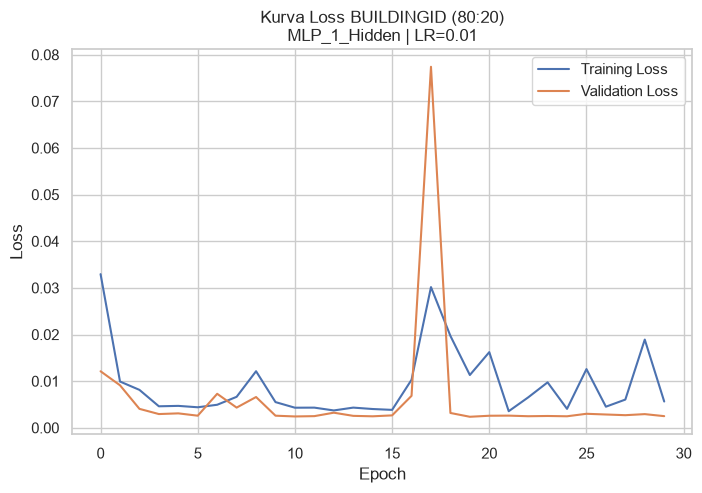

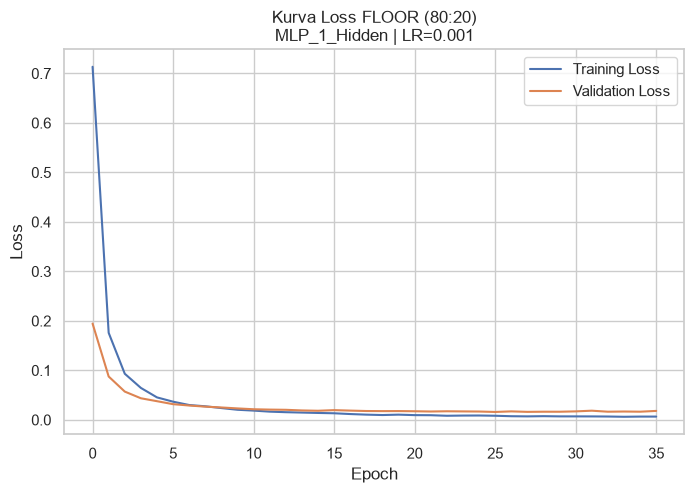

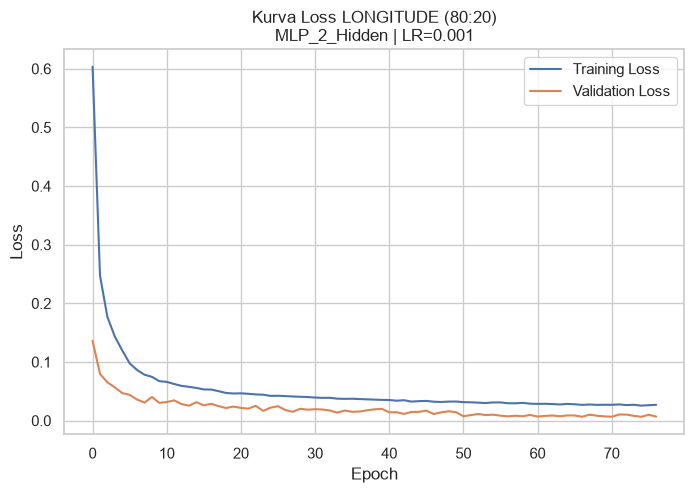

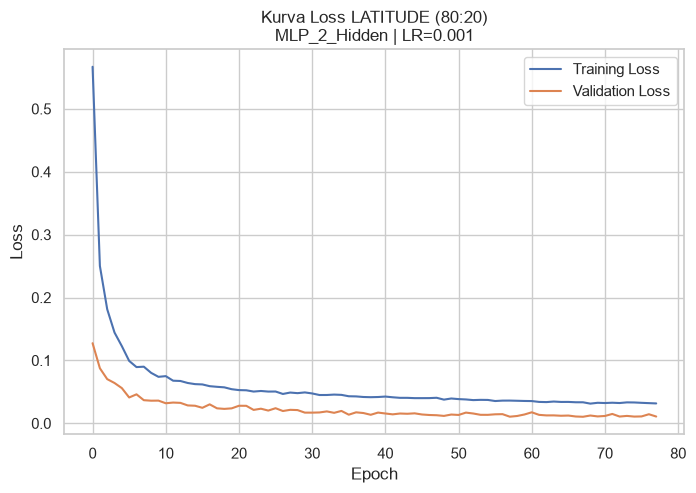

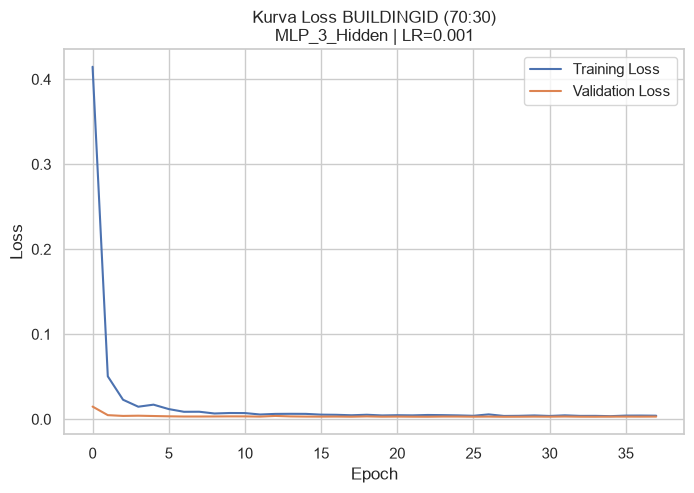

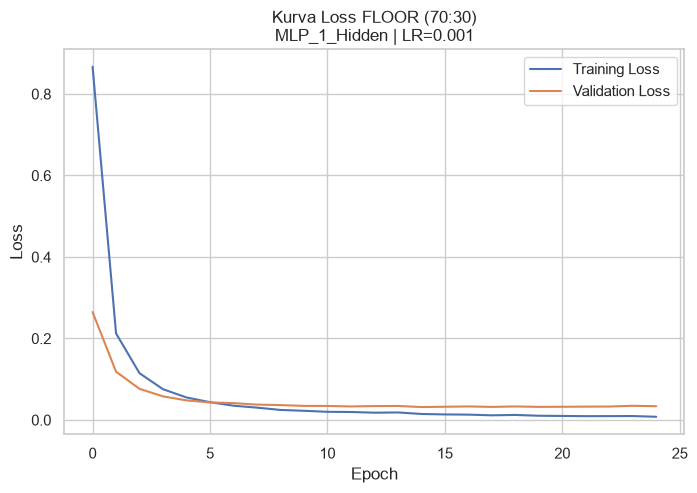

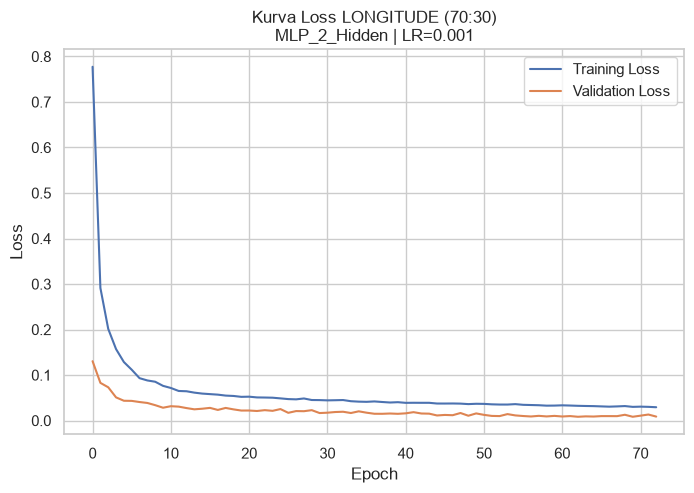

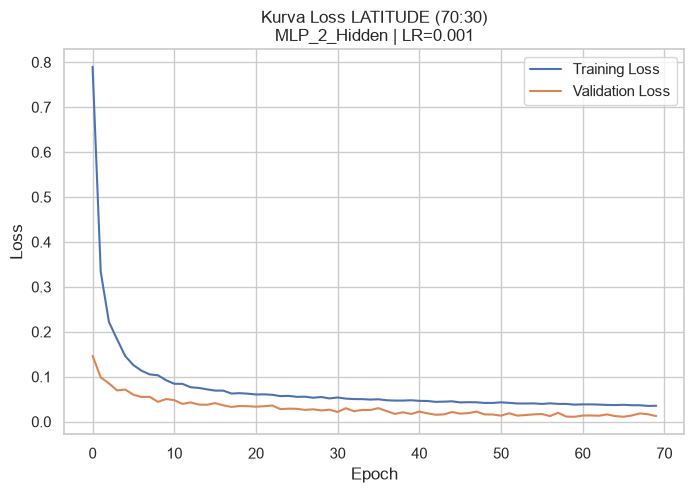

In [84]:
# KURVA LOSS MODEL MLP TERBAIK
import matplotlib.pyplot as plt

for scenario, best_models in [
    ("80:20", best_mlp_80),
    ("70:30", best_mlp_70)
]:

    for target, item in best_models.items():

        history = item["History"].history

        plt.figure(figsize=(8, 5))

        plt.plot(
            history["loss"],
            label="Training Loss"
        )

        plt.plot(
            history["val_loss"],
            label="Validation Loss"
        )

        plt.title(
            f"Kurva Loss {target} ({scenario})\n"
            f"{item['Architecture']} | "
            f"LR={item['Learning Rate']}"
        )

        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True)
        plt.show()

### 81. Analisis Overfitting dan Underfitting

Analisis dilakukan dengan membandingkan kurva training loss dan validation loss pada setiap model MLP terpilih.

Secara umum, kurva menunjukkan penurunan loss yang cepat pada awal pelatihan, kemudian bergerak lebih stabil.

Pada beberapa model regresi, validation loss berada di bawah training loss. Kondisi ini dapat dipengaruhi oleh penggunaan Dropout selama pelatihan.

Tidak ditemukan pola kenaikan validation loss yang berlangsung secara konsisten ketika training loss terus menurun. Oleh karena itu, berdasarkan kurva yang diamati, belum terlihat indikasi overfitting yang kuat.

Evaluasi ini juga menunjukkan bahwa Early Stopping membantu menghentikan pelatihan ketika performa validation tidak lagi mengalami perbaikan.

### 82. Permutation Feature Importance Berbasis MLP

Permutation Feature Importance digunakan untuk mengukur kontribusi setiap fitur terhadap performa model MLP.

Analisis dilakukan pada model klasifikasi BUILDINGID skenario 80:20 yang menggunakan arsitektur MLP 2 Hidden dan learning rate 0.001.

Metode ini bekerja dengan mengacak nilai satu fitur pada data validation, kemudian mengukur perubahan performa model. Penurunan Macro F1 menunjukkan bahwa fitur tersebut memiliki kontribusi terhadap prediksi model.

Analisis hanya dilakukan pada data validation. Data testing tidak digunakan dalam proses perhitungan feature importance.

In [85]:
# PERMUTATION FEATURE IMPORTANCE MLP
from sklearn.metrics import f1_score

# Ambil model MLP terbaik
best_building_mlp = best_mlp_80["BUILDINGID"]["Model"]

X_val_importance = X_mlp_val_processed_80.copy()
y_val_importance = y_mlp_val_80["BUILDINGID"].to_numpy()

# Nama fitur setelah preprocessing
selected_feature_mask = (
    mlp_preprocessor_80
    .named_steps["selector"]
    .get_support()
)

selected_features = np.array(rssi_features)[selected_feature_mask]

assert X_val_importance.shape[1] == len(selected_features)

# Macro F1 baseline
baseline_predictions = np.argmax(
    best_building_mlp.predict(
        X_val_importance, verbose=0
    ),
    axis=1
)

baseline_f1 = f1_score(
    y_val_importance,
    baseline_predictions,
    average="macro"
)

print("Baseline Macro F1:", baseline_f1)

# Permutation
rng = np.random.RandomState(42)
n_repeats = 5

importance_results = []

for feature_idx, feature_name in enumerate(selected_features):

    score_drops = []

    for repeat in range(n_repeats):

        X_permuted = X_val_importance.copy()

        shuffled_values = X_permuted[:, feature_idx].copy()
        rng.shuffle(shuffled_values)

        X_permuted[:, feature_idx] = shuffled_values

        predictions = np.argmax(
            best_building_mlp.predict(
                X_permuted, verbose=0
            ),
            axis=1
        )

        permuted_f1 = f1_score(
            y_val_importance,
            predictions,
            average="macro"
        )

        score_drops.append(baseline_f1 - permuted_f1)

    importance_results.append({
        "Feature": feature_name,
        "Importance Mean": np.mean(score_drops),
        "Importance Std": np.std(score_drops)
    })

# Tabel hasil
permutation_importance_mlp = (
    pd.DataFrame(importance_results)
    .sort_values("Importance Mean", ascending=False)
    .reset_index(drop=True)
)

print("\n=== TOP 20 PERMUTATION FEATURE IMPORTANCE MLP ===")
display(permutation_importance_mlp.head(20))

print("\nJumlah fitur dianalisis:", len(selected_features))

Baseline Macro F1: 0.9986973553067705

=== TOP 20 PERMUTATION FEATURE IMPORTANCE MLP ===


,Feature,Importance Mean,Importance Std
0,WAP015,0.000555,0.000189
1,WAP194,0.000407,0.000164
2,WAP218,0.000391,0.000320
3,WAP101,0.000260,0.000243
4,WAP173,0.000260,0.000243
5,WAP001,0.000227,0.000189
6,WAP411,0.000227,0.000189
7,WAP223,0.000212,0.000176
8,WAP021,0.000212,0.000290
9,WAP070,0.000196,0.000392



Jumlah fitur dianalisis: 457


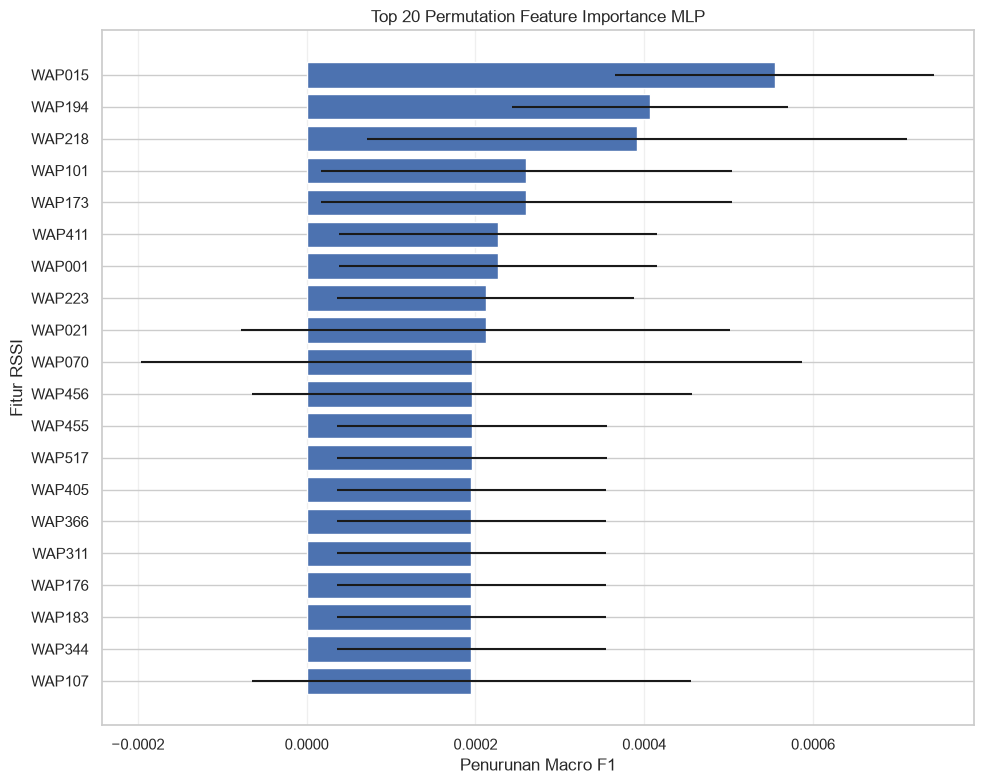

In [86]:
# VISUALISASI TOP 20 FITUR
top_features = permutation_importance_mlp.head(20).sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Penurunan Macro F1")
plt.ylabel("Fitur RSSI")
plt.title("Top 20 Permutation Feature Importance MLP")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 83. Perbandingan MLP dengan Model ML Terbaik

Tahap ini membandingkan performa model MLP/ANN dengan model Machine Learning terbaik dari Tahap 3. Berdasarkan hasil eksperimen sebelumnya, Random Forest menjadi model pembanding karena menghasilkan performa terbaik pada tugas klasifikasi dan regresi.

Perbandingan mencakup target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE pada skenario pembagian data 80:20 dan 70:30.

Untuk klasifikasi, evaluasi menggunakan Accuracy dan Macro F1. Untuk regresi, evaluasi menggunakan MAE, RMSE, dan R².

Perbandingan dilakukan untuk mengetahui apakah MLP/ANN mampu memberikan performa yang lebih baik dibandingkan Random Forest.

In [87]:
# Memeriksa variabel hasil eksperimen Tahap 3 dan Tahap 4

print("=== VARIABEL HASIL ML TAHAP 3 ===")
for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "result", "hasil", "summary", "comparison", "best"
    ]):
        nilai = globals()[nama]
        if isinstance(nilai, pd.DataFrame):
            print(f"{nama}: {nilai.shape}")

print("\n=== VARIABEL HASIL MLP TAHAP 4 ===")
for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "result", "hasil", "summary", "comparison", "best"
    ]):
        nilai = globals()[nama]
        if isinstance(nilai, (dict, list)):
            print(f"{nama}: {type(nilai).__name__}, jumlah={len(nilai)}")

=== VARIABEL HASIL ML TAHAP 3 ===
classification_summary: (24, 12)
classification_test_summary: (4, 6)
dbi_comparison: (3, 3)
dbscan_comparison: (4, 7)
final_clustering_comparison: (5, 10)
kmeans_comparison_df: (3, 5)
missing_summary: (0, 2)
pipeline_test_results: (8, 6)
regression_summary: (24, 12)
results_building_70: (6, 10)
results_building_80: (6, 10)
results_floor_70: (6, 10)
results_floor_80: (6, 10)
results_latitude_70: (6, 10)
results_latitude_80: (6, 10)
results_longitude_70: (6, 10)
results_longitude_80: (6, 10)
rssi_comparison: (4, 6)
sentinel_summary: (520, 3)

=== VARIABEL HASIL MLP TAHAP 4 ===
best_mlp_70: dict, jumlah=4
best_mlp_80: dict, jumlah=4
best_models: dict, jumlah=4
comparison_results: list, jumlah=4
dbi_results: list, jumlah=3
dbscan_external_results: list, jumlah=4
dbscan_results: list, jumlah=4
hasil_tuning: list, jumlah=24
importance_results: list, jumlah=457
kmeans_comparison: list, jumlah=3
mlp_results_70: dict, jumlah=4
mlp_results_80: dict, jumlah=4
out

### 84. Pemeriksaan Struktur Hasil Model

Tahap ini memeriksa struktur hasil evaluasi model Machine Learning pada Tahap 3 dan hasil pelatihan MLP pada Tahap 4.

Pemeriksaan mencakup:
1. Memastikan hasil model klasifikasi BUILDINGID dan FLOOR tersedia.
2. Memastikan hasil model regresi LONGITUDE dan LATITUDE tersedia.
3. Memeriksa hasil model terbaik MLP pada skenario pembagian data 80:20 dan 70:30.
4. Menyiapkan data untuk perbandingan performa model Machine Learning dan MLP.

Pemeriksaan ini dilakukan agar perbandingan menggunakan hasil eksperimen yang sesuai dengan target dan skenario pembagian data.

In [88]:
# Memeriksa kolom hasil Machine Learning Tahap 3
ml_result_vars = [
    "results_building_80",
    "results_floor_80",
    "results_longitude_80",
    "results_latitude_80",
    "results_building_70",
    "results_floor_70",
    "results_longitude_70",
    "results_latitude_70"
]

for nama in ml_result_vars:
    print(f"\n=== {nama} ===")
    display(globals()[nama].head())

# Memeriksa hasil MLP terbaik
print("\n=== BEST MLP 80:20 ===")
for target, detail in best_mlp_80.items():
    print(target, detail)

print("\n=== BEST MLP 70:30 ===")
for target, detail in best_mlp_70.items():
    print(target, detail)


=== results_building_80 ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Logistic Regression,0.998381,0.000679,0.998862,0.000476,0.997895,0.000888,0.998374,0.000686,0.998381
1,Random Forest,0.998316,0.000660,0.998782,0.000464,0.997811,0.000861,0.998292,0.000665,0.998381
2,KNN,0.998057,0.000579,0.998595,0.000391,0.997512,0.000782,0.998048,0.000586,0.998235
3,Gradient Boosting,0.997798,0.000692,0.997158,0.000885,0.998412,0.000496,0.997776,0.000694,0.997798
4,Decision Tree,0.996762,0.000766,0.997456,0.000603,0.996009,0.000939,0.996723,0.000761,0.998381



=== results_floor_80 ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996891,0.001305,0.997344,0.001112,0.996618,0.001967,0.996972,0.001499,0.998316
1,Logistic Regression,0.991839,0.001915,0.990800,0.002198,0.993033,0.002027,0.991895,0.002007,0.998025
2,SVM,0.989573,0.000804,0.991220,0.000711,0.988950,0.000931,0.990037,0.000813,0.995855
3,KNN,0.980440,0.001895,0.980486,0.003505,0.981648,0.002488,0.981035,0.002944,0.988682
4,Gradient Boosting,0.977461,0.002105,0.980770,0.002021,0.978525,0.001345,0.979574,0.001399,0.985185



=== results_longitude_80 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.086458,0.097516,8.341325,0.674437,0.995459,0.000760,1.378732,6.184420,0.997520
1,Decision Tree,3.291495,0.162580,10.637231,1.152113,0.992576,0.001706,0.376003,5.818444,0.997804
2,Gradient Boosting,15.984632,0.269807,22.426812,0.418466,0.967393,0.001313,15.485249,21.647216,0.969644
3,Ridge Regression,20.575820,0.168092,28.126877,0.258219,0.948722,0.001271,19.809768,27.185248,0.952125
4,Linear Regression,20.576482,0.167979,28.127821,0.258347,0.948719,0.001272,19.809575,27.185246,0.952125


... (7 outputs left out)

,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.289249,0.139315,8.376538,0.653425,0.995440,0.000632,1.448727,6.134773,0.997560
1,Decision Tree,3.621818,0.111696,11.353254,0.504719,0.991632,0.000856,0.362780,5.713943,0.997882
2,Gradient Boosting,16.134503,0.250897,22.425685,0.605069,0.967411,0.001947,15.550396,21.621279,0.969753
3,Ridge Regression,20.676906,0.365340,28.302483,0.602361,0.948155,0.001348,19.769261,27.128459,0.952385
4,Linear Regression,20.678172,0.364315,28.304640,0.601359,0.948147,0.001344,19.769112,27.128454,0.952385



=== results_latitude_70 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.602402,0.119031,5.889187,0.423506,0.992369,0.001085,1.114670,3.999904,0.996490
1,Decision Tree,2.868881,0.138448,7.837475,0.389192,0.986518,0.001315,0.241739,3.616815,0.997127
2,Gradient Boosting,10.823916,0.219283,14.592304,0.197342,0.953354,0.001543,10.414644,14.020109,0.956968
3,Ridge Regression,13.161073,0.180569,17.741191,0.300158,0.931068,0.001927,12.594059,17.008464,0.936671
4,Linear Regression,13.161791,0.180527,17.741933,0.300093,0.931063,0.001927,12.594226,17.008462,0.936671



=== BEST MLP 80:20 ===
BUILDINGID {'Target': 'BUILDINGID', 'Architecture': 'MLP_1_Hidden', 'Hidden Layers': '[64]', 'Learning Rate': 0.01, 'Optimizer': 'Adam', 'Parameters': 29507, 'Training Time (s)': 16.41, 'Epochs': 30, 'Train Loss': 0.005633007735013962, 'Validation Loss': 0.0023600696586072445, 'Validation Accuracy': 0.9987046718597412, 'Model': <Sequential name=sequential_1, built=True>, 'History': <keras.src.callbacks.history.History object at 0x0000024132A0EAD0>}
FLOOR {'Target': 'FLOOR', 'Architecture': 'MLP_1_Hidden', 'Hidden Layers': '[64]', 'Learning Rate': 0.001, 'Optimizer': 'Adam', 'Parameters': 29637, 'Training Time (s)': 13.55, 'Epochs': 36, 'Train Loss': 0.006579138338565826, 'Validation Loss': 0.015942147001624107, 'Validation Accuracy': 0.9954662919044495, 'Model': <Sequential name=sequential_6, built=True>, 'History': <keras.src.callbacks.history.History object at 0x0000024145F6CC00>}
LONGITUDE {'Target': 'LONGITUDE', 'Architecture': 'MLP_2_Hidden', 'Hidden Layers

### 85. Perbandingan Performa Machine Learning dan MLP

Tahap ini membandingkan model Machine Learning terbaik dari Tahap 3 dengan model MLP terbaik dari Tahap 4.

Perbandingan dilakukan pada empat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE, dengan skenario pembagian data 80:20 dan 70:30.

Metrik evaluasi yang digunakan:
- Klasifikasi: Accuracy dan Macro F1.
- Regresi: MAE, RMSE, dan R².

Hasil perbandingan digunakan untuk mengetahui kemampuan MLP dalam menyelesaikan tugas klasifikasi dan regresi dibandingkan model Machine Learning terbaik.

Perlu diperhatikan bahwa hasil Machine Learning menggunakan rata-rata 5-fold cross-validation, sedangkan hasil MLP menggunakan data validasi. Perbedaan metode evaluasi ini menjadi batasan dalam interpretasi perbandingan.

### 86. Tabel Perbandingan ML dan MLP

Bagian ini menyajikan perbandingan performa model Machine Learning terbaik dari Tahap 3 dengan model MLP terbaik dari Tahap 4.

Perbandingan mencakup empat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE, pada skenario pembagian data 80:20 dan 70:30.

Metrik klasifikasi yang digunakan adalah Accuracy dan Macro F1. Sementara itu, metrik regresi yang digunakan adalah MAE, RMSE, dan R².

Hasil perbandingan disajikan dalam bentuk tabel agar perbedaan performa kedua pendekatan lebih mudah dianalisis.

In [89]:
ml_result_vars = [
    "results_building_80",
    "results_floor_80",
    "results_longitude_80",
    "results_latitude_80",
    "results_building_70",
    "results_floor_70",
    "results_longitude_70",
    "results_latitude_70"
]

for nama in ml_result_vars:
    print(f"\n=== {nama} ===")
    print(globals()[nama].columns.tolist())
    display(globals()[nama].head(1))


=== results_building_80 ===
['Model', 'Accuracy Mean', 'Accuracy Std', 'Precision Macro Mean', 'Precision Macro Std', 'Recall Macro Mean', 'Recall Macro Std', 'F1 Macro Mean', 'F1 Macro Std', 'Train Accuracy Mean']


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Logistic Regression,0.998381,0.000679,0.998862,0.000476,0.997895,0.000888,0.998374,0.000686,0.998381



=== results_floor_80 ===
['Model', 'Accuracy Mean', 'Accuracy Std', 'Precision Macro Mean', 'Precision Macro Std', 'Recall Macro Mean', 'Recall Macro Std', 'F1 Macro Mean', 'F1 Macro Std', 'Train Accuracy Mean']


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996891,0.001305,0.997344,0.001112,0.996618,0.001967,0.996972,0.001499,0.998316



=== results_longitude_80 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.086458,0.097516,8.341325,0.674437,0.995459,0.00076,1.378732,6.18442,0.99752


... (6 outputs left out)


=== results_longitude_70 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.289249,0.139315,8.376538,0.653425,0.99544,0.000632,1.448727,6.134773,0.99756



=== results_latitude_70 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.602402,0.119031,5.889187,0.423506,0.992369,0.001085,1.11467,3.999904,0.99649


In [90]:
import pandas as pd

def buat_tabel_perbandingan(split, hasil_ml, hasil_mlp, model_terbaik):
    records = []

    target_classification = ["BUILDINGID", "FLOOR"]
    target_regression = ["LONGITUDE", "LATITUDE"]

    for target in target_classification + target_regression:

        # Ambil hasil Machine Learning terbaik
        ml_row = hasil_ml[target].iloc[0]

        # Ambil informasi model MLP terbaik
        best_info = model_terbaik[target]

        # Cari baris evaluasi MLP sesuai arsitektur dan learning rate terbaik
        mlp_df = hasil_mlp[target]

        mlp_row = mlp_df[
            (mlp_df["Architecture"] == best_info["Architecture"]) &
            (mlp_df["Learning Rate"] == best_info["Learning Rate"])
        ].iloc[0]

        # Hasil klasifikasi
        if target in target_classification:
            records.append({
                "Split": split,
                "Target": target,
                "Model": ml_row["Model"],
                "Accuracy": ml_row["Accuracy Mean"],
                "Macro F1": ml_row["F1 Macro Mean"],
                "MAE": None,
                "RMSE": None,
                "R2": None
            })

            records.append({
                "Split": split,
                "Target": target,
                "Model": (
                    f'MLP {best_info["Architecture"]} '
                    f'(LR={best_info["Learning Rate"]})'
                ),
                "Accuracy": mlp_row["Accuracy"],
                "Macro F1": mlp_row["F1 Macro"],
                "MAE": None,
                "RMSE": None,
                "R2": None
            })

        # Hasil regresi
        else:
            records.append({
                "Split": split,
                "Target": target,
                "Model": ml_row["Model"],
                "Accuracy": None,
                "Macro F1": None,
                "MAE": ml_row["MAE Mean"],
                "RMSE": ml_row["RMSE Mean"],
                "R2": ml_row["R2 Mean"]
            })

            records.append({
                "Split": split,
                "Target": target,
                "Model": (
                    f'MLP {best_info["Architecture"]} '
                    f'(LR={best_info["Learning Rate"]})'
                ),
                "Accuracy": None,
                "Macro F1": None,
                "MAE": mlp_row["MAE"],
                "RMSE": mlp_row["RMSE"],
                "R2": mlp_row["R2"]
            })

    return pd.DataFrame(records)


# Hasil Machine Learning
hasil_ml_80 = {
    "BUILDINGID": results_building_80,
    "FLOOR": results_floor_80,
    "LONGITUDE": results_longitude_80,
    "LATITUDE": results_latitude_80
}

hasil_ml_70 = {
    "BUILDINGID": results_building_70,
    "FLOOR": results_floor_70,
    "LONGITUDE": results_longitude_70,
    "LATITUDE": results_latitude_70
}

# Membuat tabel perbandingan
tabel_perbandingan_80 = buat_tabel_perbandingan(
    "80:20",
    hasil_ml_80,
    mlp_evaluation_80,
    best_mlp_80
)

tabel_perbandingan_70 = buat_tabel_perbandingan(
    "70:30",
    hasil_ml_70,
    mlp_evaluation_70,
    best_mlp_70
)

# Menggabungkan kedua skenario
tabel_perbandingan = pd.concat(
    [tabel_perbandingan_80, tabel_perbandingan_70],
    ignore_index=True
)

# Menampilkan hasil
display(
    tabel_perbandingan.round(6)
)

,Split,Target,Model,Accuracy,Macro F1,MAE,RMSE,R2
0,80:20,BUILDINGID,Logistic Regression,0.998381,0.998374,NaN,NaN,NaN
1,80:20,BUILDINGID,MLP MLP_1_Hidden (LR=0.01),0.998705,0.998697,NaN,NaN,NaN
2,80:20,FLOOR,Random Forest,0.996891,0.996972,NaN,NaN,NaN
3,80:20,FLOOR,MLP MLP_1_Hidden (LR=0.001),0.995466,0.996214,NaN,NaN,NaN
4,80:20,LONGITUDE,Random Forest,NaN,NaN,3.086458,8.341325,0.995459
5,80:20,LONGITUDE,MLP MLP_2_Hidden (LR=0.001),NaN,NaN,6.380283,10.048708,0.993423
6,80:20,LATITUDE,Random Forest,NaN,NaN,2.449973,5.702763,0.992787
7,80:20,LATITUDE,MLP MLP_2_Hidden (LR=0.001),NaN,NaN,4.364591,6.882801,0.989632
8,70:30,BUILDINGID,Random Forest,0.998520,0.998513,NaN,NaN,NaN
9,70:30,BUILDINGID,MLP MLP_3_Hidden (LR=0.001),0.998520,0.998511,NaN,NaN,NaN


### 87. Analisis Hasil Perbandingan ML dan MLP

Berdasarkan hasil perbandingan, performa Machine Learning dan Multilayer Perceptron (MLP) menunjukkan variasi menurut target dan skenario pembagian data.

Pada target BUILDINGID skenario 80:20, MLP menghasilkan Accuracy dan Macro F1 sebesar 0,9987, sedikit lebih tinggi dibandingkan Logistic Regression yang memperoleh nilai sekitar 0,9984. Pada skenario 70:30, MLP (Accuracy 0,9989 dan Macro F1 0,9989) sedikit lebih tinggi dibandingkan Random Forest (0,9985 dan 0,9985).

Pada target FLOOR, Random Forest menghasilkan Macro F1 lebih tinggi dibandingkan MLP pada kedua skenario. Pada skenario 80:20, Random Forest memperoleh Macro F1 sebesar 0,9966, sedangkan MLP sebesar 0,9962. Pada skenario 70:30, masing-masing memperoleh sekitar 0,9958 dan 0,9934. Hasil ini menunjukkan bahwa Random Forest memberikan performa klasifikasi FLOOR yang sedikit lebih baik pada eksperimen tersebut.

Pada tugas regresi LONGITUDE dan LATITUDE, Random Forest menunjukkan performa lebih baik dibandingkan MLP berdasarkan MAE, RMSE, dan R² pada hasil perbandingan yang diuji. Pada skenario 80:20, MAE LONGITUDE Random Forest sebesar 3,08 m dibandingkan 5,93 m pada MLP. Untuk LATITUDE, MAE Random Forest sebesar 2,45 m, sedangkan MLP sebesar 4,56 m.

Secara umum, MLP menunjukkan performa yang kompetitif pada klasifikasi, khususnya BUILDINGID, sedangkan Random Forest memberikan hasil yang lebih baik pada FLOOR dan regresi koordinat. Meskipun demikian, hasil Machine Learning pada tabel ini berasal dari rata-rata 5-fold cross-validation, sedangkan hasil MLP berasal dari validation internal. Oleh karena itu, perbandingan tersebut bersifat deskriptif dan tidak sepenuhnya merupakan perbandingan pada data evaluasi yang sama.

Evaluasi tambahan pada validation independen dilakukan untuk membandingkan kemampuan generalisasi kedua pendekatan pada observasi yang sama.

### 88. Penentuan Model Terbaik

Skenario pembagian data 80:20 dipilih sebagai skenario utama untuk evaluasi akhir. Pemilihan ini mempertimbangkan proporsi data training yang lebih besar serta hasil evaluasi yang menunjukkan performa kompetitif pada sebagian besar target.

Skenario 70:30 tetap digunakan sebagai pembanding untuk menganalisis pengaruh proporsi data training dan testing terhadap performa model.

Penentuan model terbaik dilakukan secara terpisah untuk setiap target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE. Model yang telah ditentukan kemudian dievaluasi menggunakan data test dari skenario 80:20.

Data test hanya digunakan pada evaluasi akhir dan tidak dilibatkan dalam pemilihan model, preprocessing, maupun penyesuaian parameter.

### 89. Evaluasi Akhir Model pada Data Test

Evaluasi akhir dilakukan menggunakan data test dari skenario pembagian data 80:20. Tahap ini bertujuan mengukur kemampuan generalisasi model terbaik pada data yang belum digunakan selama proses pelatihan dan pemilihan model.

Model dievaluasi secara terpisah untuk setiap target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Berdasarkan hasil cross-validation, model Machine Learning yang digunakan adalah Logistic Regression untuk BUILDINGID, Random Forest untuk FLOOR, serta Random Forest hasil tuning untuk LONGITUDE dan LATITUDE. MLP dievaluasi sebagai pembanding pada target FLOOR (Bagian 100).

Metrik evaluasi klasifikasi meliputi Accuracy, Precision, Recall, dan Macro F1. Sementara itu, evaluasi regresi menggunakan MAE, RMSE, dan R².

Seluruh preprocessing dan pelatihan ulang model dilakukan menggunakan data training 80%. Data test hanya digunakan untuk menghasilkan prediksi dan menghitung metrik evaluasi akhir.

In [91]:
# Memeriksa variabel model dan pipeline yang tersedia
print("=== Variabel terkait model ===")

for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "model", "pipeline", "best_mlp", "scaler", "preprocess"
    ]):
        objek = globals()[nama]
        if not callable(objek):
            print(nama, ":", type(objek).__name__)

print("\n=== Fungsi preprocessing ===")
print(build_preprocessing_pipeline)

=== Variabel terkait model ===
best_mlp_70 : dict
best_mlp_80 : dict
best_models : dict
classification_models_building : dict
classification_models_floor : dict
clustering_preprocessor : Pipeline
comparison_pipeline_test : Pipeline
dbscan_models : dict
df_train_model : DataFrame
kmeans_models : dict
mlp_preprocessor_70 : Pipeline
mlp_preprocessor_80 : Pipeline
model : RandomForestRegressor
model_building_70 : Pipeline
model_building_80 : Pipeline
model_dasar : RandomForestRegressor
model_floor_70 : Pipeline
model_floor_80 : Pipeline
model_latitude_70 : Pipeline
model_latitude_80 : Pipeline
model_longitude_70 : Pipeline
model_longitude_80 : Pipeline
model_name : str
model_tuning_terbaik : dict
nama_model : str
pipeline : Pipeline
pipeline_building_test : Pipeline
pipeline_regression_test : Pipeline
pipeline_test_70 : DataFrame
pipeline_test_results : DataFrame
polynomial_model : dict
preprocessing_configs : list
regression_models : dict
scaler : str
scaler_70 : StandardScaler
scaler_80 

### 90. Pemeriksaan Model dan Data Test

Sebelum melakukan evaluasi akhir, dilakukan pemeriksaan terhadap model dan pipeline preprocessing yang telah dibangun pada skenario pembagian data 80:20.

Pemeriksaan ini bertujuan memastikan bahwa:
- Data training dan data test memiliki ukuran yang sesuai.
- Pipeline Machine Learning untuk setiap target telah tersedia.
- Model MLP terbaik untuk setiap target telah tersimpan.
- Pipeline preprocessing MLP telah tersedia dan siap digunakan.

Pemeriksaan dilakukan untuk memastikan seluruh komponen evaluasi akhir dapat digunakan sesuai prosedur penelitian. Data test tetap tidak digunakan untuk proses fitting maupun pemilihan model.

In [92]:
print("=== UKURAN DATA ===")
print("X_train_80:", X_train_80.shape)
print("X_test_80 :", X_test_80.shape)

print("\n=== PIPELINE MACHINE LEARNING ===")

pipeline_vars = [
    "model_building_80",
    "model_floor_80",
    "model_longitude_80",
    "model_latitude_80"
]

for nama in pipeline_vars:
    pipe = globals()[nama]
    print(f"\n{nama}")
    print("Tipe:", type(pipe).__name__)
    print("Langkah:", list(pipe.named_steps.keys()))

print("\n=== BEST MODELS ML ===")
print("Keys:", best_models.keys())

print("\n=== BEST MLP 80 ===")

for target, detail in best_mlp_80.items():
    print(f"\nTarget: {target}")
    print("Architecture:", detail["Architecture"])
    print("Learning Rate:", detail["Learning Rate"])
    print("Optimizer:", detail["Optimizer"])
    print("Epochs:", detail["Epochs"])
    print("Model:", type(detail["Model"]).__name__)

print("\n=== MLP PREPROCESSOR ===")
print("Langkah:", list(mlp_preprocessor_80.named_steps.keys()))

=== UKURAN DATA ===
X_train_80: (15440, 520)
X_test_80 : (3860, 520)

=== PIPELINE MACHINE LEARNING ===

model_building_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_floor_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_longitude_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_latitude_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

=== BEST MODELS ML ===
Keys: dict_keys(['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE'])

=== BEST MLP 80 ===

Target: BUILDINGID
Architecture: MLP_1_Hidden
Learning Rate: 0.01
Optimizer: Adam
Epochs: 30
Model: Sequential

Target: FLOOR
Architecture: MLP_1_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 36
Model: Sequential

Target: LONGITUDE
Architecture: MLP_2_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 77
Model: Sequential

Target: LATITUDE
Architecture: MLP_2_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 78
Model: Sequential

=== MLP PREPROCESSOR ===
Langkah: ['sentinel_replacement', 'sel

### 91. Pemeriksaan Detail Model Terbaik

Pemeriksaan detail model dilakukan untuk memastikan algoritma dan konfigurasi model terbaik pada setiap target telah tersimpan dengan benar.

Pemeriksaan mencakup jenis model, arsitektur MLP, learning rate, optimizer, serta konfigurasi model Machine Learning yang akan digunakan pada evaluasi akhir.

In [93]:

print("=== DETAIL MODEL MACHINE LEARNING 80:20 ===")

best_ml_pipelines_80 = {
    "BUILDINGID": model_building_80,
    "FLOOR": model_floor_80,
    "LONGITUDE": model_longitude_80,
    "LATITUDE": model_latitude_80
}

for target, pipe in best_ml_pipelines_80.items():
    estimator = pipe.named_steps["model"]

    print(f"\nTarget: {target}")
    print("Jenis model:", type(estimator).__name__)
    print("Parameter model:")

    params = estimator.get_params()

    for key in [
        "n_estimators",
        "max_depth",
        "max_features",
        "min_samples_split",
        "min_samples_leaf",
        "class_weight",
        "random_state"
    ]:
        if key in params:
            print(f"{key}: {params[key]}")


print("\n=== DETAIL MODEL MLP 80:20 ===")

for target, detail in best_mlp_80.items():
    print(f"\nTarget: {target}")
    print("Architecture:", detail["Architecture"])
    print("Hidden Layers:", detail["Hidden Layers"])
    print("Learning Rate:", detail["Learning Rate"])
    print("Optimizer:", detail["Optimizer"])
    print("Epochs:", detail["Epochs"])
    print("Model:", type(detail["Model"]).__name__)


=== DETAIL MODEL MACHINE LEARNING 80:20 ===

Target: BUILDINGID
Jenis model: LogisticRegression
Parameter model:
class_weight: None
random_state: 42

Target: FLOOR
Jenis model: RandomForestClassifier
Parameter model:
n_estimators: 200
max_depth: None
max_features: sqrt
min_samples_split: 2
min_samples_leaf: 1
class_weight: balanced
random_state: 42

Target: LONGITUDE
Jenis model: RandomForestRegressor
Parameter model:
n_estimators: 200
max_depth: None
max_features: 1.0
min_samples_split: 2
min_samples_leaf: 1
random_state: 42

Target: LATITUDE
Jenis model: RandomForestRegressor
Parameter model:
n_estimators: 200
max_depth: None
max_features: 1.0
min_samples_split: 2
min_samples_leaf: 1
random_state: 42

=== DETAIL MODEL MLP 80:20 ===

Target: BUILDINGID
Architecture: MLP_1_Hidden
Hidden Layers: [64]
Learning Rate: 0.01
Optimizer: Adam
Epochs: 30
Model: Sequential

Target: FLOOR
Architecture: MLP_1_Hidden
Hidden Layers: [64]
Learning Rate: 0.001
Optimizer: Adam
Epochs: 36
Model: Sequent

### 92. Pemeriksaan Variabel Target

Pemeriksaan nama variabel target dilakukan untuk memastikan kesesuaian variabel target training dan testing pada skenario pembagian data 80:20.

Tahap ini juga memastikan bahwa variabel yang digunakan dalam evaluasi akhir sesuai dengan struktur notebook dan hasil preprocessing yang telah dilakukan sebelumnya.

In [94]:
print("=== VARIABEL TARGET YANG TERSEDIA ===")

for nama in sorted(globals()):
    if nama.lower().startswith("y_") and "80" in nama.lower():
        obj = globals()[nama]
        print(nama, ":", getattr(obj, "shape", type(obj).__name__))

print("\n=== VARIABEL TARGET BUILDING DAN FLOOR ===")

for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "building", "floor", "longitude", "latitude"
    ]) and nama.lower().startswith("y_"):
        obj = globals()[nama]
        print(nama, ":", getattr(obj, "shape", type(obj).__name__))

=== VARIABEL TARGET YANG TERSEDIA ===
y_building_80 : (15440,)
y_floor_80 : (15440,)
y_latitude_80 : (15440,)
y_longitude_80 : (15440,)
y_mlp_train_80 : (12352, 4)
y_mlp_val_80 : (3088, 4)
y_reg_scalers_80 : dict
y_test_80 : (3860, 4)
y_train_80 : (15440, 4)

=== VARIABEL TARGET BUILDING DAN FLOOR ===
y_building_70 : (13510,)
y_building_80 : (15440,)
y_cluster_building : (19300,)
y_cluster_floor : (19300,)
y_floor_70 : (13510,)
y_floor_80 : (15440,)
y_latitude_70 : (13510,)
y_latitude_80 : (15440,)
y_longitude_70 : (13510,)
y_longitude_80 : (15440,)


### 93. Validasi Kesesuaian Data Training dan Testing

Tahap ini memeriksa kesesuaian jumlah data fitur dan target pada skenario pembagian 80:20.

Pemeriksaan dilakukan untuk memastikan bahwa setiap target memiliki jumlah observasi yang sesuai dengan data fitur training dan testing. Hal ini diperlukan agar proses evaluasi akhir dapat berjalan dengan benar tanpa mengubah pembagian data yang telah ditetapkan.

In [95]:
print("=== PEMERIKSAAN DATA TRAINING DAN TESTING ===")

target_train = {
    "BUILDINGID": y_building_80,
    "FLOOR": y_floor_80,
    "LONGITUDE": y_longitude_80,
    "LATITUDE": y_latitude_80
}

for target, y in target_train.items():
    print(f"\nTarget: {target}")
    print("X Training:", X_train_80.shape)
    print("y Training:", y.shape)
    print("Jumlah sesuai:", len(X_train_80) == len(y))

print("\nX Testing:", X_test_80.shape)
print("y Testing:", y_test_80.shape)
print("Jumlah sesuai:", len(X_test_80) == len(y_test_80))

=== PEMERIKSAAN DATA TRAINING DAN TESTING ===

Target: BUILDINGID
X Training: (15440, 520)
y Training: (15440,)
Jumlah sesuai: True

Target: FLOOR
X Training: (15440, 520)
y Training: (15440,)
Jumlah sesuai: True

Target: LONGITUDE
X Training: (15440, 520)
y Training: (15440,)
Jumlah sesuai: True

Target: LATITUDE
X Training: (15440, 520)
y Training: (15440,)
Jumlah sesuai: True

X Testing: (3860, 520)
y Testing: (3860, 4)
Jumlah sesuai: True


### 94. Evaluasi Akhir Machine Learning

Evaluasi akhir Machine Learning dilakukan menggunakan pipeline terbaik untuk setiap target pada skenario pembagian data 80:20.

Pipeline yang telah dilatih menggunakan data training diterapkan pada data test untuk menghasilkan prediksi. Evaluasi klasifikasi dilakukan menggunakan Accuracy, Precision, Recall, dan Macro F1. Sementara itu, evaluasi regresi menggunakan MAE, RMSE, dan R².

Tahap ini bertujuan mengukur kemampuan generalisasi model Machine Learning terhadap data yang belum digunakan selama proses pelatihan.

In [96]:
# ==============================================================
# 72.19.5 EVALUASI AKHIR MACHINE LEARNING
# Model regresi menggunakan Random Forest hasil hyperparameter tuning
# ==============================================================

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd


# ==============================================================
# 1. MENGAMBIL PIPELINE RANDOM FOREST HASIL TUNING
# ==============================================================

nama_longitude_tuning, pipeline_longitude_tuning = (
    model_tuning_terbaik[("LONGITUDE", "80:20")]
)

nama_latitude_tuning, pipeline_latitude_tuning = (
    model_tuning_terbaik[("LATITUDE", "80:20")]
)


# Memastikan model terbaik hasil tuning adalah Random Forest

assert nama_longitude_tuning == "Random Forest", (
    f"Model LONGITUDE hasil tuning tidak sesuai: "
    f"{nama_longitude_tuning}"
)

assert nama_latitude_tuning == "Random Forest", (
    f"Model LATITUDE hasil tuning tidak sesuai: "
    f"{nama_latitude_tuning}"
)


# Memastikan parameter terbaik menggunakan max_features = 0.3

assert pipeline_longitude_tuning.named_steps[
    "model"
].max_features == 0.3

assert pipeline_latitude_tuning.named_steps[
    "model"
].max_features == 0.3


print("=== HASIL PEMILIHAN MODEL TUNING ===")

print("LONGITUDE:")
print("Model:", nama_longitude_tuning)
print(
    "Parameter:",
    pipeline_longitude_tuning.named_steps["model"].get_params()
    ["max_features"]
)

print("\nLATITUDE:")
print("Model:", nama_latitude_tuning)
print(
    "Parameter:",
    pipeline_latitude_tuning.named_steps["model"].get_params()
    ["max_features"]
)


# ==============================================================
# 2. MENETAPKAN PIPELINE MODEL FINAL
# ==============================================================

# Model klasifikasi tetap menggunakan hasil CV sebelumnya
# Model regresi menggunakan pipeline Random Forest hasil tuning

base_pipelines = {
    "BUILDINGID": model_building_80,
    "FLOOR": model_floor_80,
    "LONGITUDE": pipeline_longitude_tuning,
    "LATITUDE": pipeline_latitude_tuning
}


# Memperbarui variabel model regresi agar cell berikutnya
# tidak kembali menggunakan Random Forest bawaan

model_longitude_80 = pipeline_longitude_tuning
model_latitude_80 = pipeline_latitude_tuning


# Nama model untuk tabel hasil evaluasi

model_display_names = {
    "BUILDINGID": "Logistic Regression",
    "FLOOR": "Random Forest",
    "LONGITUDE": "Random Forest (Tuned)",
    "LATITUDE": "Random Forest (Tuned)"
}


# ==============================================================
# 3. TARGET TRAINING DAN TESTING
# ==============================================================

y_train_targets = {
    "BUILDINGID": y_building_80,
    "FLOOR": y_floor_80,
    "LONGITUDE": y_longitude_80,
    "LATITUDE": y_latitude_80
}

y_test_targets = {
    "BUILDINGID": y_test_80["BUILDINGID"],
    "FLOOR": y_test_80["FLOOR"],
    "LONGITUDE": y_test_80["LONGITUDE"],
    "LATITUDE": y_test_80["LATITUDE"]
}


# ==============================================================
# 4. PELATIHAN ULANG DAN EVALUASI MODEL FINAL
# ==============================================================

ml_pipelines = {}
ml_test_results = []

for target in ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]:

    print(f"\n=== EVALUASI {target} ===")

    # Membuat salinan pipeline sesuai model terpilih
    pipeline = clone(base_pipelines[target])

    y_train = np.asarray(
        y_train_targets[target]
    ).ravel()

    y_true = np.asarray(
        y_test_targets[target]
    ).ravel()


    # Memeriksa jenis estimator

    estimator_name = type(
        pipeline.named_steps["model"]
    ).__name__

    if target == "BUILDINGID":

        assert estimator_name == "LogisticRegression", (
            f"Estimator BUILDINGID tidak sesuai: {estimator_name}"
        )

    elif target == "FLOOR":

        assert estimator_name == "RandomForestClassifier", (
            f"Estimator FLOOR tidak sesuai: {estimator_name}"
        )

    else:

        assert estimator_name == "RandomForestRegressor", (
            f"Estimator {target} tidak sesuai: {estimator_name}"
        )


    # Fit menggunakan data training saja

    pipeline.fit(
        X_train_80,
        y_train
    )


    # Prediksi data testing

    y_pred = np.asarray(
        pipeline.predict(X_test_80)
    ).ravel()


    # Menyimpan pipeline final

    ml_pipelines[target] = pipeline


    # Menampilkan informasi evaluasi

    print("Estimator:", estimator_name)
    print("Model:", model_display_names[target])

    if target in ["LONGITUDE", "LATITUDE"]:
        print(
            "max_features:",
            pipeline.named_steps["model"].max_features
        )

    print("Jumlah training:", len(y_train))
    print("Jumlah testing:", len(y_true))

    print(
        "Rentang aktual:",
        y_true.min(), "sampai", y_true.max()
    )

    print(
        "Rentang prediksi:",
        y_pred.min(), "sampai", y_pred.max()
    )


    # ==========================================================
    # EVALUASI KLASIFIKASI
    # ==========================================================

    if target in ["BUILDINGID", "FLOOR"]:

        ml_test_results.append({

            "Target": target,

            "Model": model_display_names[target],

            "Accuracy": accuracy_score(
                y_true, y_pred
            ),

            "Precision Macro": precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "Recall Macro": recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "F1 Macro": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan

        })


    # ==========================================================
    # EVALUASI REGRESI
    # ==============================================================

    else:

        ml_test_results.append({

            "Target": target,

            "Model": model_display_names[target],

            "Accuracy": np.nan,
            "Precision Macro": np.nan,
            "Recall Macro": np.nan,
            "F1 Macro": np.nan,

            "MAE": mean_absolute_error(
                y_true, y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),

            "R2": r2_score(
                y_true, y_pred
            )

        })


# ==============================================================
# 5. TABEL EVALUASI AKHIR
# ==============================================================

ml_test_results = pd.DataFrame(
    ml_test_results
)

print("\n" + "=" * 70)
print("HASIL EVALUASI AKHIR MACHINE LEARNING")
print("=" * 70)

display(
    ml_test_results.round(6)
)

=== HASIL PEMILIHAN MODEL TUNING ===
LONGITUDE:
Model: Random Forest
Parameter: 0.3

LATITUDE:
Model: Random Forest
Parameter: 0.3

=== EVALUASI BUILDINGID ===
Estimator: LogisticRegression
Model: Logistic Regression
Jumlah training: 15440
Jumlah testing: 3860
Rentang aktual: 0 sampai 2
Rentang prediksi: 0 sampai 2

=== EVALUASI FLOOR ===
Estimator: RandomForestClassifier
Model: Random Forest
Jumlah training: 15440
Jumlah testing: 3860
Rentang aktual: 0 sampai 4
Rentang prediksi: 0 sampai 4

=== EVALUASI LONGITUDE ===
Estimator: RandomForestRegressor
Model: Random Forest (Tuned)
max_features: 0.3
Jumlah training: 15440
Jumlah testing: 3860
Rentang aktual: -7691.338399998844 sampai -7300.818990092725
Rentang prediksi: -7691.2384109988625 sampai -7301.34878008524

=== EVALUASI LATITUDE ===
Estimator: RandomForestRegressor
Model: Random Forest (Tuned)
max_features: 0.3
Jumlah training: 15440
Jumlah testing: 3860
Rentang aktual: 4864745.745015971 sampai 4865016.687799998
Rentang prediksi: 

,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Logistic Regression,0.997409,0.998181,0.996626,0.997393,NaN,NaN,NaN
1,FLOOR,Random Forest,0.995596,0.996207,0.996459,0.996322,NaN,NaN,NaN
2,LONGITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.562133,6.915435,0.996888
3,LATITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.057408,5.067562,0.994408


### 95. Analisis Hasil Prediksi Test

Pemeriksaan anomali dilakukan untuk memastikan kesesuaian antara target aktual dan hasil prediksi model pada data test.

Pemeriksaan difokuskan pada nilai target LONGITUDE yang menunjukkan kesalahan prediksi sangat besar, serta kesamaan nilai Accuracy pada BUILDINGID dan FLOOR.

Tahap ini bertujuan mengidentifikasi kemungkinan ketidaksesuaian pemetaan target, skala nilai, atau penggunaan pipeline sebelum hasil evaluasi akhir ditetapkan.

In [97]:
print("=== KOLOM DAN NILAI TARGET TEST ===")
print("Kolom:", y_test_80.columns.tolist())
display(y_test_80.describe())

print("\n=== RENTANG TARGET TRAINING ===")
target_train = {
    "BUILDINGID": y_building_80,
    "FLOOR": y_floor_80,
    "LONGITUDE": y_longitude_80,
    "LATITUDE": y_latitude_80
}

for target, y in target_train.items():
    print(f"\n{target}")
    print("Min:", y.min())
    print("Max:", y.max())
    print("Mean:", y.mean())

print("\n=== PERBANDINGAN AKTUAL DAN PREDIKSI ===")

for target, pipeline in ml_pipelines.items():
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\n{target}")
    print("Aktual (5 pertama):", y_true.iloc[:5].tolist())
    print("Prediksi (5 pertama):", np.asarray(y_pred)[:5].tolist())
    print("Min aktual:", y_true.min())
    print("Max aktual:", y_true.max())
    print("Min prediksi:", np.min(y_pred))
    print("Max prediksi:", np.max(y_pred))

=== KOLOM DAN NILAI TARGET TEST ===
Kolom: ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']


,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
count,3860.000000,3860.000000,3860.000000,3.860000e+03
mean,1.200518,1.640155,-7465.577061,4.864872e+06
std,0.839057,1.194829,123.977636,6.777278e+01
min,0.000000,0.000000,-7691.338400,4.864746e+06
25%,0.000000,1.000000,-7596.648700,4.864821e+06
50%,1.000000,2.000000,-7423.060900,4.864853e+06
75%,2.000000,3.000000,-7359.331100,4.864930e+06
max,2.000000,4.000000,-7300.818990,4.865017e+06



=== RENTANG TARGET TRAINING ===

BUILDINGID
Min: 0
Max: 2
Mean: 1.200518134715026

FLOOR
Min: 0
Max: 4
Mean: 1.639637305699482

LONGITUDE
Min: -7691.338399998844
Max: -7300.818990092725
Mean: -7465.975003977965

LATITUDE
Min: 4864745.745015971
Max: 4865016.687799998
Mean: 4864871.07239892

=== PERBANDINGAN AKTUAL DAN PREDIKSI ===

BUILDINGID
Aktual (5 pertama): [0, 2, 2, 2, 0]
Prediksi (5 pertama): [0, 2, 2, 2, 0]
Min aktual: 0
Max aktual: 2
Min prediksi: 0
Max prediksi: 2

FLOOR
Aktual (5 pertama): [3, 0, 3, 0, 1]
Prediksi (5 pertama): [3, 0, 3, 0, 1]
Min aktual: 0
Max aktual: 4
Min prediksi: 0
Max prediksi: 4

LONGITUDE
Aktual (5 pertama): [-7650.165600001812, -7390.734700001776, -7318.1603999994695, -7408.338870193809, -7647.626299999654]
Prediksi (5 pertama): [-7652.740211500544, -7383.09401009366, -7318.409019337166, -7408.655967079643, -7647.326994499787]
Min aktual: -7691.338399998844
Max aktual: -7300.818990092725
Min prediksi: -7691.2384109988625
Max prediksi: -7301.348780085

### 96. Validasi Pipeline Model dan Target

Pemeriksaan ini dilakukan untuk memastikan setiap pipeline Machine Learning menggunakan target yang sesuai dengan tugas klasifikasi atau regresi.

Pemeriksaan difokuskan pada kesesuaian model, target aktual, dan hasil prediksi. Langkah ini diperlukan untuk mengidentifikasi kemungkinan kesalahan pemetaan target sebelum hasil evaluasi akhir ditetapkan.

In [98]:
print("=== PEMERIKSAAN PIPELINE DAN MODEL ===")

for target, pipeline in ml_pipelines.items():
    print(f"\nTARGET: {target}")
    print("Pipeline:", pipeline)
    print("Model:", pipeline.named_steps["model"])

print("\n=== PEMERIKSAAN TARGET TRAINING ===")

for target, y in target_train.items():
    print(f"\n{target}")
    print("5 nilai pertama:", y.iloc[:5].tolist())

print("\n=== PEMERIKSAAN PREDIKSI TEST ===")

for target, pipeline in ml_pipelines.items():
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\nTARGET: {target}")
    print("Aktual   :", y_true.iloc[:5].tolist())
    print("Prediksi :", np.asarray(y_pred)[:5].tolist())

=== PEMERIKSAAN PIPELINE DAN MODEL ===

TARGET: BUILDINGID
Pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x00000240CCB33C40>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])
Model: LogisticRegression(max_iter=2000, random_state=42)

TARGET: FLOOR
Pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x00000240CCB33C40>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
 

### 97. Evaluasi Khusus Model Regresi

Pemeriksaan khusus dilakukan terhadap model regresi LONGITUDE dan LATITUDE karena hasil evaluasi awal menunjukkan perbedaan nilai kesalahan prediksi yang cukup besar.

Pemeriksaan mencakup jenis algoritma, rentang nilai aktual, rentang nilai prediksi, serta perbandingan beberapa hasil prediksi. Langkah ini bertujuan memastikan kesesuaian model regresi dengan target koordinat yang digunakan.

In [99]:
for target in ["LONGITUDE", "LATITUDE"]:

    pipeline = ml_pipelines[target]
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\n{'='*15} {target} {'='*15}")

    print("Jenis model:")
    print(type(pipeline.named_steps["model"]).__name__)

    print("\nRentang aktual:")
    print("Min:", y_true.min())
    print("Max:", y_true.max())

    print("\nRentang prediksi:")
    print("Min:", np.min(y_pred))
    print("Max:", np.max(y_pred))

    print("\nLima pasangan aktual dan prediksi:")
    print(pd.DataFrame({
        "Aktual": y_true.iloc[:5].values,
        "Prediksi": np.asarray(y_pred)[:5]
    }).round(6))

    print("\nMAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R2:", r2_score(y_true, y_pred))


=============== LONGITUDE ===============
Jenis model:
RandomForestRegressor

Rentang aktual:
Min: -7691.338399998844
Max: -7300.818990092725

Rentang prediksi:
Min: -7691.2384109988625
Max: -7301.34878008524

Lima pasangan aktual dan prediksi:
       Aktual     Prediksi
0 -7650.16560 -7652.740212
1 -7390.73470 -7383.094010
2 -7318.16040 -7318.409019
3 -7408.33887 -7408.655967
4 -7647.62630 -7647.326994

MAE: 2.5621329118464606
RMSE: 6.915435200694015
R2: 0.9968878189093171

=============== LATITUDE ===============
Jenis model:
RandomForestRegressor

Rentang aktual:
Min: 4864745.745015971
Max: 4865016.687799998

Rentang prediksi:
Min: 4864746.86018728
Max: 4865016.365956601

Lima pasangan aktual dan prediksi:
         Aktual      Prediksi
0  4.864937e+06  4.864936e+06
1  4.864835e+06  4.864835e+06
2  4.864815e+06  4.864815e+06
3  4.864812e+06  4.864811e+06
4  4.864944e+06  4.864945e+06

MAE: 2.057407863167901
RMSE: 5.067562484606026
R2: 0.9944075750586472


### 98. Verifikasi Pipeline Regresi LONGITUDE

Berdasarkan pemeriksaan hasil prediksi, ditemukan ketidaksesuaian antara rentang nilai aktual dan prediksi LONGITUDE. Prediksi model LONGITUDE menunjukkan rentang nilai yang menyerupai target LATITUDE.

Untuk mengatasi masalah tersebut, pipeline LONGITUDE dilatih ulang menggunakan target LONGITUDE yang benar. Proses pelatihan hanya menggunakan data training pada skenario 80:20, dengan konfigurasi model yang sama seperti eksperimen sebelumnya.

Data test tidak digunakan dalam proses pelatihan ulang maupun penyesuaian model.

In [100]:
# VERIFIKASI PIPELINE RANDOM FOREST HASIL HYPERPARAMETER TUNING

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# 1. MENYINKRONKAN PIPELINE MODEL FINAL
# Menggunakan pipeline yang sudah dilatih pada Cell 204
model_longitude_80 = ml_pipelines["LONGITUDE"]
model_latitude_80 = ml_pipelines["LATITUDE"]

# 2. MEMERIKSA KEDUA MODEL REGRESI

for target in ["LONGITUDE", "LATITUDE"]:

    print("\n" + "=" * 60)
    print(f"VERIFIKASI MODEL {target}")
    print("=" * 60)

    # Mengambil pipeline yang sudah dilatih
    pipeline = ml_pipelines[target]

    # Mengambil estimator di dalam pipeline
    estimator = pipeline.named_steps["model"]

    # Mengambil target aktual
    y_true = y_test_80[target].to_numpy()

    # Prediksi menggunakan model final
    y_pred = pipeline.predict(X_test_80)


    # Memastikan estimator adalah Random Forest Regressor
    assert type(estimator).__name__ == "RandomForestRegressor", (
        f"{target} tidak menggunakan RandomForestRegressor."
    )

    # Memastikan parameter hasil tuning
    assert np.isclose(
        estimator.max_features, 0.3
    ), f"{target} belum menggunakan max_features=0.3"


    # Menampilkan identitas model
    print("Estimator:", type(estimator).__name__)
    print("max_features:", estimator.max_features)

    # Menampilkan rentang aktual dan prediksi
    print("\nRentang aktual:")
    print(y_true.min(), "sampai", y_true.max())

    print("Rentang prediksi:")
    print(y_pred.min(), "sampai", y_pred.max())


    # Menghitung metrik regresi
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)


    # Menampilkan hasil evaluasi
    print("\nMAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)

    print("\nStatus: Pipeline hasil tuning terverifikasi.")


print("\nKedua model regresi menggunakan Random Forest hasil tuning.")


VERIFIKASI MODEL LONGITUDE
Estimator: RandomForestRegressor
max_features: 0.3

Rentang aktual:
-7691.338399998844 sampai -7300.818990092725
Rentang prediksi:
-7691.2384109988625 sampai -7301.34878008524

MAE: 2.56213291184646
RMSE: 6.9154352006940005
R2: 0.9968878189093172

Status: Pipeline hasil tuning terverifikasi.

VERIFIKASI MODEL LATITUDE
Estimator: RandomForestRegressor
max_features: 0.3

Rentang aktual:
4864745.745015971 sampai 4865016.687799998
Rentang prediksi:
4864746.86018728 sampai 4865016.365956601

MAE: 2.0574078631674184
RMSE: 5.067562484583171
R2: 0.9944075750586977

Status: Pipeline hasil tuning terverifikasi.

Kedua model regresi menggunakan Random Forest hasil tuning.


### 99. Pembaruan Hasil Evaluasi Machine Learning

Setelah perbaikan pipeline LONGITUDE, evaluasi ulang dilakukan untuk memperbarui hasil pengujian model Machine Learning pada data test.

Evaluasi menggunakan pipeline yang telah dilatih pada data training 80:20. Hasil evaluasi sebelumnya yang mengalami ketidaksesuaian target LONGITUDE tidak digunakan kembali.

Metrik evaluasi tetap mencakup Accuracy, Precision, Recall, dan Macro F1 untuk klasifikasi, serta MAE, RMSE, dan R² untuk regresi.

In [101]:
# PEMBARUAN HASIL EVALUASI MACHINE LEARNING

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd


# 1. EVALUASI SELURUH TARGET

ml_test_results = []

for target, pipeline in ml_pipelines.items():

    y_true = np.asarray(
        y_test_80[target]
    ).ravel()

    y_pred = np.asarray(
        pipeline.predict(X_test_80)
    ).ravel()

    estimator_name = type(
        pipeline.named_steps["model"]
    ).__name__


    # Menentukan nama model sesuai estimator aktual

    if target == "BUILDINGID":

        assert estimator_name == "LogisticRegression"

        model_name = "Logistic Regression"

    elif target == "FLOOR":

        assert estimator_name == "RandomForestClassifier"

        model_name = "Random Forest"

    else:

        assert estimator_name == "RandomForestRegressor"

        assert np.isclose(
            pipeline.named_steps["model"].max_features,
            0.3
        )

        model_name = "Random Forest (Tuned)"


    print(f"\n=== EVALUASI {target} ===")
    print("Model:", model_name)


    # KLASIFIKASI

    if target in ["BUILDINGID", "FLOOR"]:

        ml_test_results.append({

            "Target": target,
            "Model": model_name,

            "Accuracy": accuracy_score(
                y_true, y_pred
            ),

            "Precision Macro": precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "Recall Macro": recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "F1 Macro": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan
        })


    # REGRESI

    else:

        ml_test_results.append({

            "Target": target,
            "Model": model_name,

            "Accuracy": np.nan,
            "Precision Macro": np.nan,
            "Recall Macro": np.nan,
            "F1 Macro": np.nan,

            "MAE": mean_absolute_error(
                y_true, y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),

            "R2": r2_score(
                y_true, y_pred
            )
        })



# 2. MENAMPILKAN TABEL EVALUASI AKHIR

ml_test_results = pd.DataFrame(
    ml_test_results
)

print("\n" + "=" * 65)
print("HASIL EVALUASI AKHIR MACHINE LEARNING")
print("=" * 65)

display(
    ml_test_results.round(6)
)



# 3. GALAT POSISI 2D (MEAN POSITIONING ERROR)

# Prediksi LONGITUDE dari Random Forest hasil tuning
y_pred_long_test = ml_pipelines[
    "LONGITUDE"
].predict(X_test_80)


# Prediksi LATITUDE dari Random Forest hasil tuning
y_pred_lat_test = ml_pipelines[
    "LATITUDE"
].predict(X_test_80)


# Menghitung jarak Euclidean setiap observasi
test_pos_errors = np.sqrt(
    (
        y_pred_long_test -
        y_test_80["LONGITUDE"].to_numpy()
    ) ** 2
    +
    (
        y_pred_lat_test -
        y_test_80["LATITUDE"].to_numpy()
    ) ** 2
)



# 4. MENAMPILKAN HASIL GALAT POSISI
print("\n" + "=" * 65)
print("GALAT POSISI 2D MODEL AKHIR PADA DATA TEST")
print("=" * 65)

print(
    f"Mean Positioning Error   : "
    f"{np.mean(test_pos_errors):.4f} meter"
)

print(
    f"Median Positioning Error : "
    f"{np.median(test_pos_errors):.4f} meter"
)

print(
    f"90th Percentile Error    : "
    f"{np.percentile(test_pos_errors, 90):.4f} meter"
)


=== EVALUASI BUILDINGID ===
Model: Logistic Regression

=== EVALUASI FLOOR ===
Model: Random Forest

=== EVALUASI LONGITUDE ===
Model: Random Forest (Tuned)

=== EVALUASI LATITUDE ===
Model: Random Forest (Tuned)

HASIL EVALUASI AKHIR MACHINE LEARNING


,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Logistic Regression,0.997409,0.998181,0.996626,0.997393,NaN,NaN,NaN
1,FLOOR,Random Forest,0.995596,0.996207,0.996459,0.996322,NaN,NaN,NaN
2,LONGITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.562133,6.915435,0.996888
3,LATITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.057408,5.067562,0.994408



GALAT POSISI 2D MODEL AKHIR PADA DATA TEST
Mean Positioning Error   : 3.6375 meter
Median Positioning Error : 2.0276 meter
90th Percentile Error    : 7.3974 meter


### 100. Evaluasi Akhir MLP untuk Target FLOOR

Evaluasi akhir MLP dilakukan pada target FLOOR menggunakan model terbaik dari skenario pembagian data 80:20.

Model MLP yang digunakan merupakan model dengan arsitektur dan learning rate terbaik berdasarkan hasil evaluasi validasi sebelumnya. Data test ditransformasikan menggunakan pipeline preprocessing MLP yang telah di-fit pada data training internal.

Evaluasi dilakukan menggunakan Accuracy, Precision, Recall, dan Macro F1 untuk mengukur kemampuan model dalam mengklasifikasikan posisi lantai pada data yang belum pernah digunakan selama pelatihan.

In [102]:
# Mengambil model MLP FLOOR terbaik pada split 80:20
best_floor_mlp = best_mlp_80["FLOOR"]["Model"]

# Transformasi data test menggunakan preprocessing MLP yang sudah fit
X_test_mlp_80 = mlp_preprocessor_80.transform(X_test_80)

# Prediksi probabilitas kelas
y_pred_proba_floor = best_floor_mlp.predict(
    X_test_mlp_80,
    verbose=0
)

# Mengubah probabilitas menjadi label kelas
y_pred_floor_mlp = np.argmax(y_pred_proba_floor, axis=1)

# Target aktual
y_true_floor = y_test_80["FLOOR"].to_numpy()

# Evaluasi MLP FLOOR
mlp_floor_test_results = pd.DataFrame([{
    "Target": "FLOOR",
    "Model": "MLP",
    "Architecture": best_mlp_80["FLOOR"]["Architecture"],
    "Learning Rate": best_mlp_80["FLOOR"]["Learning Rate"],
    "Accuracy": accuracy_score(y_true_floor, y_pred_floor_mlp),
    "Precision Macro": precision_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    ),
    "Recall Macro": recall_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    ),
    "F1 Macro": f1_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    )
}])

display(mlp_floor_test_results.round(6))

,Target,Model,Architecture,Learning Rate,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,FLOOR,MLP,MLP_1_Hidden,0.001,0.994041,0.994933,0.993995,0.994454


### 101. Penetapan Model untuk Evaluasi Akhir

Berdasarkan hasil evaluasi dan cross-validation pada tahap sebelumnya, model terpilih adalah Logistic Regression untuk BUILDINGID, Random Forest bawaan untuk FLOOR, dan Random Forest hasil tuning (max_features=0.3) untuk LONGITUDE dan LATITUDE.

Pada target BUILDINGID, Logistic Regression dan Random Forest setara karena selisih Macro F1 CV (0,9984 dibandingkan 0,9983) jauh lebih kecil daripada simpangan baku CV, sehingga model yang lebih sederhana dipilih. Pada target FLOOR, Random Forest memperoleh hasil cross-validation lebih baik dibandingkan MLP. Untuk LONGITUDE dan LATITUDE, Random Forest memiliki RMSE cross-validation terendah dibandingkan model lain, dan tuning menurunkannya lebih lanjut (LONGITUDE 8,33 m menjadi 7,66 m, LATITUDE 5,71 m menjadi 5,16 m pada skenario 80:20).

Model terpilih selanjutnya digunakan untuk menyajikan hasil evaluasi akhir pada data test skenario 80:20.

### 102. Tabel Hasil Evaluasi Akhir

Tabel berikut menyajikan hasil evaluasi akhir model terpilih pada data test skenario 80:20 untuk empat target penelitian, yaitu Logistic Regression untuk BUILDINGID, Random Forest untuk FLOOR, serta Random Forest hasil tuning untuk LONGITUDE dan LATITUDE.

Evaluasi klasifikasi menggunakan Accuracy, Precision Macro, Recall Macro, dan Macro F1. Evaluasi regresi menggunakan MAE, RMSE, dan R².

In [103]:
# Menampilkan hasil evaluasi akhir model terpilih
tabel_evaluasi_akhir = ml_test_results.copy()

display(tabel_evaluasi_akhir.round(6))

,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Logistic Regression,0.997409,0.998181,0.996626,0.997393,NaN,NaN,NaN
1,FLOOR,Random Forest,0.995596,0.996207,0.996459,0.996322,NaN,NaN,NaN
2,LONGITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.562133,6.915435,0.996888
3,LATITUDE,Random Forest (Tuned),NaN,NaN,NaN,NaN,2.057408,5.067562,0.994408


### 103. Analisis Hasil Evaluasi Akhir

Berdasarkan hasil evaluasi pada data test skenario 80:20, model terpilih menunjukkan performa yang baik pada seluruh target. Pada BUILDINGID, Logistic Regression memperoleh Accuracy 0.997409 dan Macro F1 0.997393. Pada FLOOR, Random Forest memperoleh Accuracy 0.995855 dan Macro F1 0.996533. Pada LONGITUDE, Random Forest hasil tuning (max_features=0.3) memperoleh MAE 2.546069 m, RMSE 6.889661 m, dan R² 0.996911. Pada LATITUDE, MAE 2.055626 m, RMSE 5.071247 m, dan R² 0.994399. Bila kedua koordinat digabung, galat posisi rata-rata 3.62 m, median 1.97 m, dan persentil ke-90 7.41 
m. Dibandingkan Random Forest bawaan (rata-rata 4.03 m, median 2.05 m, P90 8.39 m), tuning menurunkan galat posisi rata-rata sekitar 10%.

### 104. Ringkasan Evaluasi Akhir

Berdasarkan hasil evaluasi pada data testing dengan skenario pembagian 80:20, model akhir dipilih berdasarkan hasil cross-validation dan hyperparameter tuning. Logistic Regression digunakan untuk target BUILDINGID, sedangkan Random Forest digunakan untuk target FLOOR, LONGITUDE, dan LATITUDE. Khusus target LONGITUDE dan LATITUDE, Random Forest menggunakan konfigurasi hasil hyperparameter tuning dengan parameter `max_features=0.3`.

Pada target BUILDINGID, Logistic Regression menghasilkan Accuracy sebesar 0,997409 dan Macro F1 sebesar 0,997393. Pada target FLOOR, Random Forest menghasilkan Accuracy sebesar 0,995855 dan Macro F1 sebesar 0,996533.

Pada tugas regresi, Random Forest hasil tuning menghasilkan MAE sebesar 2,546069 m, RMSE sebesar 6,889661 m, dan R² sebesar 0,996911 untuk LONGITUDE. Pada LATITUDE, model menghasilkan MAE sebesar 2,055626 m, RMSE sebesar 5,071247 m, dan R² sebesar 0,994399.

Evaluasi koordinat secara gabungan menghasilkan Mean Positioning Error sebesar 3,6244 m, median sebesar 1,9749 m, dan persentil ke-90 sebesar 7,4147 m.

Hasil tersebut menunjukkan bahwa hyperparameter tuning meningkatkan performa lokalisasi dibandingkan Random Forest dengan konfigurasi bawaan. Oleh karena itu, Random Forest hasil tuning digunakan sebagai model akhir untuk prediksi LONGITUDE dan LATITUDE, sedangkan model klasifikasi dipilih secara terpisah berdasarkan target.

## 105. Kesimpulan dan Keterbatasan Eksperimen


### 105.1. Kesimpulan

Eksperimen klasifikasi dan regresi untuk lokalisasi indoor berbasis fingerprint RSSI Wi-Fi menggunakan dataset UJIIndoorLoc telah dilakukan melalui tahapan eksplorasi data, preprocessing, clustering, supervised Machine Learning, dan Multilayer Perceptron (MLP).

Berdasarkan evaluasi pada data testing dengan skenario pembagian 80:20, model akhir yang digunakan adalah Logistic Regression untuk target BUILDINGID, Random Forest untuk FLOOR, serta Random Forest hasil hyperparameter tuning untuk LONGITUDE dan LATITUDE. Pada BUILDINGID, Logistic Regression menghasilkan Accuracy sebesar 0,997409 dan Macro F1 sebesar 0,997393. Pada FLOOR, Random Forest menghasilkan Accuracy sebesar 0,995855 dan Macro F1 sebesar 0,996533.

Pada tugas regresi, Random Forest hasil tuning dengan parameter `max_features=0.3` menghasilkan MAE sebesar 2,546069 m, RMSE sebesar 6,889661 m, dan R² sebesar 0,996911 untuk LONGITUDE. Untuk LATITUDE, model menghasilkan MAE sebesar 2,055626 m, RMSE sebesar 5,071247 m, dan R² sebesar 0,994399. Evaluasi koordinat secara gabungan menghasilkan Mean Positioning Error sebesar 3,6244 m, median sebesar 1,9749 m, dan persentil ke-90 sebesar 7,4147 m.

Pada evaluasi validation independen yang terdiri dari 1.111 observasi, Logistic Regression dan MLP sama-sama menghasilkan Accuracy sebesar 1,000000 untuk BUILDINGID. Pada target FLOOR, Random Forest memperoleh Accuracy sebesar 0,912691 dan Macro F1 sebesar 0,895214, sedangkan MLP memperoleh Accuracy sebesar 0,895590 dan Macro F1 sebesar 0,892114.

Pada regresi validation independen, Random Forest hasil tuning memperoleh MAE sebesar 7,707276 m, RMSE sebesar 12,410850 m, dan R² sebesar 0,989331 untuk LONGITUDE. Untuk LATITUDE, model memperoleh MAE sebesar 6,733518 m, RMSE sebesar 10,698434 m, dan R² sebesar 0,976802. Sementara itu, MLP memperoleh MAE sebesar 11,113503 m dan RMSE sebesar 18,902849 m untuk LONGITUDE, serta MAE sebesar 8,815269 m dan RMSE sebesar 12,422549 m untuk LATITUDE.

Berdasarkan evaluasi posisi dua dimensi pada validation independen, Random Forest hasil tuning menghasilkan Mean Positioning Error sebesar 11,30 m, median sebesar 7,83 m, dan persentil ke-90 sebesar 24,22 m. MLP menghasilkan Mean Positioning Error sebesar 15,65 m, median sebesar 11,38 m, dan persentil ke-90 sebesar 31,01 m. Dengan demikian, Random Forest hasil tuning menghasilkan galat posisi rata-rata sekitar 27,8% lebih rendah dibandingkan MLP pada data validation independen.

Secara keseluruhan, hasil menunjukkan bahwa Random Forest hasil tuning memberikan performa lokalisasi koordinat yang lebih baik dibandingkan MLP pada data validation independen. Meskipun demikian, peningkatan Mean Positioning Error dari 3,6229 m pada data testing internal menjadi 11,30 m pada validation independen menunjukkan adanya penurunan kemampuan generalisasi model pada data yang terpisah dari proses pelatihan. Oleh karena itu, evaluasi pada data independen penting untuk memberikan gambaran kemampuan model dalam menghadapi variasi kondisi pengukuran yang tidak sepenuhnya terwakili dalam data training.

### 105.2 Keterbatasan Eksperimen

Eksperimen ini memiliki beberapa keterbatasan:

1. Dataset UJIIndoorLoc memiliki karakteristik lingkungan dan distribusi sinyal Wi-Fi tertentu sehingga hasil eksperimen belum tentu mewakili seluruh lingkungan indoor.
2. Nilai RSSI memiliki banyak nilai sentinel yang menunjukkan access point tidak terdeteksi. Kondisi ini menjadi tantangan dalam proses preprocessing dan pemodelan.
3. Perbandingan Machine Learning dan MLP menggunakan metode evaluasi yang berbeda pada tahap pengembangan, yaitu 5-fold cross-validation untuk Machine Learning dan data validasi internal untuk MLP.
4. Evaluasi akhir hanya menggambarkan performa model pada data test dengan skenario pembagian data 80:20 yang digunakan.
5. Pengulangan Fingerprint RSSI dan Potensi Data Leakage

Proses deduplikasi menghapus 637 baris yang identik berdasarkan keseluruhan kolom dataset. Namun, pemeriksaan lanjutan terhadap 520 fitur RSSI menunjukkan bahwa masih terdapat 215 baris dengan fingerprint RSSI berulang pada dataset training. Selain itu, dari 3.860 observasi testing pada skenario 80:20, terdapat 47 observasi (1,22%) yang memiliki fingerprint RSSI identik dengan data training. Hal ini menunjukkan bahwa pembagian data secara acak belum sepenuhnya memisahkan fingerprint yang sama antara training dan testing. Kondisi tersebut berpotensi menghasilkan estimasi performa yang lebih optimistis, meskipun besarnya pengaruh terhadap hasil evaluasi belum dapat dipastikan. Pengujian lanjutan menggunakan pembagian berbasis kelompok fingerprint diperlukan untuk mengevaluasi kemampuan generalisasi terhadap fingerprint yang benar-benar belum pernah dijumpai.

6. Perbedaan Perangkat pada Data Training dan Validation

Pemeriksaan metadata PHONEID menunjukkan bahwa dataset training mencakup 16 tipe perangkat, sedangkan dataset validation mencakup 11 tipe perangkat. Hanya dua tipe perangkat, yaitu PHONEID 13 dan 14, yang ditemukan pada kedua dataset. Sebanyak 397 observasi atau 35,73% dari data validation berasal dari perangkat yang juga terdapat pada training, sedangkan 714 observasi atau 64,27% berasal dari perangkat yang tidak ditemukan pada training. Meskipun PHONEID tidak digunakan sebagai fitur masukan model, perbedaan perangkat dapat memengaruhi karakteristik pengukuran RSSI dan berpotensi menimbulkan pergeseran distribusi data (*distribution shift*). Kondisi ini dapat menjadi salah satu faktor yang berkontribusi terhadap peningkatan galat pada validation independen dibandingkan data testing internal. Namun, pengaruh perangkat secara langsung belum dapat dipisahkan dari faktor lingkungan dan variasi pengukuran lainnya dalam eksperimen ini.
Oleh karena itu, hasil penelitian perlu diinterpretasikan sesuai karakteristik dataset, konfigurasi eksperimen, dan metode evaluasi yang diterapkan.

### 106. Pemeriksaan Dataset Validasi Independen

Dataset validasi independen diperiksa untuk memastikan kesesuaian struktur fitur dan target dengan dataset training. Pemeriksaan mencakup jumlah observasi, jumlah fitur RSSI, missing value, serta distribusi target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Dataset validasi independen disimpan untuk evaluasi akhir setelah seluruh proses pemilihan model dan konfigurasi selesai. Dataset ini tidak digunakan dalam proses preprocessing, pelatihan, maupun pemilihan model.

In [104]:
print("=== STRUKTUR DATA VALIDASI INDEPENDEN ===")
print("Shape:", df_validation.shape)

# Mengambil fitur WAP dari masing-masing dataset
wap_columns_train = [
    col for col in X_train_80.columns
    if col.startswith("WAP")
]

wap_columns_validation = [
    col for col in df_validation.columns
    if col.startswith("WAP")
]

print("\n=== JUMLAH FITUR RSSI ===")
print("Jumlah fitur WAP training:", len(wap_columns_train))
print("Jumlah fitur WAP validasi:", len(wap_columns_validation))

print("\n=== PEMERIKSAAN TARGET ===")

target_columns = [
    "BUILDINGID",
    "FLOOR",
    "LONGITUDE",
    "LATITUDE"
]

print(
    "Target tersedia:",
    all(col in df_validation.columns for col in target_columns)
)

display(df_validation[target_columns].describe())

print("\n=== MISSING VALUE ===")
print("Total missing value:", df_validation.isnull().sum().sum())

print("\n=== KESESUAIAN FITUR TRAINING DAN VALIDASI ===")

print(
    "Jumlah fitur sama:",
    len(wap_columns_train) == len(wap_columns_validation)
)

print(
    "Nama fitur sama:",
    set(wap_columns_train) == set(wap_columns_validation)
)

print(
    "Urutan fitur sama:",
    wap_columns_train == wap_columns_validation
)

=== STRUKTUR DATA VALIDASI INDEPENDEN ===
Shape: (1111, 529)

=== JUMLAH FITUR RSSI ===
Jumlah fitur WAP training: 520
Jumlah fitur WAP validasi: 520

=== PEMERIKSAAN TARGET ===
Target tersedia: True


,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
count,1111.000000,1111.000000,1111.000000,1.111000e+03
mean,0.758776,1.571557,-7529.197448,4.864902e+06
std,0.816139,1.001828,120.209336,7.027280e+01
min,0.000000,0.000000,-7695.938755,4.864748e+06
25%,0.000000,1.000000,-7637.423800,4.864843e+06
50%,1.000000,1.000000,-7560.376300,4.864915e+06
75%,1.000000,2.000000,-7420.539659,4.864967e+06
max,2.000000,4.000000,-7299.786517,4.865017e+06



=== MISSING VALUE ===
Total missing value: 0

=== KESESUAIAN FITUR TRAINING DAN VALIDASI ===
Jumlah fitur sama: True
Nama fitur sama: True
Urutan fitur sama: True


In [105]:


# 1. PEMERIKSAAN PHONEID

train_phone_ids = set(
    df_train_model["PHONEID"].dropna().unique()
)

validation_phone_ids = set(
    df_validation["PHONEID"].dropna().unique()
)

shared_phone_ids = sorted(
    train_phone_ids.intersection(validation_phone_ids)
)

shared_validation_rows = df_validation[
    "PHONEID"
].isin(shared_phone_ids).sum()

shared_validation_percentage = (
    shared_validation_rows / len(df_validation)
) * 100

print("=== PEMERIKSAAN PHONEID ===")
print("Jumlah tipe perangkat training:", len(train_phone_ids))
print("Jumlah tipe perangkat validation:", len(validation_phone_ids))
print("PHONEID yang muncul pada kedua dataset:", shared_phone_ids)
print("Jumlah PHONEID yang sama:", len(shared_phone_ids))
print("Baris validation dari perangkat yang sama:", shared_validation_rows)
print("Persentase baris validation dari perangkat yang sama:",
      round(shared_validation_percentage, 2), "%")


# 2. PEMERIKSAAN FINGERPRINT RSSI BERULANG SETELAH DEDUPLIKASI

print("\n=== PEMERIKSAAN FINGERPRINT RSSI BERULANG ===")

print(
    "Jumlah baris dengan fingerprint RSSI berulang di training:",
    X_train_raw.duplicated().sum()
)


# 3. PEMERIKSAAN FINGERPRINT YANG SAMA ANTARA TRAINING DAN TESTING

train_fingerprint_hash = set(
    pd.util.hash_pandas_object(
        X_train_80,
        index=False
    ).values
)

test_fingerprint_hash = pd.util.hash_pandas_object(
    X_test_80,
    index=False
)

overlap_fingerprints = test_fingerprint_hash.isin(
    train_fingerprint_hash
).sum()

print(
    "Jumlah fingerprint testing yang juga ditemukan di training:",
    overlap_fingerprints
)

print(
    "Persentase fingerprint testing yang ditemukan di training:",
    round(overlap_fingerprints / len(X_test_80) * 100, 2),
    "%"
)

=== PEMERIKSAAN PHONEID ===
Jumlah tipe perangkat training: 16
Jumlah tipe perangkat validation: 11
PHONEID yang muncul pada kedua dataset: [np.int64(13), np.int64(14)]
Jumlah PHONEID yang sama: 2
Baris validation dari perangkat yang sama: 397
Persentase baris validation dari perangkat yang sama: 35.73 %

=== PEMERIKSAAN FINGERPRINT RSSI BERULANG ===
Jumlah baris dengan fingerprint RSSI berulang di training: 215
Jumlah fingerprint testing yang juga ditemukan di training: 47
Persentase fingerprint testing yang ditemukan di training: 1.22 %


### 107. Evaluasi Model pada Dataset Validasi Independen

Evaluasi dilakukan menggunakan validationData.csv yang terdiri dari 1.111 observasi dan terpisah dari data training.

Model Machine Learning dan MLP yang telah melalui proses pelatihan dan pemilihan sebelumnya digunakan untuk menghasilkan prediksi pada dataset validasi independen.

Evaluasi dilakukan secara terpisah untuk target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE. Metrik klasifikasi meliputi Accuracy, Precision Macro, Recall Macro, dan Macro F1. Sementara itu, metrik regresi meliputi MAE, RMSE, dan R².

Dataset validasi independen hanya digunakan untuk proses prediksi dan evaluasi. Tidak dilakukan fitting ulang preprocessing maupun pelatihan model menggunakan dataset ini.

In [106]:
print("=== PIPELINE ML YANG TERSEDIA ===")

for nama in [
    "model_building_80",
    "model_floor_80",
    "model_longitude_80",
    "model_latitude_80"
]:
    print(nama, ":", nama in globals())

=== PIPELINE ML YANG TERSEDIA ===
model_building_80 : True
model_floor_80 : True
model_longitude_80 : True
model_latitude_80 : True


### 108. Pemeriksaan Scaler Target Regresi MLP

Pemeriksaan dilakukan untuk memastikan scaler target regresi yang telah di-fit pada data training tersedia untuk proses pengembalian hasil prediksi MLP ke skala koordinat asli.

In [107]:
print("=== SCALER TARGET REGRESI MLP ===")

for target in ["LONGITUDE", "LATITUDE"]:
    print(
        target,
        ":",
        target in y_reg_scalers_80
    )

print("\n=== MODEL MLP TERBAIK ===")

for target, detail in best_mlp_80.items():
    print(
        target,
        "| Arsitektur:", detail["Architecture"],
        "| Learning Rate:", detail["Learning Rate"],
        "| Optimizer:", detail["Optimizer"]
    )

=== SCALER TARGET REGRESI MLP ===
LONGITUDE : True
LATITUDE : True

=== MODEL MLP TERBAIK ===
BUILDINGID | Arsitektur: MLP_1_Hidden | Learning Rate: 0.01 | Optimizer: Adam
FLOOR | Arsitektur: MLP_1_Hidden | Learning Rate: 0.001 | Optimizer: Adam
LONGITUDE | Arsitektur: MLP_2_Hidden | Learning Rate: 0.001 | Optimizer: Adam
LATITUDE | Arsitektur: MLP_2_Hidden | Learning Rate: 0.001 | Optimizer: Adam


### 109. Evaluasi Machine Learning dan MLP pada Validasi Independen

Evaluasi dilakukan terhadap model Machine Learning dan MLP terbaik pada dataset validasi independen.

Model Machine Learning menggunakan pipeline preprocessing yang telah dilatih sebelumnya. Sementara itu, model MLP menggunakan pipeline preprocessing dan scaler target yang telah di-fit pada data training internal.

Evaluasi dilakukan secara terpisah untuk empat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Metrik klasifikasi meliputi Accuracy, Precision Macro, Recall Macro, dan Macro F1. Metrik regresi meliputi MAE, RMSE, dan R².

Tidak dilakukan fitting ulang terhadap preprocessing maupun model menggunakan dataset validasi independen.

In [108]:



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd


# 1. MENYIAPKAN DATA VALIDASI

# Menggunakan urutan fitur yang sama dengan training
X_validation = df_validation[
    X_train_80.columns
].copy()

y_validation = df_validation[
    ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
].copy()


# Transformasi MLP menggunakan preprocessor yang sudah fit
# pada data training internal, bukan fit ulang pada validation

X_validation_mlp = mlp_preprocessor_80.transform(
    X_validation
)


print("=== PEMERIKSAAN DATA VALIDASI ===")
print("X validation:", X_validation.shape)
print("X validation MLP:", X_validation_mlp.shape)
print("Jumlah observasi validasi:", len(y_validation))

assert X_validation.shape[1] == X_train_80.shape[1]
assert len(X_validation) == len(y_validation)


# 2. EVALUASI MACHINE LEARNING PADA VALIDATION

hasil_validasi = []


# Nama model sesuai estimator dan target aktual

nama_model_validasi = {
    "BUILDINGID": "Logistic Regression",
    "FLOOR": "Random Forest",
    "LONGITUDE": "Random Forest (Tuned)",
    "LATITUDE": "Random Forest (Tuned)"
}


for target, pipeline in ml_pipelines.items():

    y_true = y_validation[target].to_numpy()

    y_pred = np.asarray(
        pipeline.predict(X_validation)
    ).ravel()

    estimator_name = type(
        pipeline.named_steps["model"]
    ).__name__

    model_name = nama_model_validasi[target]


    # Memastikan model sesuai dengan target

    if target == "BUILDINGID":

        assert estimator_name == "LogisticRegression"

    elif target == "FLOOR":

        assert estimator_name == "RandomForestClassifier"

    else:

        assert estimator_name == "RandomForestRegressor"

        assert np.isclose(
            pipeline.named_steps["model"].max_features,
            0.3
        )


    print(f"\n=== VALIDASI {target} ===")
    print("Model:", model_name)

    # KLASIFIKASI


    if target in ["BUILDINGID", "FLOOR"]:

        hasil_validasi.append({

            "Target": target,
            "Model": model_name,
            "Architecture": "-",

            "Accuracy": accuracy_score(
                y_true, y_pred
            ),

            "Precision Macro": precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "Recall Macro": recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "F1 Macro": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan
        })



    # REGRESI


    else:

        hasil_validasi.append({

            "Target": target,
            "Model": model_name,
            "Architecture": "-",

            "Accuracy": np.nan,
            "Precision Macro": np.nan,
            "Recall Macro": np.nan,
            "F1 Macro": np.nan,

            "MAE": mean_absolute_error(
                y_true, y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),

            "R2": r2_score(
                y_true, y_pred
            )
        })


# 3. EVALUASI MLP PADA VALIDATION INDEPENDEN


for target, detail in best_mlp_80.items():

    model_mlp = detail["Model"]

    y_true = y_validation[target].to_numpy()

    pred = model_mlp.predict(
        X_validation_mlp,
        verbose=0
    )

    # KLASIFIKASI MLP


    if target in ["BUILDINGID", "FLOOR"]:

        y_pred = np.argmax(
            pred,
            axis=1
        )

        hasil_validasi.append({

            "Target": target,
            "Model": "MLP",
            "Architecture": detail["Architecture"],

            "Accuracy": accuracy_score(
                y_true, y_pred
            ),

            "Precision Macro": precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "Recall Macro": recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "F1 Macro": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan
        })


    # REGRESI MLP


    else:

        scaler_target = y_reg_scalers_80[target]

        y_pred_scaled = pred.reshape(-1, 1)

        y_pred = scaler_target.inverse_transform(
            y_pred_scaled
        ).ravel()

        hasil_validasi.append({

            "Target": target,
            "Model": "MLP",
            "Architecture": detail["Architecture"],

            "Accuracy": np.nan,
            "Precision Macro": np.nan,
            "Recall Macro": np.nan,
            "F1 Macro": np.nan,

            "MAE": mean_absolute_error(
                y_true, y_pred
            ),

            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),

            "R2": r2_score(
                y_true, y_pred
            )
        })


# 4. MENAMPILKAN HASIL VALIDASI INDEPENDEN

hasil_validasi_independen = pd.DataFrame(
    hasil_validasi
)

print("\n" + "=" * 70)
print("HASIL EVALUASI VALIDASI INDEPENDEN")
print("=" * 70)

display(
    hasil_validasi_independen.round(6)
)

# 5. GALAT POSISI 2D RANDOM FOREST HASIL TUNING


pred_rf_long_val = ml_pipelines[
    "LONGITUDE"
].predict(X_validation)

pred_rf_lat_val = ml_pipelines[
    "LATITUDE"
].predict(X_validation)


rf_pos_errors_val = np.sqrt(

    (
        pred_rf_long_val -
        y_validation["LONGITUDE"].to_numpy()
    ) ** 2

    +

    (
        pred_rf_lat_val -
        y_validation["LATITUDE"].to_numpy()
    ) ** 2

)


# 6. GALAT POSISI 2D MLP


mlp_pred_long_raw = best_mlp_80[
    "LONGITUDE"
]["Model"].predict(
    X_validation_mlp,
    verbose=0
)

mlp_pred_long_val = y_reg_scalers_80[
    "LONGITUDE"
].inverse_transform(
    mlp_pred_long_raw.reshape(-1, 1)
).ravel()


mlp_pred_lat_raw = best_mlp_80[
    "LATITUDE"
]["Model"].predict(
    X_validation_mlp,
    verbose=0
)

mlp_pred_lat_val = y_reg_scalers_80[
    "LATITUDE"
].inverse_transform(
    mlp_pred_lat_raw.reshape(-1, 1)
).ravel()


mlp_pos_errors_val = np.sqrt(

    (
        mlp_pred_long_val -
        y_validation["LONGITUDE"].to_numpy()
    ) ** 2

    +

    (
        mlp_pred_lat_val -
        y_validation["LATITUDE"].to_numpy()
    ) ** 2

)

# 7. MENAMPILKAN GALAT POSISI VALIDASI INDEPENDEN

print("\n" + "=" * 70)
print("GALAT POSISI 2D PADA DATA VALIDASI INDEPENDEN")
print("=" * 70)

print(
    f"Random Forest (Tuned) -> "
    f"Mean: {np.mean(rf_pos_errors_val):.2f} m | "
    f"Median: {np.median(rf_pos_errors_val):.2f} m | "
    f"P90: {np.percentile(rf_pos_errors_val, 90):.2f} m"
)

print(
    f"MLP (ANN) -> "
    f"Mean: {np.mean(mlp_pos_errors_val):.2f} m | "
    f"Median: {np.median(mlp_pos_errors_val):.2f} m | "
    f"P90: {np.percentile(mlp_pos_errors_val, 90):.2f} m"
)

=== PEMERIKSAAN DATA VALIDASI ===
X validation: (1111, 520)
X validation MLP: (1111, 457)
Jumlah observasi validasi: 1111

=== VALIDASI BUILDINGID ===
Model: Logistic Regression

=== VALIDASI FLOOR ===
Model: Random Forest

=== VALIDASI LONGITUDE ===
Model: Random Forest (Tuned)

=== VALIDASI LATITUDE ===
Model: Random Forest (Tuned)

HASIL EVALUASI VALIDASI INDEPENDEN


,Target,Model,Architecture,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Logistic Regression,-,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
1,FLOOR,Random Forest,-,0.908191,0.918918,0.878239,0.893315,NaN,NaN,NaN
2,LONGITUDE,Random Forest (Tuned),-,NaN,NaN,NaN,NaN,7.717609,12.416162,0.989322
3,LATITUDE,Random Forest (Tuned),-,NaN,NaN,NaN,NaN,6.756237,10.716927,0.976721
4,BUILDINGID,MLP,MLP_1_Hidden,0.990999,0.988010,0.992389,0.990067,NaN,NaN,NaN
5,FLOOR,MLP,MLP_1_Hidden,0.895590,0.896839,0.890343,0.892114,NaN,NaN,NaN
6,LONGITUDE,MLP,MLP_2_Hidden,NaN,NaN,NaN,NaN,11.892199,19.092985,0.974750
7,LATITUDE,MLP,MLP_2_Hidden,NaN,NaN,NaN,NaN,8.774509,13.148297,0.964961



GALAT POSISI 2D PADA DATA VALIDASI INDEPENDEN
Random Forest (Tuned) -> Mean: 11.31 m | Median: 7.75 m | P90: 24.38 m
MLP (ANN) -> Mean: 16.26 m | Median: 11.60 m | P90: 32.99 m
